In [1]:
# CELL 1: SETUP AND STORAGE CHECK

import os
import sys
import time
import zipfile
import shutil
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

from scipy.io import loadmat

print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

total, used, free = shutil.disk_usage("/kaggle/working")

print("\n========== KAGGLE STORAGE ==========")
print(f"Total storage : {total / 1024**3:.2f} GB")
print(f"Used storage  : {used / 1024**3:.2f} GB")
print(f"Free storage  : {free / 1024**3:.2f} GB")

print("\nSetup completed.")

Python version: 3.13.15
NumPy version: 2.1.3
Pandas version: 2.3.3

========== KAGGLE STORAGE ==========
Total storage : 19.52 GB
Used storage  : 0.00 GB
Free storage  : 19.50 GB

Setup completed.


In [2]:
# CELL 2: DOWNLOAD NASA MOSFET DATASET

NASA_URL = (
    "https://phm-datasets.s3.amazonaws.com/NASA/"
    "13.+MOSFET+Thermal+Overstress+Aging.zip"
)

ZIP_PATH = "/kaggle/working/mosfet.zip"

# Check available space before downloading
total, used, free = shutil.disk_usage("/kaggle/working")

if free < 5 * 1024**3:
    raise RuntimeError(
        f"Only {free / 1024**3:.2f} GB free. "
        "Insufficient safety margin for downloading."
    )

# Download with progress reporting
request = urllib.request.Request(
    NASA_URL,
    headers={"User-Agent": "Mozilla/5.0"}
)

print("Starting NASA dataset download...")

with urllib.request.urlopen(request, timeout=60) as response:
    print("HTTP status:", response.status)

    expected_size = response.headers.get("Content-Length")
    if expected_size:
        print(
            "Expected download size:",
            f"{int(expected_size) / 1024**3:.2f} GB"
        )

    downloaded = 0
    last_report = time.time()

    with open(ZIP_PATH, "wb") as output:
        while True:
            chunk = response.read(8 * 1024 * 1024)

            if not chunk:
                break

            output.write(chunk)
            downloaded += len(chunk)

            if time.time() - last_report >= 5:
                print(
                    f"Downloaded: {downloaded / 1024**3:.2f} GB",
                    end="\r"
                )
                last_report = time.time()

print("\nDownload finished.")

print(
    "Actual ZIP size:",
    f"{os.path.getsize(ZIP_PATH) / 1024**3:.2f} GB"
)

print("ZIP file exists:", os.path.isfile(ZIP_PATH))

Starting NASA dataset download...
HTTP status: 200
Expected download size: 7.31 GB
Downloaded: 7.20 GB
Download finished.
Actual ZIP size: 7.31 GB
ZIP file exists: True


In [3]:
# CELL 3: INSPECT OUTER ZIP WITHOUT EXTRACTING

if not os.path.isfile(ZIP_PATH):
    raise FileNotFoundError(
        "NASA ZIP not found. Run Cell 2 successfully first."
    )

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    bad_file = archive.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"ZIP integrity check failed at: {bad_file}"
        )

    items = archive.infolist()

    print("ZIP integrity check: PASSED")
    print("Number of archive entries:", len(items))

    print("\n========== ARCHIVE CONTENTS ==========")

    for item in items[:50]:
        print(
            f"{item.filename} | "
            f"Compressed: {item.compress_size / 1024**2:.2f} MB | "
            f"Uncompressed: {item.file_size / 1024**2:.2f} MB"
        )

    inner_zips = [
        item for item in items
        if item.filename.lower().endswith(".zip")
    ]

    print("\nNested ZIP files:", len(inner_zips))

    for item in inner_zips:
        print("Nested ZIP:", item.filename)
        print(
            "Nested ZIP uncompressed size:",
            f"{item.file_size / 1024**3:.2f} GB"
        )

total, used, free = shutil.disk_usage("/kaggle/working")

print("\n========== STORAGE AFTER DOWNLOAD ==========")
print(f"Total : {total / 1024**3:.2f} GB")
print(f"Used  : {used / 1024**3:.2f} GB")
print(f"Free  : {free / 1024**3:.2f} GB")

ZIP integrity check: PASSED
Number of archive entries: 2

========== ARCHIVE CONTENTS ==========
13. MOSFET Thermal Overstress Aging/ | Compressed: 0.00 MB | Uncompressed: 0.00 MB
13. MOSFET Thermal Overstress Aging/MOSFET_Thermal_Overstress_Aging_v0.zip | Compressed: 7486.21 MB | Uncompressed: 7484.30 MB

Nested ZIP files: 1
Nested ZIP: 13. MOSFET Thermal Overstress Aging/MOSFET_Thermal_Overstress_Aging_v0.zip
Nested ZIP uncompressed size: 7.31 GB

========== STORAGE AFTER DOWNLOAD ==========
Total : 19.52 GB
Used  : 7.31 GB
Free  : 12.19 GB


In [4]:
# CELL 4: EXTRACT INNER ZIP AND FREE OUTER ZIP SPACE

OUTER_DIR = "/kaggle/working/mosfet_outer"
os.makedirs(OUTER_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    inner_member = next(
        name for name in archive.namelist()
        if name.lower().endswith(".zip")
    )

    inner_zip_path = os.path.join(
        OUTER_DIR, os.path.basename(inner_member)
    )

    print("Extracting nested ZIP:", inner_member)

    with archive.open(inner_member) as source:
        with open(inner_zip_path, "wb") as target:
            shutil.copyfileobj(source, target, length=8 * 1024 * 1024)

print("Inner ZIP extracted successfully.")
print("Inner ZIP path:", inner_zip_path)
print(
    "Inner ZIP size:",
    f"{os.path.getsize(inner_zip_path) / 1024**3:.2f} GB"
)

# Delete outer ZIP only after successful extraction
os.remove(ZIP_PATH)
print("Outer ZIP deleted.")

total, used, free = shutil.disk_usage("/kaggle/working")
print(f"Free storage now: {free / 1024**3:.2f} GB")

Extracting nested ZIP: 13. MOSFET Thermal Overstress Aging/MOSFET_Thermal_Overstress_Aging_v0.zip
Inner ZIP extracted successfully.
Inner ZIP path: /kaggle/working/mosfet_outer/MOSFET_Thermal_Overstress_Aging_v0.zip
Inner ZIP size: 7.31 GB
Outer ZIP deleted.
Free storage now: 12.19 GB


In [5]:
# CELL 5: INSPECT ACTUAL DATASET ARCHIVE

with zipfile.ZipFile(inner_zip_path, "r") as archive:
    bad_file = archive.testzip()

    if bad_file is not None:
        raise RuntimeError(f"Corrupt file inside archive: {bad_file}")

    inner_items = archive.infolist()

    print("Inner ZIP integrity: PASSED")
    print("Number of entries:", len(inner_items))

    total_uncompressed = sum(
        item.file_size for item in inner_items
    )

    print(
        "Total uncompressed size:",
        f"{total_uncompressed / 1024**3:.2f} GB"
    )

    print("\nFirst 30 entries:")

    for item in inner_items[:30]:
        print(
            f"{item.filename} | "
            f"{item.file_size / 1024**2:.2f} MB"
        )

total, used, free = shutil.disk_usage("/kaggle/working")

print("\nFree disk space:", f"{free / 1024**3:.2f} GB")

if total_uncompressed > free:
    print("WARNING: Full extraction may exceed available disk space.")
else:
    print("Full extraction fits within currently available disk space.")

Inner ZIP integrity: PASSED
Number of entries: 107
Total uncompressed size: 7.43 GB

First 30 entries:
MOSFET_Thermal_Overstress_Aging_v0/ | 0.00 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_1.mat | 20.97 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_2.mat | 20.39 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_3.mat | 19.21 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_4.mat | 18.79 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_5.mat | 103.27 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_6.mat | 142.36 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_7.mat | 134.58 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_11_run_1.mat | 24.01 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_11_run_2.mat | 22.47 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_11_run_3.mat | 21.21 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_11_run_4.mat | 18.71 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_11_run_5.mat | 103.99 MB
MOSFET_Thermal_Overstress_Aging_v0/Test_11_run_6.mat | 144.25 MB
MOSFET_Thermal

In [6]:
# CELL 6: EXTRACT ACTUAL DATASET AND FIND MAT FILES

DATASET_DIR = "/kaggle/working/mosfet_dataset"
os.makedirs(DATASET_DIR, exist_ok=True)

total, used, free = shutil.disk_usage("/kaggle/working")

if total_uncompressed > free:
    raise RuntimeError(
        "Insufficient free space. Do not extract yet; "
        "send me the Cell 5 output."
    )

with zipfile.ZipFile(inner_zip_path, "r") as archive:
    archive.extractall(DATASET_DIR)

print("Dataset extraction completed.")

# Locate all MATLAB files recursively
mat_files = []

for root, dirs, files in os.walk(DATASET_DIR):
    for filename in files:
        if filename.lower().endswith(".mat"):
            mat_files.append(os.path.join(root, filename))

mat_files.sort()

print("\nTotal MATLAB files:", len(mat_files))
print("\nFirst 20 MATLAB files:")

for file in mat_files[:20]:
    print(file)

# Show extension counts
all_extracted_files = [
    os.path.join(root, filename)
    for root, dirs, files in os.walk(DATASET_DIR)
    for filename in files
]

extension_counts = Counter(
    Path(file).suffix.lower()
    for file in all_extracted_files
)

print("\nFile extension counts:")
print(extension_counts)

total, used, free = shutil.disk_usage("/kaggle/working")
print(f"\nFree storage after extraction: {free / 1024**3:.2f} GB")

Dataset extraction completed.

Total MATLAB files: 106

First 20 MATLAB files:
/kaggle/working/mosfet_dataset/MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_1.mat
/kaggle/working/mosfet_dataset/MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_2.mat
/kaggle/working/mosfet_dataset/MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_3.mat
/kaggle/working/mosfet_dataset/MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_4.mat
/kaggle/working/mosfet_dataset/MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_5.mat
/kaggle/working/mosfet_dataset/MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_6.mat
/kaggle/working/mosfet_dataset/MOSFET_Thermal_Overstress_Aging_v0/Test_10_run_7.mat
/kaggle/working/mosfet_dataset/MOSFET_Thermal_Overstress_Aging_v0/Test_11_run_1.mat
/kaggle/working/mosfet_dataset/MOSFET_Thermal_Overstress_Aging_v0/Test_11_run_2.mat
/kaggle/working/mosfet_dataset/MOSFET_Thermal_Overstress_Aging_v0/Test_11_run_3.mat
/kaggle/working/mosfet_dataset/MOSFET_Thermal_Overstress_Aging_v0/Test_11_run_4.m

In [7]:
# CELL 7: INVENTORY ALL MATLAB FILES

import re

inventory = []

for file_path in mat_files:
    filename = os.path.basename(file_path)
    match = re.search(r"Test_(\d+)_run_(\d+)", filename, re.IGNORECASE)

    inventory.append({
        "filename": filename,
        "test_id": int(match.group(1)) if match else None,
        "run_id": int(match.group(2)) if match else None,
        "size_MB": round(os.path.getsize(file_path) / 1024**2, 2),
        "possible_setup_error": (
            "error setting up" in filename.lower()
        ),
        "path": file_path
    })

inventory_df = pd.DataFrame(inventory)

print("Total MAT files:", len(inventory_df))
print("Files with possible setup errors:",
      inventory_df["possible_setup_error"].sum())
print("Unique test IDs:", inventory_df["test_id"].nunique())
print("Unique test/run pairs:",
      inventory_df[["test_id", "run_id"]].drop_duplicates().shape[0])

print("\nFiles flagged for inspection:")
display(
    inventory_df[inventory_df["possible_setup_error"]]
)

print("\nLargest 10 files:")
display(
    inventory_df.sort_values("size_MB", ascending=False).head(10)
)

print("\nFiles per test ID:")
display(
    inventory_df.groupby("test_id", dropna=False)
    .agg(
        number_of_files=("filename", "count"),
        total_size_MB=("size_MB", "sum")
    )
    .reset_index()
    .sort_values("test_id")
)

Total MAT files: 106
Files with possible setup errors: 1
Unique test IDs: 42
Unique test/run pairs: 105

Files flagged for inspection:


,filename,test_id,run_id,size_MB,possible_setup_error,path
21,Test_13_run_1 1 (error setting up this run).mat,13.0,1.0,0.56,True,/kaggle/working/mosfet_dataset/MOSFET_Thermal_...



Largest 10 files:


,filename,test_id,run_id,size_MB,possible_setup_error,path
43,Test_20_run_1.mat,20.0,1.0,178.27,False,/kaggle/working/mosfet_dataset/MOSFET_Thermal_...
67,Test_30_run_1.mat,30.0,1.0,172.53,False,/kaggle/working/mosfet_dataset/MOSFET_Thermal_...
44,Test_20_run_2.mat,20.0,2.0,171.63,False,/kaggle/working/mosfet_dataset/MOSFET_Thermal_...
39,Test_19_run_1.mat,19.0,1.0,166.54,False,/kaggle/working/mosfet_dataset/MOSFET_Thermal_...
73,Test_34_run_3.mat,34.0,3.0,166.36,False,/kaggle/working/mosfet_dataset/MOSFET_Thermal_...
76,Test_37_run_1.mat,37.0,1.0,165.80,False,/kaggle/working/mosfet_dataset/MOSFET_Thermal_...
82,Test_41_run_1.mat,41.0,1.0,164.34,False,/kaggle/working/mosfet_dataset/MOSFET_Thermal_...
72,Test_34_run_2.mat,34.0,2.0,160.26,False,/kaggle/working/mosfet_dataset/MOSFET_Thermal_...
75,Test_36_run_1.mat,36.0,1.0,159.89,False,/kaggle/working/mosfet_dataset/MOSFET_Thermal_...
55,Test_26_run_1.mat,26.0,1.0,159.80,False,/kaggle/working/mosfet_dataset/MOSFET_Thermal_...



Files per test ID:


,test_id,number_of_files,total_size_MB
0,1.0,2,18.78
1,2.0,3,47.73
2,3.0,1,123.76
3,4.0,2,127.60
4,5.0,2,130.64
5,6.0,2,252.20
6,7.0,1,143.11
7,8.0,7,502.78
8,9.0,7,450.40
9,10.0,7,459.57


In [8]:
# CELL 8: INSPECT A REPRESENTATIVE MAT FILE

from scipy.io import loadmat

valid_candidates = inventory_df[
    inventory_df["test_id"].notna()
    & (~inventory_df["possible_setup_error"])
].sort_values("size_MB")

if valid_candidates.empty:
    raise RuntimeError("No normal Test_ID/Run_ID files were found.")

sample_path = valid_candidates.iloc[0]["path"]

print("Sample file:", os.path.basename(sample_path))
print("File size:", f"{os.path.getsize(sample_path)/1024**2:.2f} MB")

sample_data = loadmat(sample_path)

print("\nTop-level MATLAB variables:")
print([key for key in sample_data if not key.startswith("__")])

if "measurement" not in sample_data:
    raise KeyError("Expected variable 'measurement' was not found.")

measurement = sample_data["measurement"]
print("\nMeasurement shape:", measurement.shape)
print("Measurement fields:", measurement.dtype.names)

for group_name in measurement.dtype.names:
    group = measurement[group_name][0, 0]

    print(f"\n{'='*65}")
    print("GROUP:", group_name)
    print("Shape:", np.shape(group))
    print("Fields:", getattr(group, "dtype", None).names
          if getattr(group, "dtype", None) is not None
          and getattr(group.dtype, "names", None) else None)

    if getattr(group, "dtype", None) is not None and group.dtype.names:
        for field in group.dtype.names:
            value = group[field]
            print(
                f"  {field}: shape={np.shape(value)}, "
                f"dtype={getattr(value, 'dtype', type(value))}"
            )

            if field == "timeDomain" and value.size:
                first = value.flat[0]
                print("    First record type:", type(first))
                print("    First record fields:",
                      getattr(getattr(first, "dtype", None),
                              "names", None))

Sample file: Test_25_run_4.mat
File size: 0.10 MB

Top-level MATLAB variables:
['measurement']

Measurement shape: (1, 1)
Measurement fields: ('pwmTempControllerState', 'transient', 'steadyState')

GROUP: pwmTempControllerState
Shape: (1, 2)
Fields: ('time', 'timeEpoch', 'nanosec_time', 'lowTemp', 'highTemp', 'shutdownTemp', 'gateVoltage', 'supplyVoltage', 'switchingFrequency', 'dutyCycle', 'gateState')
  time: shape=(1, 2), dtype=object
  timeEpoch: shape=(1, 2), dtype=object
  nanosec_time: shape=(1, 2), dtype=object
  lowTemp: shape=(1, 2), dtype=object
  highTemp: shape=(1, 2), dtype=object
  shutdownTemp: shape=(1, 2), dtype=object
  gateVoltage: shape=(1, 2), dtype=object
  supplyVoltage: shape=(1, 2), dtype=object
  switchingFrequency: shape=(1, 2), dtype=object
  dutyCycle: shape=(1, 2), dtype=object
  gateState: shape=(1, 2), dtype=object

GROUP: transient
Shape: (1, 29)
Fields: ('date', 'nanosec_time', 'timeEpoch', 'timeDomain')
  date: shape=(1, 29), dtype=object
  nanosec_t

In [9]:
# CELL 9: STRUCTURAL QUALITY CHECK ACROSS ALL MAT FILES

def get_record_count(group, field_name="timeDomain"):
    """Return the number of entries in a MATLAB timeDomain array."""
    if group.dtype.names is None or field_name not in group.dtype.names:
        return None

    values = group[field_name]
    return int(values.size)


structure_results = []

for index, row in inventory_df.iterrows():
    file_path = row["path"]

    result = {
        "filename": row["filename"],
        "test_id": row["test_id"],
        "run_id": row["run_id"],
        "size_MB": row["size_MB"],
        "load_ok": False,
        "transient_records": None,
        "steady_records": None,
        "has_controller_state": False,
        "error": None
    }

    try:
        mat = loadmat(file_path)

        if "measurement" not in mat:
            raise KeyError("Missing measurement variable")

        m = mat["measurement"]
        if not m.dtype.names:
            raise ValueError("Measurement has no named fields")

        fields = m.dtype.names
        result["has_controller_state"] = (
            "pwmTempControllerState" in fields
        )

        for group_name, output_key in [
            ("transient", "transient_records"),
            ("steadyState", "steady_records")
        ]:
            if group_name in fields:
                group = m[group_name][0, 0]
                result[output_key] = get_record_count(group)

        result["load_ok"] = True

    except Exception as exc:
        result["error"] = f"{type(exc).__name__}: {exc}"

    structure_results.append(result)

    if (len(structure_results) % 10 == 0
            or len(structure_results) == len(inventory_df)):
        print(
            f"Inspected {len(structure_results)} / "
            f"{len(inventory_df)} files"
        )

structure_df = pd.DataFrame(structure_results)

print("\n========== STRUCTURAL SUMMARY ==========")
print("Total files:", len(structure_df))
print("Successfully loaded:", int(structure_df["load_ok"].sum()))
print("Failed to load:", int((~structure_df["load_ok"]).sum()))
print("Files with controller state:",
      int(structure_df["has_controller_state"].sum()))

print("\nRecord-count statistics:")
display(
    structure_df[
        ["transient_records", "steady_records"]
    ].describe()
)

print("\nFiles that failed to load:")
display(
    structure_df.loc[
        ~structure_df["load_ok"],  
        ["filename", "error"]
    ]
)

print("\nFirst 15 structural summaries:")
display(structure_df.head(15))

Inspected 10 / 106 files
Inspected 20 / 106 files
Inspected 30 / 106 files
Inspected 40 / 106 files
Inspected 50 / 106 files
Inspected 60 / 106 files
Inspected 70 / 106 files
Inspected 80 / 106 files
Inspected 90 / 106 files
Inspected 100 / 106 files
Inspected 106 / 106 files

========== STRUCTURAL SUMMARY ==========
Total files: 106
Successfully loaded: 106
Failed to load: 0
Files with controller state: 106

Record-count statistics:


,transient_records,steady_records
count,106.000000,106.000000
mean,11293.754717,17986.471698
std,12344.131786,19458.016167
min,29.000000,29.000000
25%,2662.500000,5053.250000
50%,4401.500000,5278.000000
75%,18917.750000,31541.000000
max,39358.000000,71045.000000



Files that failed to load:


,filename,error



First 15 structural summaries:


,filename,test_id,run_id,size_MB,load_ok,transient_records,steady_records,has_controller_state,error
0,Test_10_run_1.mat,10.0,1.0,20.97,True,2729,5488,True,None
1,Test_10_run_2.mat,10.0,2.0,20.39,True,2667,4875,True,None
2,Test_10_run_3.mat,10.0,3.0,19.21,True,2495,4945,True,None
3,Test_10_run_4.mat,10.0,4.0,18.79,True,2437,5016,True,None
4,Test_10_run_5.mat,10.0,5.0,103.27,True,13658,27406,True,None
5,Test_10_run_6.mat,10.0,6.0,142.36,True,18936,36151,True,None
6,Test_10_run_7.mat,10.0,7.0,134.58,True,19074,34667,True,None
7,Test_11_run_1.mat,11.0,1.0,24.01,True,2970,5183,True,None
8,Test_11_run_2.mat,11.0,2.0,22.47,True,2764,5183,True,None
9,Test_11_run_3.mat,11.0,3.0,21.21,True,2609,5185,True,None


In [10]:
# CELL 10: INSPECT A REPRESENTATIVE LARGER RUN

sample_row = (
    inventory_df[
        (~inventory_df["possible_setup_error"])
        & (inventory_df["size_MB"] > 100)
    ]
    .sort_values("size_MB", ascending=False)
    .iloc[0]
)

sample_path = sample_row["path"]
sample_data = loadmat(sample_path)
measurement = sample_data["measurement"]

print("Selected file:", os.path.basename(sample_path))

for group_name in ["transient", "steadyState"]:
    group = measurement[group_name][0, 0]
    td = group["timeDomain"]

    print(f"\n{'='*70}")
    print(group_name)
    print("Number of records:", td.size)

    # Inspect a few records
    for idx in [0, min(1, td.size - 1), min(2, td.size - 1)]:
        record = td.flat[idx]

        print(f"\nRecord {idx}")
        for field in record.dtype.names:
            raw = record[field]
            try:
                value = np.asarray(raw.item()).squeeze()
                if value.size <= 10:
                    print(f"  {field}: {value}")
                else:
                    print(
                        f"  {field}: shape={value.shape}, "
                        f"first values={value.flatten()[:5]}"
                    )
            except Exception:
                print(f"  {field}: unable to display")

Selected file: Test_20_run_1.mat

transient
Number of records: 20162

Record 0
  dt: 1e-06
  gateSignalVoltage: shape=(1000,), first values=[-0.30761751 -0.33203158 -0.33691439 -0.37109408 -0.33691439]
  gateSourceVoltage: shape=(1000,), first values=[-0.00976593 -0.02441437 -0.03418    -0.03906281 -0.02441437]
  drainSourceVoltage: shape=(1000,), first values=[5.59570316 5.55664066 5.58593754 5.58105472 5.62500004]
  drainCurrent: shape=(1000,), first values=[0.31363083 0.33003298 0.36283728 0.23162009 0.23162009]

Record 1
  dt: 1e-06
  gateSignalVoltage: shape=(1000,), first values=[-0.35644564 -0.36132845 -0.36132845 -0.35156283 -0.35156283]
  gateSourceVoltage: shape=(1000,), first values=[-0.02929718 -0.05371125 -0.01464875 -0.03906281 -0.05859406]
  drainSourceVoltage: shape=(1000,), first values=[5.61523441 5.60058597 5.59570316 5.57617191 5.61523441]
  drainCurrent: shape=(1000,), first values=[0.28082653 0.19881579 0.23162009 0.21521794 0.28082653]

Record 2
  dt: 1e-06
  gat

In [11]:

# CELL 11: EXTRACT ONE RUN'S COMPLETE STEADY-STATE MEASUREMENTS

import os
import numpy as np
import pandas as pd
from scipy.io import loadmat
from IPython.display import display

# Reuse the representative file selected in Cell 10.
sample_data = loadmat(sample_path)
measurement = sample_data["measurement"]

steady = measurement["steadyState"][0, 0]
time_domain = steady["timeDomain"]

print("Selected file:", os.path.basename(sample_path))
print("Steady-state records available:", time_domain.size)

def unwrap_mat_value(value):
    """Unwrap singleton MATLAB object arrays safely."""
    while (
        isinstance(value, np.ndarray)
        and value.dtype == object
        and value.size == 1
    ):
        value = value.item()
    return value

def numeric_scalar(value):
    """Convert a scalar MATLAB value to float."""
    value = unwrap_mat_value(value)
    array = np.asarray(value)

    if array.size != 1:
        return np.nan

    try:
        return float(array.reshape(-1)[0])
    except (TypeError, ValueError):
        return np.nan

records = []

for i in range(time_domain.size):
    record_obj = time_domain.flat[i]
    row = {}

    for field in record_obj.dtype.names:
        row[field] = numeric_scalar(record_obj[field])

    # Include parent-level timestamp metadata when available.
    for timestamp_field in ["timeEpoch", "nanosec_time"]:
        if timestamp_field in steady.dtype.names:
            timestamp_array = steady[timestamp_field].reshape(-1)

            if timestamp_array.size != time_domain.size:
                raise ValueError(
                    f"{timestamp_field} has {timestamp_array.size} values, "
                    f"but timeDomain has {time_domain.size} records."
                )

            row[timestamp_field] = numeric_scalar(timestamp_array[i])

    records.append(row)

sample_df = pd.DataFrame(records)

sample_df["test_id"] = int(sample_row["test_id"])
sample_df["run_id"] = int(sample_row["run_id"])

# Validation checks: stop if extraction is incomplete.
assert len(sample_df) == time_domain.size, (
    "Extracted record count does not match timeDomain."
)
assert len(sample_df) > 1, (
    "Only one record was extracted. Check MATLAB structure parsing."
)

expected_measurements = [
    "supplyVoltage",
    "packageTemperature",
    "drainSourceVoltage",
    "drainCurrent",
    "flangeTemperature"
]

missing_columns = [
    col for col in expected_measurements
    if col not in sample_df.columns
]

if missing_columns:
    raise KeyError(f"Missing expected measurement columns: {missing_columns}")

print("\nExtracted DataFrame shape:", sample_df.shape)
print("Extracted record count:", len(sample_df))
print("\nColumns:")
print(sample_df.columns.tolist())

print("\nMissing-value counts:")
display(sample_df.isna().sum().to_frame("missing_count"))

print("\nFirst five records:")
display(sample_df.head())

print("\nMeasurement summary:")
display(sample_df[expected_measurements].describe().T)

print("\nTimestamp checks:")
for col in ["timeEpoch", "nanosec_time"]:
    if col in sample_df.columns:
        values = pd.to_numeric(sample_df[col], errors="coerce")
        print(
            f"{col}: finite={np.isfinite(values).sum()}, "
            f"unique={values.nunique()}, "
            f"first={values.iloc[0]}, last={values.iloc[-1]}"
        )

print("\nCell 11 extraction and basic validation completed.")


Selected file: Test_20_run_1.mat
Steady-state records available: 21743

Extracted DataFrame shape: (21743, 9)
Extracted record count: 21743

Columns:
['supplyVoltage', 'packageTemperature', 'drainSourceVoltage', 'drainCurrent', 'flangeTemperature', 'timeEpoch', 'nanosec_time', 'test_id', 'run_id']

Missing-value counts:


,missing_count
supplyVoltage,0
packageTemperature,0
drainSourceVoltage,0
drainCurrent,0
flangeTemperature,0
timeEpoch,0
nanosec_time,0
test_id,0
run_id,0



First five records:


,supplyVoltage,packageTemperature,drainSourceVoltage,drainCurrent,flangeTemperature,timeEpoch,nanosec_time,test_id,run_id
0,5.603744,28.540243,4.536287,5.123332,25.048969,734339.402956,0.3955,20,1
1,5.600689,28.541214,4.517378,5.137380,26.893658,734339.402959,0.6955,20,1
2,5.590308,28.688375,4.536425,5.031291,29.049865,734339.402964,0.0955,20,1
3,5.610121,28.767703,4.570010,4.886185,30.953359,734339.402969,0.4945,20,1
4,5.606102,29.049721,4.599556,4.756357,32.666941,734339.402973,0.8935,20,1



Measurement summary:


,count,mean,std,min,25%,50%,75%,max
supplyVoltage,21743.0,5.614694,0.003919,5.588411,5.612688,5.613930,5.615241,5.643955
packageTemperature,21743.0,119.637456,10.315556,28.540243,121.085852,121.460798,121.773091,126.149402
drainSourceVoltage,21743.0,5.113355,0.143498,4.506810,5.048472,5.076524,5.112703,5.585155
drainCurrent,21743.0,2.298741,0.688227,0.038107,2.309885,2.475461,2.611504,5.202726
flangeTemperature,21743.0,205.939593,19.466585,25.048969,207.888459,208.885633,209.535672,223.145604



Timestamp checks:
timeEpoch: finite=21743, unique=21743, first=734339.4029559606, last=734339.5041799769
nanosec_time: finite=21743, unique=1000, first=0.395500149, last=0.150500149

Cell 11 extraction and basic validation completed.


In [12]:

# CELL 12: DATA QUALITY DIAGNOSTICS
# Diagnostic only: do not remove records or modify the source measurements.

import numpy as np
import pandas as pd
from IPython.display import display

measurement_cols = [
    "supplyVoltage",
    "packageTemperature",
    "drainSourceVoltage",
    "drainCurrent",
    "flangeTemperature"
]

missing_cols = [
    col for col in measurement_cols
    if col not in sample_df.columns
]
if missing_cols:
    raise KeyError(f"Missing measurement columns: {missing_cols}")

print("========== DATASET INTEGRITY ==========")
print("Rows:", len(sample_df))
print("Columns:", len(sample_df.columns))
print("Exact duplicate rows:", int(sample_df.duplicated().sum()))

print("\n========== MISSING VALUES ==========")
display(sample_df.isna().sum().to_frame("missing_count"))

print("\n========== NUMERIC SUMMARY ==========")
display(sample_df[measurement_cols].describe().T)

print("\n========== PHYSICAL-RANGE DIAGNOSTICS ==========")
for col in measurement_cols:
    series = pd.to_numeric(sample_df[col], errors="coerce")
    print(
        f"{col}: negative={(series < 0).sum()}, "
        f"zero={(series == 0).sum()}, "
        f"non-finite={(~np.isfinite(series)).sum()}"
    )

print("\n========== DRAIN-CURRENT DISTRIBUTION ==========")
current = pd.to_numeric(sample_df["drainCurrent"], errors="coerce")
display(
    current.describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("drainCurrent_A")
)

# This threshold is a diagnostic flag only, not a validated device-state
# definition. We will inspect the operating states before using it for RDS(on).
LOW_CURRENT_DIAGNOSTIC_A = 1.0
low_current_mask = current.abs() < LOW_CURRENT_DIAGNOSTIC_A

print(
    f"\nRecords with |drainCurrent| < "
    f"{LOW_CURRENT_DIAGNOSTIC_A} A:",
    int(low_current_mask.sum())
)
print(
    "Fraction of records flagged:",
    f"{100 * low_current_mask.mean():.3f}%"
)

print("\n========== UNFILTERED VDS / ID DIAGNOSTIC ==========")
voltage = pd.to_numeric(
    sample_df["drainSourceVoltage"], errors="coerce"
)

# Keep the raw ratio separate from the measurements.
# A finite ratio does NOT establish that the MOSFET is in its ON state.
diagnostic_df = sample_df[measurement_cols].copy()
diagnostic_df["RDS_ratio_unfiltered"] = (
    voltage / current.where(current.abs() > 1e-9)
)
diagnostic_df["low_current_flag"] = low_current_mask

print("Unfiltered VDS/ID ratio summary:")
display(diagnostic_df["RDS_ratio_unfiltered"].describe())

print("\nHighest unfiltered ratios:")
display(
    diagnostic_df.nlargest(10, "RDS_ratio_unfiltered")[
        [
            "drainSourceVoltage",
            "drainCurrent",
            "RDS_ratio_unfiltered",
            "low_current_flag"
        ]
    ]
)

print("\nCell 12 completed.")
print("No rows were removed and sample_df was not modified.")


========== DATASET INTEGRITY ==========
Rows: 21743
Columns: 9
Exact duplicate rows: 0

========== MISSING VALUES ==========


,missing_count
supplyVoltage,0
packageTemperature,0
drainSourceVoltage,0
drainCurrent,0
flangeTemperature,0
timeEpoch,0
nanosec_time,0
test_id,0
run_id,0



========== NUMERIC SUMMARY ==========


,count,mean,std,min,25%,50%,75%,max
supplyVoltage,21743.0,5.614694,0.003919,5.588411,5.612688,5.613930,5.615241,5.643955
packageTemperature,21743.0,119.637456,10.315556,28.540243,121.085852,121.460798,121.773091,126.149402
drainSourceVoltage,21743.0,5.113355,0.143498,4.506810,5.048472,5.076524,5.112703,5.585155
drainCurrent,21743.0,2.298741,0.688227,0.038107,2.309885,2.475461,2.611504,5.202726
flangeTemperature,21743.0,205.939593,19.466585,25.048969,207.888459,208.885633,209.535672,223.145604



========== PHYSICAL-RANGE DIAGNOSTICS ==========
supplyVoltage: negative=0, zero=0, non-finite=0
packageTemperature: negative=0, zero=0, non-finite=0
drainSourceVoltage: negative=0, zero=0, non-finite=0
drainCurrent: negative=0, zero=0, non-finite=0
flangeTemperature: negative=0, zero=0, non-finite=0

========== DRAIN-CURRENT DISTRIBUTION ==========


...


Records with |drainCurrent| < 1.0 A: 1670
Fraction of records flagged: 7.681%

========== UNFILTERED VDS / ID DIAGNOSTIC ==========
Unfiltered VDS/ID ratio summary:


count    21743.000000
mean        11.513412
std         33.522838
min          0.866240
25%          1.933270
50%          2.050048
75%          2.213264
max        146.528673
Name: RDS_ratio_unfiltered, dtype: float64


Highest unfiltered ratios:


,drainSourceVoltage,drainCurrent,RDS_ratio_unfiltered,low_current_flag
20294,5.583813,0.038107,146.528673,True
10013,5.583606,0.038129,146.440298,True
5051,5.582970,0.038280,145.845784,True
16220,5.582043,0.038280,145.821574,True
12956,5.583578,0.038345,145.615411,True
16131,5.583523,0.038496,145.042559,True
3349,5.583053,0.038560,144.786843,True
3371,5.582389,0.038560,144.769624,True
21311,5.581725,0.038582,144.671440,True
18626,5.583744,0.038604,144.642880,True



Cell 12 completed.
No rows were removed and sample_df was not modified.


In [13]:
# CELL 13: INVESTIGATE RDS(on) SPIKES AND LOW-CURRENT RECORDS
# Exploratory audit only. No records are deleted.

import numpy as np
import pandas as pd
from IPython.display import display

required_cols = [
    "drainSourceVoltage",
    "drainCurrent",
    "packageTemperature",
    "flangeTemperature",
    "timeEpoch",
    "nanosec_time"
]

missing_cols = [c for c in required_cols if c not in sample_df.columns]
if missing_cols:
    raise KeyError(f"Missing columns: {missing_cols}")

diagnostic_df = sample_df.copy()

# Preserve the raw VDS/ID calculation as a diagnostic proxy only.
diagnostic_df["RDS_ratio_unfiltered"] = (
    diagnostic_df["drainSourceVoltage"]
    / diagnostic_df["drainCurrent"].where(
        diagnostic_df["drainCurrent"].abs() > 1e-9
    )
)

# Flag low-current operating points without assuming they are outliers.
LOW_CURRENT_THRESHOLD_A = 1.0

diagnostic_df["low_current_flag"] = (
    diagnostic_df["drainCurrent"].abs() < LOW_CURRENT_THRESHOLD_A
)

print("========== RATIO DISTRIBUTION: ALL RECORDS ==========")
display(
    diagnostic_df["RDS_ratio_unfiltered"]
    .quantile([0, 0.50, 0.90, 0.95, 0.99, 0.999, 1.0])
    .to_frame("RDS_ratio_unfiltered")
)

print("\n========== CURRENT-STATE DIAGNOSTIC ==========")
display(
    diagnostic_df.groupby("low_current_flag")
    .agg(
        record_count=("drainCurrent", "size"),
        current_min_A=("drainCurrent", "min"),
        current_median_A=("drainCurrent", "median"),
        current_max_A=("drainCurrent", "max"),
        vds_median_V=("drainSourceVoltage", "median"),
        ratio_median=("RDS_ratio_unfiltered", "median"),
        ratio_max=("RDS_ratio_unfiltered", "max")
    )
    .rename(index={False: "Current >= threshold", True: "Current < threshold"})
)

print("\n========== HIGHEST UNFILTERED RATIOS ==========")
display(diagnostic_df.nlargest(15, "RDS_ratio_unfiltered")[
        [
            "drainSourceVoltage",
            "drainCurrent",
            "RDS_ratio_unfiltered",
            "low_current_flag",
            "packageTemperature",
            "flangeTemperature",
            "timeEpoch",
            "nanosec_time"
        ]
    ]
)

print("\n========== RATIO QUANTILES BY CURRENT FLAG ==========")
for flag, label in [
    (False, f"|ID| >= {LOW_CURRENT_THRESHOLD_A} A"),
    (True, f"|ID| < {LOW_CURRENT_THRESHOLD_A} A")
]:
    subset = diagnostic_df.loc[
        diagnostic_df["low_current_flag"] == flag,
        "RDS_ratio_unfiltered"
    ].dropna()

    print(f"\n{label}: n={len(subset)}")
    if len(subset):
        print(
            subset.quantile([0, 0.50, 0.90, 0.95, 0.99, 1.0])
        )

print("\n========== AUDIT SUMMARY ==========")
print("Total records:", len(diagnostic_df))
print("Low-current records:", int(diagnostic_df["low_current_flag"].sum()))
print(
    "Low-current fraction:",
    f"{100 * diagnostic_df['low_current_flag'].mean():.3f}%"
)
print("Original sample_df unchanged:", "RDS_ratio_unfiltered" not in sample_df.columns)

print(
    "\nInterpretation: large VDS/ID ratios coincide with low-current "
    "records in this run. This is evidence that the raw ratio is not "
    "a reliable RDS(on) target for every operating point. The current "
    "threshold is exploratory; validate device-state semantics before "
    "choosing a modelling filter."
)


========== RATIO DISTRIBUTION: ALL RECORDS ==========


,RDS_ratio_unfiltered
0.000,0.866240
0.500,2.050048
0.900,2.472918
0.950,120.962332
0.990,141.473714
0.999,144.068378
1.000,146.528673



========== CURRENT-STATE DIAGNOSTIC ==========


,record_count,current_min_A,current_median_A,current_max_A,vds_median_V,ratio_median,ratio_max
low_current_flag,,,,,,,
Current >= threshold,20073,1.005729,2.498897,5.202726,5.072416,2.029494,5.355442
Current < threshold,1670,0.038107,0.042877,0.998607,5.583080,130.220256,146.528673



========== HIGHEST UNFILTERED RATIOS ==========


,drainSourceVoltage,drainCurrent,RDS_ratio_unfiltered,low_current_flag,packageTemperature,flangeTemperature,timeEpoch,nanosec_time
20294,5.583813,0.038107,146.528673,True,122.038435,207.667974,734339.497420,0.1095
10013,5.583606,0.038129,146.440298,True,121.724037,209.415351,734339.449616,0.8135
5051,5.582970,0.038280,145.845784,True,121.506776,207.751426,734339.426467,0.7385
16220,5.582043,0.038280,145.821574,True,122.227689,207.727466,734339.478443,0.4565
12956,5.583578,0.038345,145.615411,True,122.212956,207.668343,734339.463294,0.6145
16131,5.583523,0.038496,145.042559,True,122.364975,207.814170,734339.478027,0.5735
3349,5.583053,0.038560,144.786843,True,120.869562,207.840537,734339.418535,0.4175
3371,5.582389,0.038560,144.769624,True,121.078081,207.840200,734339.418637,0.2715
21311,5.581725,0.038582,144.671440,True,122.102383,207.712747,734339.502166,0.1775
18626,5.583744,0.038604,144.642880,True,122.343281,209.207955,734339.489644,0.2065



========== RATIO QUANTILES BY CURRENT FLAG ==========

|ID| >= 1.0 A: n=20073
0.00    0.866240
0.50    2.029494
0.90    2.319224
0.95    2.406961
0.99    2.573718
1.00    5.355442
Name: RDS_ratio_unfiltered, dtype: float64

|ID| < 1.0 A: n=1670
0.00      5.391043
0.50    130.220256
0.90    141.846640
0.95    142.645912
0.99    144.236361
1.00    146.528673
Name: RDS_ratio_unfiltered, dtype: float64

========== AUDIT SUMMARY ==========
Total records: 21743
Low-current records: 1670
Low-current fraction: 7.681%
Original sample_df unchanged: True

Interpretation: large VDS/ID ratios coincide with low-current records in this run. This is evidence that the raw ratio is not a reliable RDS(on) target for every operating point. The current threshold is exploratory; validate device-state semantics before choosing a modelling filter.


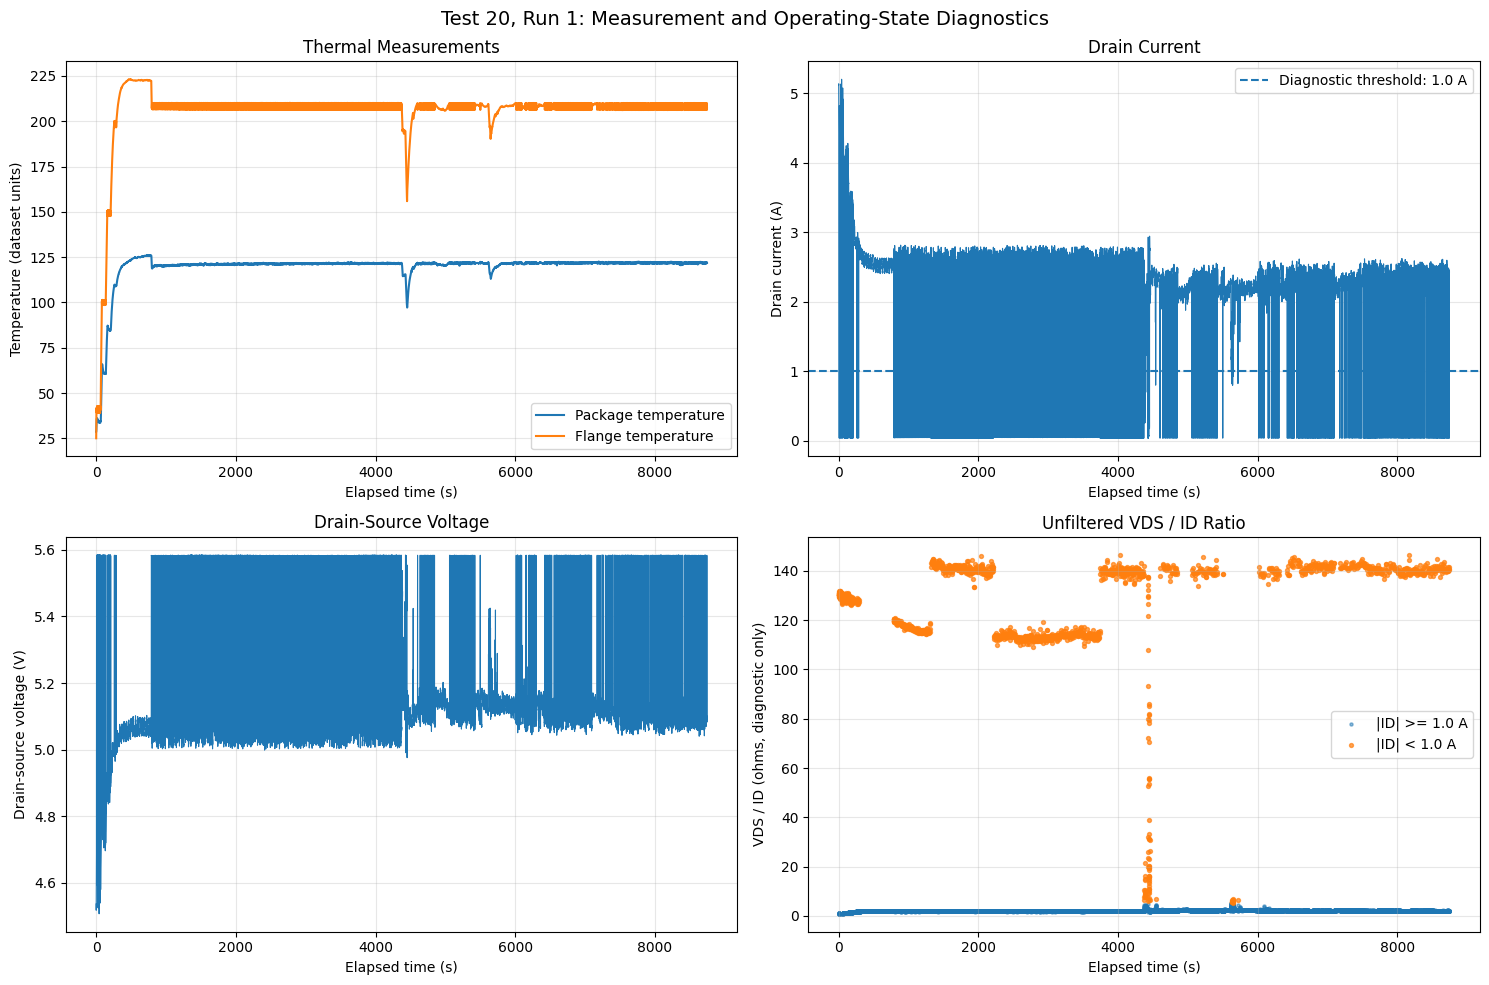

Records plotted: 21743
Low-current records: 1670
Elapsed-time range (s): 0.0 to 8745.755
Note: The current threshold is exploratory, and VDS/ID is not validated as RDS(on) for every operating point.
Original sample_df unchanged: True


In [14]:
# CELL 14: VISUALIZE THE RUN AND FLAG LOW-CURRENT OPERATING POINTS
# Exploratory plots only. No filtering or deletion of source records.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plot_df = sample_df.copy()

required_cols = [
    "timeEpoch",
    "packageTemperature",
    "flangeTemperature",
    "drainSourceVoltage",
    "drainCurrent"
]
missing_cols = [c for c in required_cols if c not in plot_df.columns]

if missing_cols:
    raise KeyError(f"Missing columns: {missing_cols}")

# Convert timeEpoch to elapsed seconds relative to the first record.
# This assumes timeEpoch is expressed in days, as suggested by its values.
epoch = pd.to_numeric(plot_df["timeEpoch"], errors="coerce")
plot_df["elapsed_seconds"] = (epoch - epoch.iloc[0]) * 86400.0

if epoch.isna().any():
    raise ValueError("timeEpoch contains invalid values.")

if not epoch.is_monotonic_increasing:
    print(
        "WARNING: timeEpoch is not monotonic. "
        "Inspect timestamp ordering before interpreting time trends."
    )

# Calculate the raw ratio for visualization only.
current = pd.to_numeric(plot_df["drainCurrent"], errors="coerce")
voltage = pd.to_numeric(plot_df["drainSourceVoltage"], errors="coerce")

plot_df["RDS_ratio_unfiltered"] = (
    voltage / current.where(current.abs() > 1e-9)
)

LOW_CURRENT_THRESHOLD_A = 1.0
plot_df["low_current_flag"] = (
    current.abs() < LOW_CURRENT_THRESHOLD_A
)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Thermal measurements
axes[0, 0].plot(
    plot_df["elapsed_seconds"],
    plot_df["packageTemperature"],
    label="Package temperature"
)
axes[0, 0].plot(
    plot_df["elapsed_seconds"],
    plot_df["flangeTemperature"],
    label="Flange temperature"
)
axes[0, 0].set_title("Thermal Measurements")
axes[0, 0].set_xlabel("Elapsed time (s)")
axes[0, 0].set_ylabel("Temperature (dataset units)")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Drain current
axes[0, 1].plot(
    plot_df["elapsed_seconds"],
    current,
    linewidth=0.8
)
axes[0, 1].axhline(
    LOW_CURRENT_THRESHOLD_A,
    linestyle="--",
    label=f"Diagnostic threshold: {LOW_CURRENT_THRESHOLD_A} A"
)
axes[0, 1].set_title("Drain Current")
axes[0, 1].set_xlabel("Elapsed time (s)")
axes[0, 1].set_ylabel("Drain current (A)")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Drain-source voltage
axes[1, 0].plot(
    plot_df["elapsed_seconds"],
    voltage,
    linewidth=0.8
)
axes[1, 0].set_title("Drain-Source Voltage")
axes[1, 0].set_xlabel("Elapsed time (s)")
axes[1, 0].set_ylabel("Drain-source voltage (V)")
axes[1, 0].grid(True, alpha=0.3)

# 4. Raw ratio, split by current flag
normal_current = ~plot_df["low_current_flag"]
low_current = plot_df["low_current_flag"]

axes[1, 1].scatter(
    plot_df.loc[normal_current, "elapsed_seconds"],
    plot_df.loc[normal_current, "RDS_ratio_unfiltered"],
    s=5,
    alpha=0.5,
    label=f"|ID| >= {LOW_CURRENT_THRESHOLD_A} A"
)
axes[1, 1].scatter(
    plot_df.loc[low_current, "elapsed_seconds"],
    plot_df.loc[low_current, "RDS_ratio_unfiltered"],
    s=8,
    alpha=0.7,
    label=f"|ID| < {LOW_CURRENT_THRESHOLD_A} A"
)
axes[1, 1].set_title("Unfiltered VDS / ID Ratio")
axes[1, 1].set_xlabel("Elapsed time (s)")
axes[1, 1].set_ylabel("VDS / ID (ohms, diagnostic only)")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle(
    "Test 20, Run 1: Measurement and Operating-State Diagnostics",
    fontsize=14
)
plt.tight_layout()
plt.show()

print("Records plotted:", len(plot_df))
print("Low-current records:", int(plot_df["low_current_flag"].sum()))
print(
    "Elapsed-time range (s):",
    round(plot_df["elapsed_seconds"].min(), 3),
    "to",
    round(plot_df["elapsed_seconds"].max(), 3)
)
print(
    "Note: The current threshold is exploratory, and VDS/ID is not "
    "validated as RDS(on) for every operating point."
)
print("Original sample_df unchanged:", "elapsed_seconds" not in sample_df.columns)


In [15]:
# CELL 15: Summarize test/run structure

valid_inventory = inventory_df[
    ~inventory_df["possible_setup_error"]
].copy()

run_summary = (
    valid_inventory
    .groupby("test_id")
    .agg(
        number_of_runs=("run_id", "nunique"),
        total_file_size_MB=("size_MB", "sum"),
        run_ids=("run_id", lambda x: sorted(x.dropna().astype(int).unique()))
    )
    .reset_index()
    .sort_values("test_id")
)

print("Valid MAT files:", len(valid_inventory))
print("Unique test IDs:", valid_inventory["test_id"].nunique())
print("Unique test/run pairs:", len(valid_inventory[["test_id", "run_id"]].drop_duplicates()))

print("\nRuns per test ID:")
display(run_summary)

print("\nFiles flagged as possible setup errors:")
display(
    inventory_df.loc[
        inventory_df["possible_setup_error"],
        ["filename", "test_id", "run_id", "size_MB"]
    ]
)

print("\nRun-count distribution:")
print(run_summary["number_of_runs"].value_counts().sort_index())

Valid MAT files: 105
Unique test IDs: 42
Unique test/run pairs: 105

Runs per test ID:


,test_id,number_of_runs,total_file_size_MB,run_ids
0,1.0,2,18.78,"[1, 2]"
1,2.0,3,47.73,"[1, 2, 3]"
2,3.0,1,123.76,[1]
3,4.0,2,127.60,"[1, 2]"
4,5.0,2,130.64,"[1, 2]"
5,6.0,2,252.20,"[1, 2]"
6,7.0,1,143.11,[1]
7,8.0,7,502.78,"[1, 2, 3, 4, 5, 6, 7]"
8,9.0,7,450.40,"[1, 2, 3, 4, 5, 6, 7]"
9,10.0,7,459.57,"[1, 2, 3, 4, 5, 6, 7]"



Files flagged as possible setup errors:


,filename,test_id,run_id,size_MB
21,Test_13_run_1 1 (error setting up this run).mat,13.0,1.0,0.56



Run-count distribution:
number_of_runs
1    20
2    11
3     2
4     1
5     2
7     6
Name: count, dtype: int64


In [16]:

# CELL 16: COMPARE THE TWO RUNS FOR TEST 20

import numpy as np
import pandas as pd
from scipy.io import loadmat
from IPython.display import display

# Select valid runs for Test 20
test20_rows = inventory_df.loc[
    (inventory_df["test_id"] == 20)
    & (~inventory_df["possible_setup_error"].astype(bool))
].sort_values("run_id")

test20_summary = []

for _, file_row in test20_rows.iterrows():

    mat = loadmat(str(file_row["path"]))

    # Preserve the original working MATLAB indexing
    steady = mat["measurement"]["steadyState"][0, 0]

    # Convert timestamps safely, handling nested NumPy arrays
    raw_epochs = np.asarray(steady["timeEpoch"]).reshape(-1)

    epochs = np.array(
        [numeric_scalar(value) for value in raw_epochs],
        dtype=float
    )

    # Extract all time-domain records
    td = steady["timeDomain"].reshape(-1)

    # Validate extraction
    if len(td) != len(epochs):
        raise ValueError(
            f"Run {int(file_row['run_id'])}: "
            f"{len(td)} records but {len(epochs)} timestamps."
        )

    if len(td) <= 1:
        raise ValueError(
            f"Run {int(file_row['run_id'])}: "
            f"only {len(td)} records extracted."
        )

    # Extract physical measurements
    temperatures = np.array([
        numeric_scalar(record["packageTemperature"])
        for record in td
    ], dtype=float)

    currents = np.array([
        numeric_scalar(record["drainCurrent"])
        for record in td
    ], dtype=float)

    voltages = np.array([
        numeric_scalar(record["drainSourceVoltage"])
        for record in td
    ], dtype=float)

    # Diagnostic current threshold, not a validated ON-state definition
    ratio_mask = (
        np.isfinite(currents)
        & np.isfinite(voltages)
        & (currents > 1.5)
    )

    ratios = voltages[ratio_mask] / currents[ratio_mask]

    # Timestamp and measurement summary
    test20_summary.append({
        "test_id": int(file_row["test_id"]),
        "run_id": int(file_row["run_id"]),
        "records": len(td),
        "finite_epochs": int(np.isfinite(epochs).sum()),
        "timestamps_monotonic": bool(
            np.all(np.diff(epochs) >= 0)
        ),
        "start_epoch": float(np.min(epochs)),
        "end_epoch": float(np.max(epochs)),
        "temperature_min": float(np.nanmin(temperatures)),
        "temperature_median": float(np.nanmedian(temperatures)),
        "temperature_max": float(np.nanmax(temperatures)),
        "current_median": float(np.nanmedian(currents)),
        "records_current_gt_1_5_A": int(ratio_mask.sum()),
        "RDS_ratio_median_gt_1_5_A": (
            float(np.nanmedian(ratios))
            if len(ratios) > 0
            else np.nan
        )
    })

    del mat, steady, td

# Build and display results
test20_df = pd.DataFrame(test20_summary)

print("Test 20 runs found:", len(test20_df))
display(test20_df)

# Validation checks
assert len(test20_df) == len(test20_rows), (
    "Some Test 20 runs were not summarized."
)

assert (test20_df["records"] > 1).all(), (
    "Extraction returned only one record for at least one run."
)

assert (
    test20_df["finite_epochs"] == test20_df["records"]
).all(), "Some timestamps are non-finite."

assert test20_df["timestamps_monotonic"].all(), (
    "At least one run has non-monotonic timestamps."
)

print("\nRecord counts by run:")
print(test20_df.set_index("run_id")["records"].to_dict())

print("\nTimestamp monotonicity by run:")
print(test20_df.set_index("run_id")["timestamps_monotonic"].to_dict())

print("\nRatio threshold: drainCurrent > 1.5 A")
print(
    "IMPORTANT: VDS/ID is an exploratory ratio, "
    "not yet a validated RDS(on) aging target."
)

print("\nCELL 16 VALIDATION: PASSED")

Test 20 runs found: 2


,test_id,run_id,records,finite_epochs,timestamps_monotonic,start_epoch,end_epoch,temperature_min,temperature_median,temperature_max,current_median,records_current_gt_1_5_A,RDS_ratio_median_gt_1_5_A
0,20,1,21743,21743,True,734339.402956,734339.504180,28.540243,121.460798,126.149402,2.475461,20010,2.028895
1,20,2,21078,21078,True,734339.692347,734339.790208,29.773547,121.921871,123.813438,2.291725,16820,2.137667



Record counts by run:
{1: 21743, 2: 21078}

Timestamp monotonicity by run:
{1: True, 2: True}

Ratio threshold: drainCurrent > 1.5 A
IMPORTANT: VDS/ID is an exploratory ratio, not yet a validated RDS(on) aging target.

CELL 16 VALIDATION: PASSED


In [17]:
# CELL 17: TIMESTAMP RANGES ACROSS MULTI-RUN TESTS

import numpy as np
import pandas as pd
from scipy.io import loadmat
from IPython.display import display

# Identify tests containing more than one run
multi_run_ids = (
    run_summary.loc[
        run_summary["number_of_runs"] > 1, "test_id"
    ]
    .astype(int)
    .tolist()
)

timeline_records = []

# Process valid runs in test/run order
multi_run_inventory = (
    valid_inventory.loc[
        valid_inventory["test_id"].isin(multi_run_ids)
    ]
    .sort_values(["test_id", "run_id"])
)

for _, file_row in multi_run_inventory.iterrows():

    mat = loadmat(str(file_row["path"]))
    steady = mat["measurement"]["steadyState"][0, 0]

    # Convert timestamps safely to avoid NumPy scalar-conversion warnings
    raw_epochs = np.asarray(steady["timeEpoch"]).reshape(-1)

    epochs = np.array(
        [numeric_scalar(value) for value in raw_epochs],
        dtype=float
    )

    td = steady["timeDomain"].reshape(-1)

    # Validate timestamp and record counts
    if len(epochs) != len(td):
        raise ValueError(
            f"Test {int(file_row['test_id'])}, "
            f"run {int(file_row['run_id'])}: "
            f"{len(epochs)} timestamps but {len(td)} records."
        )

    if len(epochs) == 0:
        raise ValueError(
            f"Test {int(file_row['test_id'])}, "
            f"run {int(file_row['run_id'])}: no timestamps found."
        )

    if not np.isfinite(epochs).all():
        raise ValueError(
            f"Test {int(file_row['test_id'])}, "
            f"run {int(file_row['run_id'])}: non-finite timestamps found."
        )

    if not np.all(np.diff(epochs) >= 0):
        print(
            f"WARNING: timestamps are not monotonic for "
            f"Test {int(file_row['test_id'])}, "
            f"run {int(file_row['run_id'])}."
        )

    start_epoch = float(np.min(epochs))
    end_epoch = float(np.max(epochs))

    timeline_records.append({
        "test_id": int(file_row["test_id"]),
        "run_id": int(file_row["run_id"]),
        "records": len(td),
        "start_epoch": start_epoch,
        "end_epoch": end_epoch,
        "duration_seconds": (end_epoch - start_epoch) * 86400
    })

    del mat, steady, td, epochs, raw_epochs

# Build timeline table
timeline_df = pd.DataFrame(timeline_records)

if not timeline_df.empty:

    timeline_df = timeline_df.sort_values(
        ["test_id", "run_id"]
    ).reset_index(drop=True)

    # Compare each run with the previous run of the same test
    timeline_df["previous_run_end"] = (
        timeline_df.groupby("test_id")["end_epoch"].shift(1)
    )

    timeline_df["gap_from_previous_seconds"] = (
        timeline_df["start_epoch"] - timeline_df["previous_run_end"]
    ) * 86400

    timeline_df["timeline_relation"] = np.select(
        [
            timeline_df["gap_from_previous_seconds"].isna(),
            timeline_df["gap_from_previous_seconds"] > 0,
            timeline_df["gap_from_previous_seconds"] < 0
        ],
        [
            "First run in test",
            "Positive gap",
            "Overlapping/reversed timestamps"
        ],
        default="Touching timestamps"
    )

    display(timeline_df)

    print("\nTimeline audit summary")
    print("Multi-run tests:", len(multi_run_ids))
    print("Runs examined:", len(timeline_df))
    print(
        "Runs with positive gaps:",
        int((timeline_df["gap_from_previous_seconds"] > 0).sum())
    )
    print(
        "Runs with overlapping/reversed timestamps:",
        int((timeline_df["gap_from_previous_seconds"] < 0).sum())
    )

else:
    print("No valid runs found for multi-run tests.")

print(
    "\nNOTE: Duration and gap calculations assume timeEpoch is measured "
    "in days. This assumption must be verified against the dataset's "
    "timestamp definition before using these values in the research."
)


,test_id,run_id,records,start_epoch,end_epoch,duration_seconds,previous_run_end,gap_from_previous_seconds,timeline_relation
0,1,1,1062,734186.739922,734186.744882,428.526996,NaN,NaN,First run in test
1,1,2,2335,734187.425866,734187.436841,948.204000,734186.744882,58837.020002,Positive gap
2,2,1,2981,734187.646426,734187.660239,1193.415997,NaN,NaN,First run in test
3,2,2,1111,734187.666893,734187.672032,444.018000,734187.660239,574.890002,Positive gap
4,2,3,3548,734187.684656,734187.701106,1421.285994,734187.672032,1090.694004,Positive gap
...,...,...,...,...,...,...,...,...,...
79,34,1,70658,734360.910652,734361.243979,28799.418001,NaN,NaN,First run in test
80,34,2,70843,734361.691049,734362.024374,28799.287002,734361.243979,38626.807002,Positive gap
81,34,3,65915,734362.513198,734362.823789,26835.019996,734362.024374,42234.432998,Positive gap
82,40,1,1940,734374.884140,734374.893119,775.778009,NaN,NaN,First run in test



Timeline audit summary
Multi-run tests: 22
Runs examined: 84
Runs with positive gaps: 62
Runs with overlapping/reversed timestamps: 0

NOTE: Duration and gap calculations assume timeEpoch is measured in days. This assumption must be verified against the dataset's timestamp definition before using these values in the research.


CELL 18: RESISTANCE-PROXY COMPARISON
------------------------------------------------
Total records: 21743
Records with valid positive-current ratio: 21743
Records passing current screen (> 1.5 A): 20010
Percentage retained: 92.03%

All-record ratio quantiles (VDS/ID):
0.00      0.866240
0.50      2.050048
0.90      2.472918
0.95    120.962332
0.99    141.473714
1.00    146.528673
dtype: float64

Current-screened ratio quantiles (VDS/ID):
0.00    0.866240
0.50    2.028895
0.90    2.314986
0.95    2.401366
0.99    2.535611
1.00    3.509390
dtype: float64


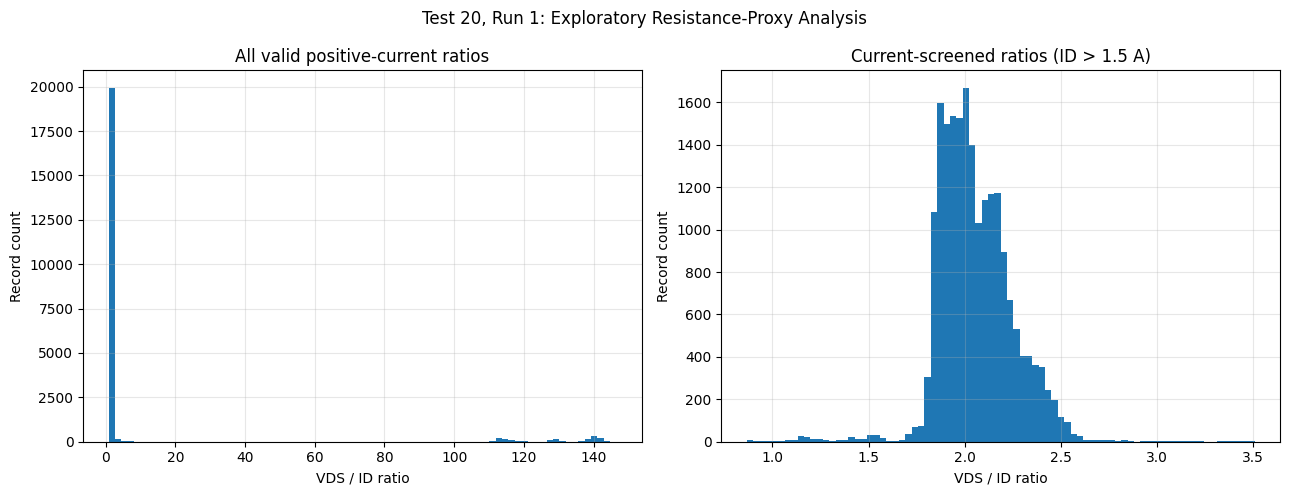


INTERPRETATION NOTE: VDS/ID is an exploratory ratio. The current threshold does not by itself establish the MOSFET ON-state or validate RDS(on) as an aging target.
Original sample_df remains unchanged.


In [18]:
# CELL 18: COMPARE UNFILTERED AND CURRENT-SCREENED RESISTANCE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_threshold = 1.5  # Exploratory threshold in amperes

required_columns = [
    "drainSourceVoltage",
    "drainCurrent"
]

missing_columns = [
    col for col in required_columns
    if col not in sample_df.columns
]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

# Convert measurements to numeric arrays without modifying sample_df
vds = pd.to_numeric(
    sample_df["drainSourceVoltage"], errors="coerce"
).to_numpy(dtype=float)

ids = pd.to_numeric(
    sample_df["drainCurrent"], errors="coerce"
).to_numpy(dtype=float)

# Unfiltered exploratory VDS/ID ratio
# Exclude zero current and non-finite measurements from division
valid_for_ratio = (
    np.isfinite(vds)
    & np.isfinite(ids)
    & (ids > 0)
)

rds_all = np.full(len(sample_df), np.nan, dtype=float)
rds_all[valid_for_ratio] = (
    vds[valid_for_ratio] / ids[valid_for_ratio]
)

# Exploratory current screen
valid_on_proxy = (
    np.isfinite(vds)
    & np.isfinite(ids)
    & (ids > current_threshold)
    & (vds > 0)
)

rds_screened = vds[valid_on_proxy] / ids[valid_on_proxy]

print("CELL 18: RESISTANCE-PROXY COMPARISON")
print("-" * 48)
print(f"Total records: {len(sample_df)}")
print(f"Records with valid positive-current ratio: {valid_for_ratio.sum()}")
print(f"Records passing current screen (> {current_threshold} A): {valid_on_proxy.sum()}")
print(f"Percentage retained: {100 * valid_on_proxy.mean():.2f}%")

print("\nAll-record ratio quantiles (VDS/ID):")
print(
    pd.Series(rds_all).replace([np.inf, -np.inf], np.nan)
    .dropna()
    .quantile([0, 0.5, 0.9, 0.95, 0.99, 1.0])
)

print("\nCurrent-screened ratio quantiles (VDS/ID):")
print(
    pd.Series(rds_screened)
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .quantile([0, 0.5, 0.9, 0.95, 0.99, 1.0])
)

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

all_values = rds_all[np.isfinite(rds_all)]
screened_values = rds_screened[np.isfinite(rds_screened)]

if len(all_values):
    axes[0].hist(all_values, bins=80)
    axes[0].set_title("All valid positive-current ratios")
    axes[0].set_xlabel("VDS / ID ratio")
    axes[0].set_ylabel("Record count")
    axes[0].grid(True, alpha=0.3)

if len(screened_values):
    axes[1].hist(screened_values, bins=80)
    axes[1].set_title(f"Current-screened ratios (ID > {current_threshold} A)")
    axes[1].set_xlabel("VDS / ID ratio")
    axes[1].set_ylabel("Record count")
    axes[1].grid(True, alpha=0.3)

plt.suptitle("Test 20, Run 1: Exploratory Resistance-Proxy Analysis")
plt.tight_layout()
plt.show()

print(
    "\nINTERPRETATION NOTE: VDS/ID is an exploratory ratio. "
    "The current threshold does not by itself establish the MOSFET "
    "ON-state or validate RDS(on) as an aging target."
)
print("Original sample_df remains unchanged.")


In [19]:

# CELL 19A: VERIFY NESTED MATLAB ARRAY DIMENSIONS

import numpy as np
from scipy.io import loadmat

# Locate Test 20, Run 1
check_rows = inventory_df.loc[
    (inventory_df["test_id"] == 20)
    & (inventory_df["run_id"] == 1)
    & (~inventory_df["possible_setup_error"].astype(bool))
]

if check_rows.empty:
    raise ValueError("Test 20, Run 1 was not found in valid inventory.")

check_row = check_rows.iloc[0]
check_mat = loadmat(str(check_row["path"]))

# Preserve the original working MATLAB indexing
check_measurement = check_mat["measurement"]
check_steady = check_measurement["steadyState"][0, 0]
check_td = check_steady["timeDomain"]
check_epochs = np.asarray(check_steady["timeEpoch"]).reshape(-1)

print("measurement shape:", check_measurement.shape)
print(
    "steadyState shape:",
    check_measurement["steadyState"].shape
)
print("timeDomain shape:", check_td.shape)
print("timeDomain record count:", check_td.size)
print("timeEpoch array shape:", check_steady["timeEpoch"].shape)
print("Flattened timeEpoch count:", check_epochs.size)
print("Expected records from Cell 16: 21743")

# Structural validation
assert check_td.size == 21743, (
    f"Expected 21743 records, found {check_td.size}."
)

assert check_epochs.size == check_td.size, (
    f"Record/timestamp mismatch: "
    f"{check_td.size} records vs {check_epochs.size} timestamps."
)

print("\nCELL 19A STRUCTURAL VALIDATION: PASSED")


measurement shape: (1, 1)
steadyState shape: (1, 1)
timeDomain shape: (1, 21743)
timeDomain record count: 21743
timeEpoch array shape: (1, 21743)
Flattened timeEpoch count: 21743
Expected records from Cell 16: 21743

CELL 19A STRUCTURAL VALIDATION: PASSED


In [20]:
# CELL 19B: EXTRACT RUN-LEVEL FEATURES FROM NESTED MATLAB ARRAYS 

import numpy as np
import pandas as pd
from scipy.io import loadmat
from IPython.display import display

run_feature_rows = []
skipped_runs = []

processable_inventory = (
    valid_inventory
    .dropna(subset=["test_id", "run_id"])
    .copy()
)

fields = [
    "supplyVoltage",
    "packageTemperature",
    "drainSourceVoltage",
    "drainCurrent",
    "flangeTemperature"
]

CURRENT_THRESHOLD = 1.5  # Exploratory threshold, in amperes


def extract_record_scalar(record, field):
    """Safely unwrap a MATLAB structured field into one float."""
    value = np.asarray(record[field]).squeeze()

    while isinstance(value, np.ndarray) and value.dtype == object:
        if value.size != 1:
            return np.nan
        value = np.asarray(value.item()).squeeze()

    if np.asarray(value).size != 1:
        return np.nan

    try:
        return float(np.asarray(value).reshape(-1)[0])
    except (TypeError, ValueError, OverflowError):
        return np.nan


for idx, (_, file_row) in enumerate(
    processable_inventory.iterrows(), start=1
):
    mat = None

    try:
        mat = loadmat(str(file_row["path"]))

        measurement = mat["measurement"]
        steady = measurement["steadyState"][0, 0]
        td = steady["timeDomain"].reshape(-1)

        n = len(td)

        raw_epochs = np.asarray(
            steady["timeEpoch"]
        ).reshape(-1)

        epochs = np.array(
            [extract_record_scalar(
                {"value": value}, "value"
            ) for value in raw_epochs],
            dtype=float
        )

        if n == 0:
            raise ValueError("No time-domain records found.")

        if len(epochs) != n:
            raise ValueError(
                f"Timestamp count {len(epochs)} "
                f"does not match record count {n}."
            )

        if not np.isfinite(epochs).all():
            raise ValueError("Non-finite timestamps found.")

        values = {
            field: np.full(n, np.nan, dtype=float)
            for field in fields
        }

        for i, wrapped_record in enumerate(td):
            record = np.asarray(wrapped_record).squeeze()

            while (
                isinstance(record, np.ndarray)
                and record.dtype.names is None
                and record.size == 1
            ):
                record = record.item()

            if getattr(
                getattr(record, "dtype", None), "names", None
            ) is None:
                raise ValueError(
                    f"Unexpected record structure at index {i}."
                )

            for field in fields:
                values[field][i] = extract_record_scalar(
                    record, field
                )

        current = values["drainCurrent"]
        voltage = values["drainSourceVoltage"]

        current_ok = (
            np.isfinite(current)
            & np.isfinite(voltage)
            & (current > CURRENT_THRESHOLD)
            & (voltage > 0)
        )

        rds_proxy = voltage[current_ok] / current[current_ok]

        run_feature_rows.append({
            "filename": file_row["filename"],
            "test_id": int(file_row["test_id"]),
            "run_id": int(file_row["run_id"]),
            "records": n,
            "start_epoch": float(epochs.min()),
            "end_epoch": float(epochs.max()),
            "duration_seconds": float(
                (epochs.max() - epochs.min()) * 86400
            ),
            "timestamps_monotonic": bool(
                np.all(np.diff(epochs) >= 0)
            ),
            "valid_proxy_count": int(current_ok.sum()),
            "valid_proxy_fraction": float(current_ok.mean()),
            "RDS_proxy_median": (
                float(np.median(rds_proxy))
                if len(rds_proxy) else np.nan
            ),
            "RDS_proxy_p90": (
                float(np.quantile(rds_proxy, 0.90))
                if len(rds_proxy) else np.nan
            ),
            "package_temp_median": float(
                np.nanmedian(values["packageTemperature"])
            ),
            "flange_temp_median": float(
                np.nanmedian(values["flangeTemperature"])
            ),
            "drain_current_median": float(
                np.nanmedian(current)
            ),
            "invalid_package_temp_count": int(
                (~np.isfinite(values["packageTemperature"])).sum()
            ),
            "invalid_current_count": int(
                (~np.isfinite(current)).sum()
            ),
            "invalid_voltage_count": int(
                (~np.isfinite(voltage)).sum()
            )
        })

    except Exception as exc:
        skipped_runs.append({
            "filename": file_row["filename"],
            "test_id": file_row["test_id"],
            "run_id": file_row["run_id"],
            "reason": repr(exc)
        })

    finally:
        if mat is not None:
            del mat

    if idx % 10 == 0 or idx == len(processable_inventory):
        print(
            f"Processed {idx}/{len(processable_inventory)} files"
        )

run_features_df = pd.DataFrame(run_feature_rows)

print("\nSuccessfully processed:", len(run_features_df))
print("Skipped:", len(skipped_runs))

if skipped_runs:
    print("\nSkipped-run details:")
    display(pd.DataFrame(skipped_runs))

if not run_features_df.empty:
    print("\nRecord-count distribution:")
    display(run_features_df["records"].describe())

    print("\nTimestamp monotonicity:")
    display(
        run_features_df["timestamps_monotonic"].value_counts(
            dropna=False
        ).rename_axis("monotonic").to_frame("run_count")
    )

    print("\nInvalid measurement counts across runs:")
    display(
        run_features_df[
            [
                "invalid_package_temp_count",
                "invalid_current_count",
                "invalid_voltage_count"
            ]
        ].sum().to_frame("total_invalid_values")
    )

    print("\nTest 20, Run 1 verification:")
    display(
        run_features_df.loc[
            (run_features_df["test_id"] == 20)
            & (run_features_df["run_id"] == 1)
        ]
    )

print(
    "\nNOTE: VDS/ID remains an exploratory resistance proxy. "
    "Timestamp durations assume timeEpoch is measured in days."
)


Processed 10/104 files
Processed 20/104 files
Processed 30/104 files
Processed 40/104 files
Processed 50/104 files
Processed 60/104 files
Processed 70/104 files
Processed 80/104 files
Processed 90/104 files
Processed 100/104 files
Processed 104/104 files

Successfully processed: 104
Skipped: 0

Record-count distribution:


count      104.000000
mean     18265.000000
std      19535.450489
min         29.000000
25%       5071.750000
50%       5278.000000
75%      31753.000000
max      71045.000000
Name: records, dtype: float64


Timestamp monotonicity:


,run_count
monotonic,
True,104



Invalid measurement counts across runs:


,total_invalid_values
invalid_package_temp_count,0
invalid_current_count,0
invalid_voltage_count,0



Test 20, Run 1 verification:


,filename,test_id,run_id,records,start_epoch,end_epoch,duration_seconds,timestamps_monotonic,valid_proxy_count,valid_proxy_fraction,RDS_proxy_median,RDS_proxy_p90,package_temp_median,flange_temp_median,drain_current_median,invalid_package_temp_count,invalid_current_count,invalid_voltage_count
42,Test_20_run_1.mat,20,1,21743,734339.402956,734339.50418,8745.755007,True,20010,0.920296,2.028895,2.314986,121.460798,208.885633,2.475461,0,0,0



NOTE: VDS/ID remains an exploratory resistance proxy. Timestamp durations assume timeEpoch is measured in days.


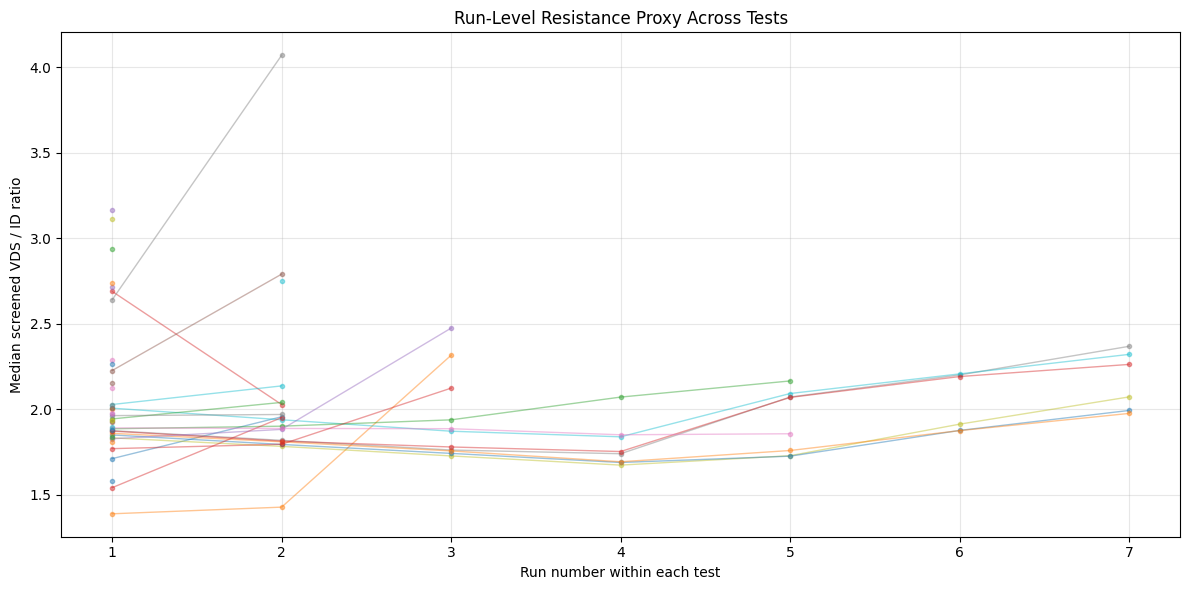

Tests represented: 42
Runs represented: 100
Median records per run: 5425.0
Minimum run-level proxy median: 1.3899861634473683
Maximum run-level proxy median: 4.070542100661029

INTERPRETATION NOTE: Lines connect runs by run_id for visualization. They do not establish chronological aging progression. VDS/ID remains an exploratory resistance proxy.


In [21]:
# CELL 19C: RUN-LEVEL RESISTANCE-PROXY VISUALIZATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Keep runs with a valid resistance-proxy median
plot_runs = run_features_df.dropna(
    subset=["RDS_proxy_median"]
).copy()

if plot_runs.empty:
    raise ValueError(
        "No runs contain a valid resistance-proxy median."
    )

plot_runs = plot_runs.sort_values(["test_id", "run_id"])

# Plot individual run-level medians.
# Lines connect runs within each test for visual comparison only.
plt.figure(figsize=(12, 6))

for test_id, group in plot_runs.groupby("test_id"):
    group = group.sort_values("run_id")

    plt.plot(
        group["run_id"],
        group["RDS_proxy_median"],
        marker="o",
        markersize=3,
        linewidth=1,
        alpha=0.45
    )

plt.xlabel("Run number within each test")
plt.ylabel("Median screened VDS / ID ratio")
plt.title("Run-Level Resistance Proxy Across Tests")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Summary diagnostics
print("Tests represented:", plot_runs["test_id"].nunique())
print("Runs represented:", len(plot_runs))
print("Median records per run:", plot_runs["records"].median())
print("Minimum run-level proxy median:",
      plot_runs["RDS_proxy_median"].min())
print("Maximum run-level proxy median:",
      plot_runs["RDS_proxy_median"].max())

print(
    "\nINTERPRETATION NOTE: Lines connect runs by run_id for visualization. "
    "They do not establish chronological aging progression. "
    "VDS/ID remains an exploratory resistance proxy."
)


In [22]:

# CELL 19D: AUDIT RUNS EXCLUDED FROM THE PROXY PLOT

missing_proxy_runs = run_features_df.loc[
    run_features_df["RDS_proxy_median"].isna(),
    [
        "filename",
        "test_id",
        "run_id",
        "records",
        "valid_proxy_count",
        "valid_proxy_fraction"
    ]
].copy()

print("Total extracted runs:", len(run_features_df))
print(
    "Runs with valid proxy median:",
    int(run_features_df["RDS_proxy_median"].notna().sum())
)
print("Runs missing proxy median:", len(missing_proxy_runs))

if not missing_proxy_runs.empty:
    display(missing_proxy_runs)
else:
    print("All runs have a valid proxy median.")


Total extracted runs: 104
Runs with valid proxy median: 100
Runs missing proxy median: 4


,filename,test_id,run_id,records,valid_proxy_count,valid_proxy_fraction
39,Test_19_run_2.mat,19,2,250,0,0.0
53,Test_25_run_4.mat,25,4,29,0,0.0
79,Test_40_run_1.mat,40,1,1940,0,0.0
86,Test_5_run_2.mat,5,2,210,0,0.0


In [23]:

# CELL 19E: DIAGNOSE RUNS WITH ZERO SCREENED PROXY RECORDS

import numpy as np
import pandas as pd
from scipy.io import loadmat
from IPython.display import display

zero_proxy_runs = run_features_df.loc[
    run_features_df["valid_proxy_count"].eq(0),
    ["filename", "test_id", "run_id", "records"]
]

diagnostic_rows = []

for _, row in zero_proxy_runs.iterrows():
    file_row = valid_inventory.loc[
        valid_inventory["filename"].eq(row["filename"])
    ]

    if file_row.empty:
        print("File not found in valid_inventory:", row["filename"])
        continue

    mat = loadmat(str(file_row.iloc[0]["path"]))
    steady = mat["measurement"]["steadyState"][0, 0]
    td = steady["timeDomain"].reshape(-1)

    currents = np.array([
        extract_record_scalar(record, "drainCurrent")
        for record in td
    ], dtype=float)

    voltages = np.array([
        extract_record_scalar(record, "drainSourceVoltage")
        for record in td
    ], dtype=float)

    finite = np.isfinite(currents) & np.isfinite(voltages)
    current_finite = currents[finite]
    voltage_finite = voltages[finite]

    diagnostic_rows.append({
        "filename": row["filename"],
        "test_id": int(row["test_id"]),
        "run_id": int(row["run_id"]),
        "records": len(td),
        "finite_pairs": int(finite.sum()),
        "current_min_A": (
            float(current_finite.min()) if len(current_finite) else np.nan
        ),
        "current_median_A": (
            float(np.median(current_finite)) if len(current_finite) else np.nan
        ),
        "current_max_A": (
            float(current_finite.max()) if len(current_finite) else np.nan
        ),
        "voltage_min_V": (
            float(voltage_finite.min()) if len(voltage_finite) else np.nan
        ),
        "voltage_median_V": (
            float(np.median(voltage_finite)) if len(voltage_finite) else np.nan
        ),
        "voltage_max_V": (
            float(voltage_finite.max()) if len(voltage_finite) else np.nan
        ),
        "records_current_gt_1_5_A": int(
            (finite & (currents > 1.5) & (voltages > 0)).sum()
        )
    })

    del mat, steady, td

zero_proxy_diagnostics_df = pd.DataFrame(diagnostic_rows)
display(zero_proxy_diagnostics_df)


,filename,test_id,run_id,records,finite_pairs,current_min_A,current_median_A,current_max_A,voltage_min_V,voltage_median_V,voltage_max_V,records_current_gt_1_5_A
0,Test_19_run_2.mat,19,2,250,250,0.052437,0.057897,0.099504,5.569760,5.578834,5.581559,0
1,Test_25_run_4.mat,25,4,29,29,0.029195,0.030015,0.030835,5.580037,5.582444,5.583454,0
2,Test_40_run_1.mat,40,1,1940,1940,0.061522,0.412732,1.083310,1.114542,5.493087,5.853351,0
3,Test_5_run_2.mat,5,2,210,210,0.055458,0.057465,0.059796,5.579014,5.580929,5.582610,0


In [24]:
# CELL 22: Inspect suspicious run-level temperatures

print("Lowest flange-temperature medians:")
display(
    run_features_df.nsmallest(10, "flange_temp_median")[
        ["filename", "test_id", "run_id",
         "flange_temp_median", "package_temp_median"]
    ]
)

print("\nHighest flange-temperature medians:")
display(
    run_features_df.nlargest(10, "flange_temp_median")[
        ["filename", "test_id", "run_id",
         "flange_temp_median", "package_temp_median"]
    ]
)

print("\nRun summaries with non-positive flange-temperature medians:")
display(
    run_features_df[
        run_features_df["flange_temp_median"] <= 0
    ][
        ["filename", "test_id", "run_id",
         "flange_temp_median", "package_temp_median"]
    ]
)

Lowest flange-temperature medians:


,filename,test_id,run_id,flange_temp_median,package_temp_median
40,Test_1_run_1.mat,1,1,-2279.084208,138.824228
41,Test_1_run_2.mat,1,2,-2272.471786,102.530411
76,Test_38_run_1.mat,38,1,25.158997,30.205478
39,Test_19_run_2.mat,19,2,25.581208,29.097642
53,Test_25_run_4.mat,25,4,25.727901,30.121294
88,Test_6_run_2.mat,6,2,26.550692,30.372876
86,Test_5_run_2.mat,5,2,27.531150,30.816464
68,Test_32_run_1.mat,32,1,30.239464,31.376777
62,Test_29_run_1.mat,29,1,36.120061,35.981834
84,Test_4_run_2.mat,4,2,46.667796,38.593983



Highest flange-temperature medians:


,filename,test_id,run_id,flange_temp_median,package_temp_median
78,Test_3_run_1.mat,3,1,303.982066,184.163616
83,Test_4_run_1.mat,4,1,302.611117,171.998080
89,Test_7_run_1.mat,7,1,274.768395,171.005022
85,Test_5_run_1.mat,5,1,269.798143,176.718993
75,Test_37_run_1.mat,37,1,248.737373,119.189753
81,Test_41_run_1.mat,41,1,248.561795,120.668167
7,Test_11_run_1.mat,11,1,248.134383,150.017894
14,Test_12_run_1.mat,12,1,247.897872,151.570861
26,Test_14_run_1.mat,14,1,247.620047,152.571932
21,Test_13_run_1.mat,13,1,247.478045,119.049230



Run summaries with non-positive flange-temperature medians:


,filename,test_id,run_id,flange_temp_median,package_temp_median
40,Test_1_run_1.mat,1,1,-2279.084208,138.824228
41,Test_1_run_2.mat,1,2,-2272.471786,102.530411


In [25]:
# CELL 23: Inspect flange temperature values in Test 1, Run 1

row = inventory_df[
    (inventory_df["test_id"] == 1)
    & (inventory_df["run_id"] == 1)
    & (~inventory_df["possible_setup_error"])
].iloc[0]

mat = loadmat(row["path"])
steady = mat["measurement"]["steadyState"][0, 0]
td = steady["timeDomain"]

print("File:", row["filename"])
print("Number of steady-state records:", td.size)
print("First five raw flange-temperature values:")

for i, wrapped_record in enumerate(td.flat[:5]):
    record = np.asarray(wrapped_record).squeeze()

    while (
        isinstance(record, np.ndarray)
        and record.dtype.names is None
        and record.size == 1
    ):
        record = record.item()

    print(i, repr(record["flangeTemperature"]))

print("\nFirst five extracted values:")
print([
    extract_record_scalar(
        np.asarray(wrapped_record).squeeze().item()
        if np.asarray(wrapped_record).squeeze().dtype.names is None
        else np.asarray(wrapped_record).squeeze(),
        "flangeTemperature"
    )
    for wrapped_record in td.flat[:5]
])

File: Test_1_run_1.mat
Number of steady-state records: 1062
First five raw flange-temperature values:
0 array(array([[-2279.39784363]]), dtype=object)
1 array(array([[-2279.41251204]]), dtype=object)
2 array(array([[-2279.40348512]]), dtype=object)
3 array(array([[-2279.37527596]]), dtype=object)
4 array(array([[-2279.40799735]]), dtype=object)

First five extracted values:
[-2279.397843633576, -2279.412512042979, -2279.403485123217, -2279.3752759596023, -2279.407997350639]


In [26]:
# CELL 24: Compare raw temperature fields across selected tests

def extract_temperature_summary(filename):
    row = inventory_df[inventory_df["filename"] == filename].iloc[0]
    mat = loadmat(row["path"])
    steady = mat["measurement"]["steadyState"][0, 0]
    td = steady["timeDomain"]

    package_values = []
    flange_values = []

    for wrapped_record in td.flat:
        record = np.asarray(wrapped_record).squeeze()
        while (
            isinstance(record, np.ndarray)
            and record.dtype.names is None
            and record.size == 1
        ):
            record = record.item()

        package_values.append(
            extract_record_scalar(record, "packageTemperature")
        )
        flange_values.append(
            extract_record_scalar(record, "flangeTemperature")
        )

    return {
        "filename": filename,
        "package_min": np.nanmin(package_values),
        "package_median": np.nanmedian(package_values),
        "package_max": np.nanmax(package_values),
        "flange_min": np.nanmin(flange_values),
        "flange_median": np.nanmedian(flange_values),
        "flange_max": np.nanmax(flange_values),
    }

display(pd.DataFrame([
    extract_temperature_summary("Test_1_run_1.mat"),
    extract_temperature_summary("Test_1_run_2.mat"),
    extract_temperature_summary("Test_3_run_1.mat"),
    extract_temperature_summary("Test_20_run_1.mat"),
]))

,filename,package_min,package_median,package_max,flange_min,flange_median,flange_max
0,Test_1_run_1.mat,32.242259,138.824228,162.300950,-2279.691271,-2279.084208,-2278.224991
1,Test_1_run_2.mat,33.772151,102.530411,250.451021,-2272.907215,-2272.471786,-2271.462546
2,Test_3_run_1.mat,30.912790,184.163616,200.797930,26.605065,303.982066,340.167737
3,Test_20_run_1.mat,28.540243,121.460798,126.149402,25.048969,208.885633,223.145604


In [27]:
# CELL 25: Inspect ramp-up file structure and measurement ranges

ramp_path = next(
    Path(DATASET_DIR).rglob("test_rampup.mat")
)

ramp_mat = loadmat(str(ramp_path))

print("Ramp-up file:", ramp_path.name)
print("Top-level MATLAB keys:", [
    key for key in ramp_mat.keys() if not key.startswith("__")
])

if "measurement" in ramp_mat:
    ramp_measurement = ramp_mat["measurement"]
    print("Measurement shape:", ramp_measurement.shape)
    print("Measurement fields:", ramp_measurement.dtype.names)

    if ramp_measurement.dtype.names:
        for field in ramp_measurement.dtype.names:
            print(field, "shape:", ramp_measurement[field].shape)
else:
    print("No top-level 'measurement' variable found.")

Ramp-up file: test_rampup.mat
Top-level MATLAB keys: ['measurement']
Measurement shape: (1, 1)
Measurement fields: ('pwmTempControllerState', 'transient', 'steadyState')
pwmTempControllerState shape: (1, 1)
transient shape: (1, 1)
steadyState shape: (1, 1)


In [28]:
# CELL 26: Run-level quality-control flags

qc_df = run_features_df.copy()

qc_df["flag_flange_nonpositive"] = (
    qc_df["flange_temp_median"] <= 0
)

qc_df["flag_flange_extreme"] = (
    (qc_df["flange_temp_median"] < -100)
    | (qc_df["flange_temp_median"] > 350)
)

qc_df["flag_package_temp_extreme"] = (
    (qc_df["package_temp_median"] < -50)
    | (qc_df["package_temp_median"] > 250)
)

qc_df["flag_low_proxy_coverage"] = (
    qc_df["valid_proxy_fraction"] < 0.80
)

flag_columns = [
    "flag_flange_nonpositive",
    "flag_flange_extreme",
    "flag_package_temp_extreme",
    "flag_low_proxy_coverage"
]

print("QC flag counts:")
display(qc_df[flag_columns].sum().to_frame("number_of_runs"))

print("\nRuns requiring investigation:")
display(
    qc_df[qc_df[flag_columns].any(axis=1)][
        [
            "filename", "test_id", "run_id",
            "flange_temp_median", "package_temp_median",
            "valid_proxy_fraction"
        ] + flag_columns
    ]
)

QC flag counts:


,number_of_runs
flag_flange_nonpositive,2
flag_flange_extreme,2
flag_package_temp_extreme,0
flag_low_proxy_coverage,100



Runs requiring investigation:


,filename,test_id,run_id,flange_temp_median,package_temp_median,valid_proxy_fraction,flag_flange_nonpositive,flag_flange_extreme,flag_package_temp_extreme,flag_low_proxy_coverage
0,Test_10_run_1.mat,10,1,247.434232,157.031463,0.510751,False,False,False,True
1,Test_10_run_2.mat,10,2,238.283241,152.287323,0.547077,False,False,False,True
2,Test_10_run_3.mat,10,3,227.971839,146.635283,0.504550,False,False,False,True
3,Test_10_run_4.mat,10,4,218.806025,141.672750,0.485845,False,False,False,True
4,Test_10_run_5.mat,10,5,209.342511,139.403646,0.498358,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...
99,Test_9_run_3.mat,9,3,229.013103,143.879202,0.498938,False,False,False,True
100,Test_9_run_4.mat,9,4,219.062643,138.523672,0.467156,False,False,False,True
101,Test_9_run_5.mat,9,5,209.662222,132.612525,0.447782,False,False,False,True
102,Test_9_run_6.mat,9,6,209.703352,133.282441,0.478714,False,False,False,True


In [29]:
# CELL 27: Inspect controller-state fields for Test 20, Run 1

row = inventory_df[
    (inventory_df["test_id"] == 20)
    & (inventory_df["run_id"] == 1)
].iloc[0]

mat = loadmat(row["path"])
measurement = mat["measurement"]
controller = measurement["pwmTempControllerState"][0, 0]

print("Controller fields:", controller.dtype.names)

for field in controller.dtype.names:
    value = np.asarray(controller[field]).squeeze()
    print(f"\n{field}: shape={value.shape}, dtype={value.dtype}")
    if value.size <= 15:
        print(value)
    elif value.dtype == object:
        print("First values:", value.flat[:5])
    else:
        print("Min:", np.nanmin(value), "Max:", np.nanmax(value))

print("\nTransient record count:",
      measurement["transient"][0, 0]["timeDomain"].size)
print("Steady-state record count:",
      measurement["steadyState"][0, 0]["timeDomain"].size)

Controller fields: ('time', 'timeEpoch', 'nanosec_time', 'lowTemp', 'highTemp', 'shutdownTemp', 'gateVoltage', 'supplyVoltage', 'switchingFrequency', 'dutyCycle', 'gateState')

time: shape=(1382,), dtype=object
First values: [array(['07/20/2010 09:40:14.723'], dtype='<U23')
 array(['07/20/2010 09:40:14.984'], dtype='<U23')
 array(['07/20/2010 09:40:19.081'], dtype='<U23')
 array(['07/20/2010 09:40:26.290'], dtype='<U23')
 array(['07/20/2010 09:40:27.135'], dtype='<U23')]

timeEpoch: shape=(1382,), dtype=object
First values: [array([[734339.40294818]]) array([[734339.4029512]])
 array([[734339.40299862]]) array([[734339.40308206]])
 array([[734339.40309184]])]

nanosec_time: shape=(1382,), dtype=object
First values: [array([[0.72399998]]) array([[0.98499966]]) array([[0.08199978]])
 array([[0.29099989]]) array([[0.13599968]])]

lowTemp: shape=(1382,), dtype=object
First values: [array([[39]], dtype=uint8) array([[39]], dtype=uint8)
 array([[39]], dtype=uint8) array([[39]], dtype=uint8)


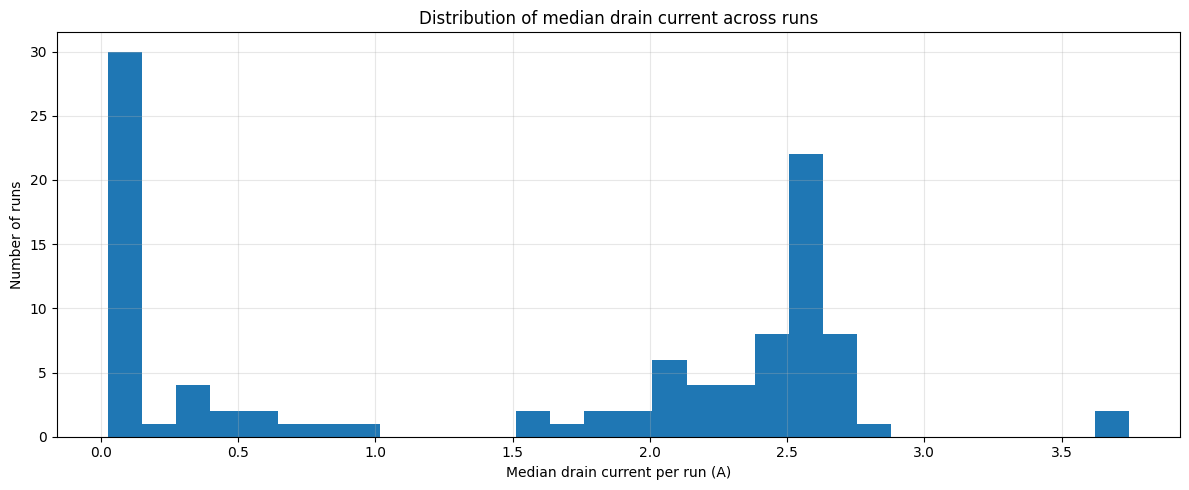

Run-level median-current quantiles:


0.00    0.025634
0.10    0.057594
0.25    0.091298
0.50    2.107305
0.75    2.545783
0.90    2.631375
1.00    3.745726
Name: drain_current_median, dtype: float64


Runs with the lowest median current:


,filename,records,drain_current_median,valid_proxy_fraction,RDS_proxy_median
48,Test_24_run_1.mat,752,0.025634,0.378989,1.542628
76,Test_38_run_1.mat,43915,0.027727,0.174428,2.025106
53,Test_25_run_4.mat,29,0.030015,0.000000,NaN
74,Test_36_run_1.mat,53560,0.032432,0.414731,1.925244
62,Test_29_run_1.mat,48269,0.033468,0.283080,1.933150
54,Test_26_run_1.mat,46574,0.034137,0.304655,2.006882
64,Test_2_run_2.mat,1111,0.037589,0.158416,1.428926
65,Test_2_run_3.mat,3548,0.047775,0.380778,2.316936
63,Test_2_run_1.mat,2981,0.047775,0.117746,1.389986
87,Test_6_run_1.mat,8713,0.055328,0.486629,2.227384


In [30]:
# CELL 28: Examine operating-current distributions across runs

plt.figure(figsize=(12, 5))

plt.hist(
    run_features_df["drain_current_median"].dropna(),
    bins=30
)
plt.xlabel("Median drain current per run (A)")
plt.ylabel("Number of runs")
plt.title("Distribution of median drain current across runs")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Run-level median-current quantiles:")
display(
    run_features_df["drain_current_median"].quantile(
        [0, 0.1, 0.25, 0.5, 0.75, 0.9, 1]
    )
)

print("\nRuns with the lowest median current:")
display(
    run_features_df.nsmallest(10, "drain_current_median")[
        ["filename", "records", "drain_current_median",
         "valid_proxy_fraction", "RDS_proxy_median"]
    ]
)

In [31]:
# CELL 29: Current-threshold sensitivity on Test 20, Run 1
# Self-contained recovery version. No download or extraction.

from pathlib import Path
from scipy.io import loadmat
import numpy as np
import pandas as pd

DATASET_DIR = Path(
    "/kaggle/working/mosfet_dataset/"
    "MOSFET_Thermal_Overstress_Aging_v0"
)
file_path = DATASET_DIR / "Test_20_run_1.mat"

if not file_path.exists():
    raise FileNotFoundError(
        f"Existing dataset file not found: {file_path}"
    )

mat = loadmat(
    str(file_path),
    squeeze_me=False,
    struct_as_record=True
)

measurement = mat["measurement"][0, 0]
steady_records = measurement["steadyState"].reshape(-1)

vds_values = []
current_values = []

for rec in steady_records:
    td = rec["timeDomain"].reshape(-1)[0]

    def scalar(x):
        try:
            return float(np.asarray(x).squeeze())
        except (TypeError, ValueError):
            return np.nan

    vds_values.append(scalar(td["drainSourceVoltage"]))
    current_values.append(scalar(td["drainCurrent"]))

vds = np.asarray(vds_values, dtype=float)
current = np.asarray(current_values, dtype=float)

thresholds = [1.5, 2.0, 2.5, 3.0]
results = []

for threshold in thresholds:
    valid = (
        np.isfinite(vds)
        & np.isfinite(current)
        & (vds > 0)
        & (current >= threshold)
    )

    ratios = vds[valid] / current[valid]
    ratios = ratios[np.isfinite(ratios)]

    results.append({
        "current_threshold_A": threshold,
        "valid_samples": int(valid.sum()),
        "total_samples": len(current),
        "valid_fraction": float(valid.mean()),
        "median_RDS_proxy_ohm": (
            float(np.median(ratios)) if len(ratios) else np.nan
        ),
        "p90_RDS_proxy_ohm": (
            float(np.percentile(ratios, 90))
            if len(ratios) else np.nan
        )
    })

threshold_df = pd.DataFrame(results)
display(threshold_df.round(5))

print("Analysed:", file_path.name)
print("No files were downloaded, extracted, or duplicated.")

,current_threshold_A,valid_samples,total_samples,valid_fraction,median_RDS_proxy_ohm,p90_RDS_proxy_ohm
0,1.5,20010,21743,0.92030,2.02889,2.31499
1,2.0,19882,21743,0.91441,2.02777,2.30509
2,2.5,9994,21743,0.45964,1.92448,2.00865
3,3.0,272,21743,0.01251,1.39309,1.55570


Analysed: Test_20_run_1.mat
No files were downloaded, extracted, or duplicated.


In [32]:
# CELL 30: Inspect gateState transitions in Test 20, Run 1
# Self-contained recovery version

from pathlib import Path
from scipy.io import loadmat
import numpy as np
import pandas as pd

DATASET_DIR = Path(
    "/kaggle/working/mosfet_dataset/"
    "MOSFET_Thermal_Overstress_Aging_v0"
)
file_path = DATASET_DIR / "Test_20_run_1.mat"

if not file_path.exists():
    raise FileNotFoundError(f"File not found: {file_path}")

mat = loadmat(
    str(file_path),
    squeeze_me=False,
    struct_as_record=True
)

measurement = mat["measurement"][0, 0]
controller_records = measurement["pwmTempControllerState"].reshape(-1)

rows = []

for rec in controller_records:
    def scalar(x):
        try:
            return float(np.asarray(x).squeeze())
        except (TypeError, ValueError):
            return np.nan

    rows.append({
        "time": scalar(rec["time"]),
        "timeEpoch": scalar(rec["timeEpoch"]),
        "gateState": scalar(rec["gateState"]),
        "gateVoltage": scalar(rec["gateVoltage"]),
        "supplyVoltage": scalar(rec["supplyVoltage"]),
        "switchingFrequency": scalar(rec["switchingFrequency"]),
        "dutyCycle": scalar(rec["dutyCycle"])
    })

controller_df = pd.DataFrame(rows)

# Sort by epoch if timestamps are available.
if controller_df["timeEpoch"].notna().any():
    controller_df = controller_df.sort_values("timeEpoch").reset_index(drop=True)

controller_df["gateState_previous"] = controller_df["gateState"].shift(1)
controller_df["gateState_changed"] = (
    controller_df["gateState"] != controller_df["gateState_previous"]
) & controller_df["gateState"].notna() & controller_df["gateState_previous"].notna()

transitions_df = controller_df[controller_df["gateState_changed"]].copy()

print("File:", file_path.name)
print("Controller records:", len(controller_df))
print("Gate-state transitions:", len(transitions_df))

print("\nGate-state values:")
print(controller_df["gateState"].value_counts(dropna=False).sort_index())

print("\nFirst controller records:")
display(controller_df.head(10))

print("\nFirst gate-state transitions:")
display(transitions_df.head(20))

print("\nNo dataset download or extraction performed.")

File: Test_20_run_1.mat
Controller records: 1382
Gate-state transitions: 1372

Gate-state values:
gateState
0.0    696
1.0    686
Name: count, dtype: int64

First controller records:


,time,timeEpoch,gateState,gateVoltage,supplyVoltage,switchingFrequency,dutyCycle,gateState_previous,gateState_changed
0,NaN,734339.402948,0.0,10.0,5.0,1000.0,40.0,NaN,False
1,NaN,734339.402951,0.0,10.0,5.0,1000.0,40.0,0.0,False
2,NaN,734339.402999,1.0,10.0,5.0,1000.0,40.0,0.0,True
3,NaN,734339.403082,0.0,10.0,5.0,1000.0,40.0,1.0,True
4,NaN,734339.403092,1.0,10.0,5.0,1000.0,40.0,0.0,True
5,NaN,734339.403259,0.0,10.0,5.0,1000.0,40.0,1.0,True
6,NaN,734339.403269,1.0,10.0,5.0,1000.0,40.0,0.0,True
7,NaN,734339.403436,0.0,10.0,5.0,1000.0,40.0,1.0,True
8,NaN,734339.403445,1.0,10.0,5.0,1000.0,40.0,0.0,True
9,NaN,734339.403617,0.0,10.0,5.0,1000.0,40.0,1.0,True



First gate-state transitions:


,time,timeEpoch,gateState,gateVoltage,supplyVoltage,switchingFrequency,dutyCycle,gateState_previous,gateState_changed
2,NaN,734339.402999,1.0,10.0,5.0,1000.0,40.0,0.0,True
3,NaN,734339.403082,0.0,10.0,5.0,1000.0,40.0,1.0,True
4,NaN,734339.403092,1.0,10.0,5.0,1000.0,40.0,0.0,True
5,NaN,734339.403259,0.0,10.0,5.0,1000.0,40.0,1.0,True
6,NaN,734339.403269,1.0,10.0,5.0,1000.0,40.0,0.0,True
7,NaN,734339.403436,0.0,10.0,5.0,1000.0,40.0,1.0,True
8,NaN,734339.403445,1.0,10.0,5.0,1000.0,40.0,0.0,True
9,NaN,734339.403617,0.0,10.0,5.0,1000.0,40.0,1.0,True
10,NaN,734339.403627,1.0,10.0,5.0,1000.0,40.0,0.0,True
11,NaN,734339.403691,0.0,10.0,5.0,1000.0,40.0,1.0,True



No dataset download or extraction performed.


In [33]:
# CELL 31: Compare controller and steady-state time ranges

steady = measurement["steadyState"][0, 0]
steady_epochs = np.asarray(
    steady["timeEpoch"], dtype=float
).reshape(-1)

controller_start = controller_df["timeEpoch"].min()
controller_end = controller_df["timeEpoch"].max()
steady_start = steady_epochs.min()
steady_end = steady_epochs.max()

print("Controller time range:", controller_start, controller_end)
print("Steady-state time range:", steady_start, steady_end)

print(
    "Controller duration (seconds):",
    (controller_end - controller_start) * 86400
)
print(
    "Steady-state duration (seconds):",
    (steady_end - steady_start) * 86400
)

print(
    "Overlapping time interval (seconds):",
    max(
        0,
        (min(controller_end, steady_end) -
         max(controller_start, steady_start)) * 86400
    )
)

print("\nController and steady-state timestamp counts:")
print(len(controller_df), len(steady_epochs))

Controller time range: 734339.4029481829 734339.5041674306
Steady-state time range: 734339.4029559606 734339.4029559606
Controller duration (seconds): 8745.342999324203
Steady-state duration (seconds): 0.0
Overlapping time interval (seconds): 0

Controller and steady-state timestamp counts:
1382 1


In [34]:
# CELL 32: Inspect actual MATLAB steadyState fields
from pathlib import Path
from scipy.io import loadmat
import numpy as np

file_path = Path(
    "/kaggle/working/mosfet_dataset/"
    "MOSFET_Thermal_Overstress_Aging_v0/Test_20_run_1.mat"
)

assert file_path.exists(), f"File not found: {file_path}"

mat = loadmat(
    file_path,
    squeeze_me=False,
    struct_as_record=True
)

print("Top-level MATLAB variables:")
print([key for key in mat if not key.startswith("__")])

measurement = mat["measurement"]
print("\nMeasurement shape:", measurement.shape)
print("Measurement dtype:", measurement.dtype)
print("Measurement fields:", measurement.dtype.names)

measurement_record = measurement[0, 0]
steady_state = measurement_record["steadyState"]

print("\nsteadyState shape:", steady_state.shape)
print("steadyState dtype:", steady_state.dtype)
print("steadyState field names:", steady_state.dtype.names)

if steady_state.dtype.names:
    for field in steady_state.dtype.names:
        values = np.asarray(steady_state[field])
        print(f"{field}: shape={values.shape}, dtype={values.dtype}")
else:
    print("\nFirst steadyState element:")
    print(repr(steady_state.reshape(-1)[0])[:2000])

Top-level MATLAB variables:
['measurement']

Measurement shape: (1, 1)
Measurement dtype: [('pwmTempControllerState', 'O'), ('transient', 'O'), ('steadyState', 'O')]
Measurement fields: ('pwmTempControllerState', 'transient', 'steadyState')

steadyState shape: (1, 21743)
steadyState dtype: [('date', 'O'), ('nanosec_time', 'O'), ('timeEpoch', 'O'), ('timeDomain', 'O')]
steadyState field names: ('date', 'nanosec_time', 'timeEpoch', 'timeDomain')
date: shape=(1, 21743), dtype=object
nanosec_time: shape=(1, 21743), dtype=object
timeEpoch: shape=(1, 21743), dtype=object
timeDomain: shape=(1, 21743), dtype=object


In [35]:
# CELL 33: Timestamp-based controller alignment

# Reuse the Test 20, Run 1 data already loaded.
steady = measurement["steadyState"][0, 0]
td = steady["timeDomain"]

steady_records = []

for wrapped_record in td.flat:
    record = np.asarray(wrapped_record).squeeze()
    while (
        isinstance(record, np.ndarray)
        and record.dtype.names is None
        and record.size == 1
    ):
        record = record.item()

    steady_records.append({
        field: extract_record_scalar(record, field)
        for field in record.dtype.names
    })

steady_aligned = pd.DataFrame(steady_records)
steady_aligned["timeEpoch"] = np.asarray(
    steady["timeEpoch"].tolist(), dtype=float
).reshape(-1)

controller_aligned = controller_df.sort_values("timeEpoch").copy()
steady_aligned = steady_aligned.sort_values("timeEpoch").copy()

aligned_df = pd.merge_asof(
    steady_aligned,
    controller_aligned[
        ["timeEpoch", "gateState", "gateVoltage",
         "switchingFrequency", "dutyCycle"]
    ],
    on="timeEpoch",
    direction="backward",
    suffixes=("", "_controller")
)

print("Aligned rows:", len(aligned_df))
print("Rows without controller state:", int(aligned_df["gateState"].isna().sum()))
print("\nAligned gate-state distribution:")
display(aligned_df["gateState"].value_counts(dropna=False).sort_index())

display(aligned_df.head())

Aligned rows: 21743
Rows without controller state: 0

Aligned gate-state distribution:


gateState
0.0    20173
1.0     1570
Name: count, dtype: int64

,supplyVoltage,packageTemperature,drainSourceVoltage,drainCurrent,flangeTemperature,timeEpoch,gateState,gateVoltage,switchingFrequency,dutyCycle
0,5.603744,28.540243,4.536287,5.123332,25.048969,734339.402956,0.0,10.0,1000.0,40.0
1,5.600689,28.541214,4.517378,5.137380,26.893658,734339.402959,0.0,10.0,1000.0,40.0
2,5.590308,28.688375,4.536425,5.031291,29.049865,734339.402964,0.0,10.0,1000.0,40.0
3,5.610121,28.767703,4.570010,4.886185,30.953359,734339.402969,0.0,10.0,1000.0,40.0
4,5.606102,29.049721,4.599556,4.756357,32.666941,734339.402973,0.0,10.0,1000.0,40.0


In [36]:
# CELL 34: Compare electrical values by controller gate state

state_summary = aligned_df.groupby("gateState").agg(
    records=("drainCurrent", "size"),
    median_current=("drainCurrent", "median"),
    median_vds=("drainSourceVoltage", "median"),
    median_package_temp=("packageTemperature", "median"),
    median_flange_temp=("flangeTemperature", "median")
)

aligned_df["RDS_proxy"] = (
    aligned_df["drainSourceVoltage"]
    / aligned_df["drainCurrent"].where(
        aligned_df["drainCurrent"] > 1e-9
    )
)

state_summary["median_RDS_proxy"] = (
    aligned_df.groupby("gateState")["RDS_proxy"].median()
)

display(state_summary)

,records,median_current,median_vds,median_package_temp,median_flange_temp,median_RDS_proxy
gateState,,,,,,
0.0,20173,2.498034,5.072624,121.454970,208.905980,2.030379
1.0,1570,0.042542,5.583163,121.589504,207.859101,131.252440


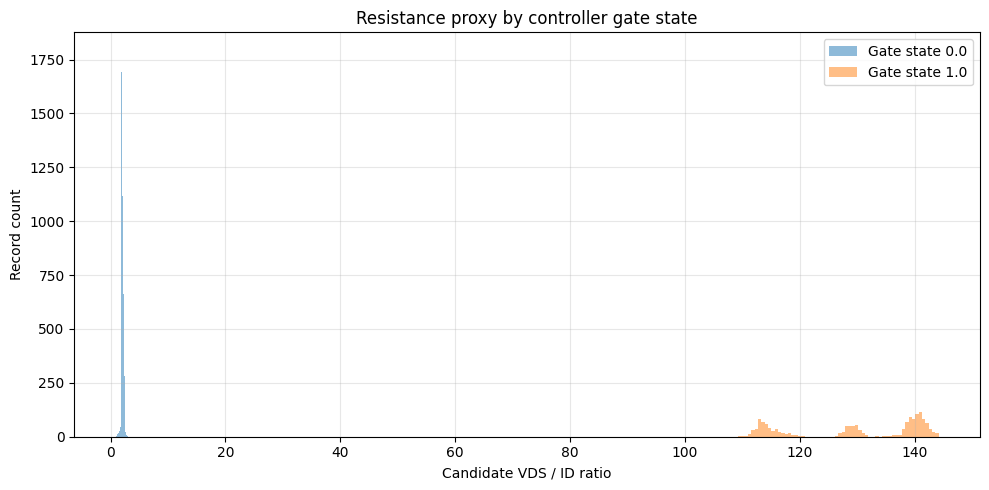

In [37]:
# CELL 35: State-specific resistance distributions

plt.figure(figsize=(10, 5))

for state in sorted(aligned_df["gateState"].dropna().unique()):
    subset = aligned_df.loc[
        aligned_df["gateState"] == state, "RDS_proxy"
    ].dropna()

    # Clip only for visualization, not in the underlying data.
    subset = subset[subset <= subset.quantile(0.99)]

    plt.hist(
        subset,
        bins=60,
        alpha=0.5,
        label=f"Gate state {state}"
    )

plt.xlabel("Candidate VDS / ID ratio")
plt.ylabel("Record count")
plt.title("Resistance proxy by controller gate state")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
# CELL 36: Gate state versus electrical measurements

display(
    aligned_df.groupby("gateState").agg(
        records=("drainCurrent", "size"),
        current_min=("drainCurrent", "min"),
        current_median=("drainCurrent", "median"),
        current_max=("drainCurrent", "max"),
        vds_min=("drainSourceVoltage", "min"),
        vds_median=("drainSourceVoltage", "median"),
        vds_max=("drainSourceVoltage", "max")
    )
)

print("\nExample records from each state:")

for state in sorted(aligned_df["gateState"].dropna().unique()):
    print(f"\nGate state {state}")
    display(
        aligned_df.loc[
            aligned_df["gateState"] == state,
            [
                "timeEpoch", "gateState", "gateVoltage",
                "drainSourceVoltage", "drainCurrent",
                "packageTemperature"
            ]
        ].head(5)
    )

,records,current_min,current_median,current_max,vds_min,vds_median,vds_max
gateState,,,,,,,
0.0,20173,0.040546,2.498034,5.202726,4.506810,5.072624,5.583869
1.0,1570,0.038107,0.042542,0.051099,5.579816,5.583163,5.585155



Example records from each state:

Gate state 0.0


,timeEpoch,gateState,gateVoltage,drainSourceVoltage,drainCurrent,packageTemperature
0,734339.402956,0.0,10.0,4.536287,5.123332,28.540243
1,734339.402959,0.0,10.0,4.517378,5.137380,28.541214
2,734339.402964,0.0,10.0,4.536425,5.031291,28.688375
3,734339.402969,0.0,10.0,4.570010,4.886185,28.767703
4,734339.402973,0.0,10.0,4.599556,4.756357,29.049721



Gate state 1.0


,timeEpoch,gateState,gateVoltage,drainSourceVoltage,drainCurrent,packageTemperature
10,734339.403002,1.0,10.0,5.583523,0.042747,32.301188
11,734339.403006,1.0,10.0,5.582831,0.042790,32.840131
12,734339.403011,1.0,10.0,5.583219,0.042877,33.456621
13,734339.403016,1.0,10.0,5.583772,0.043200,34.068092
14,734339.403020,1.0,10.0,5.581324,0.043092,34.550372


In [39]:
# CELL 37: Robust MATLAB waveform extraction

def unwrap_matlab(value):
    """Remove singleton MATLAB/object wrappers without flattening real waveforms."""
    while isinstance(value, np.ndarray) and value.size == 1:
        if value.dtype.names is not None:
            break
        value = value.item()
    return value

def waveform_array(value):
    """Convert a nested MATLAB waveform into a flat numeric array."""
    value = unwrap_matlab(value)
    arr = np.asarray(value)

    while arr.dtype == object and arr.size == 1:
        value = arr.item()
        arr = np.asarray(value)

    return np.asarray(arr, dtype=float).reshape(-1)

def scalar_value(value):
    arr = waveform_array(value)
    if arr.size != 1:
        raise ValueError(f"Expected one scalar, got {arr.size} values")
    return float(arr[0])

# Reuse transient and transient_td from Cell 37's earlier setup.
# If they are still defined, this simply refreshes them.
transient = measurement["transient"][0, 0]
transient_td = transient["timeDomain"]

print("Transient records:", transient_td.size)

for i in range(min(3, transient_td.size)):
    rec = np.asarray(transient_td.flat[i]).squeeze()

    while isinstance(rec, np.ndarray) and rec.dtype.names is None and rec.size == 1:
        rec = rec.item()

    print(f"\nRecord {i}:")
    for field in rec.dtype.names:
        try:
            arr = waveform_array(rec[field])
            print(
                f"{field}: shape={arr.shape}, "
                f"first_values={arr[:5]}"
            )
        except Exception as e:
            print(f"{field}: extraction failed: {e}")

Transient records: 20162

Record 0:
dt: shape=(1,), first_values=[1.e-06]
gateSignalVoltage: shape=(1000,), first_values=[-0.30761751 -0.33203158 -0.33691439 -0.37109408 -0.33691439]
gateSourceVoltage: shape=(1000,), first_values=[-0.00976593 -0.02441437 -0.03418    -0.03906281 -0.02441437]
drainSourceVoltage: shape=(1000,), first_values=[5.59570316 5.55664066 5.58593754 5.58105472 5.62500004]
drainCurrent: shape=(1000,), first_values=[0.31363083 0.33003298 0.36283728 0.23162009 0.23162009]

Record 1:
dt: shape=(1,), first_values=[1.e-06]
gateSignalVoltage: shape=(1000,), first_values=[-0.35644564 -0.36132845 -0.36132845 -0.35156283 -0.35156283]
gateSourceVoltage: shape=(1000,), first_values=[-0.02929718 -0.05371125 -0.01464875 -0.03906281 -0.05859406]
drainSourceVoltage: shape=(1000,), first_values=[5.61523441 5.60058597 5.59570316 5.57617191 5.61523441]
drainCurrent: shape=(1000,), first_values=[0.28082653 0.19881579 0.23162009 0.21521794 0.28082653]

Record 2:
dt: shape=(1,), first_

Sampling interval dt: 1e-06 seconds
Waveform lengths: {'gate_signal': 1000, 'gate_source': 1000, 'vds': 1000, 'current': 1000}


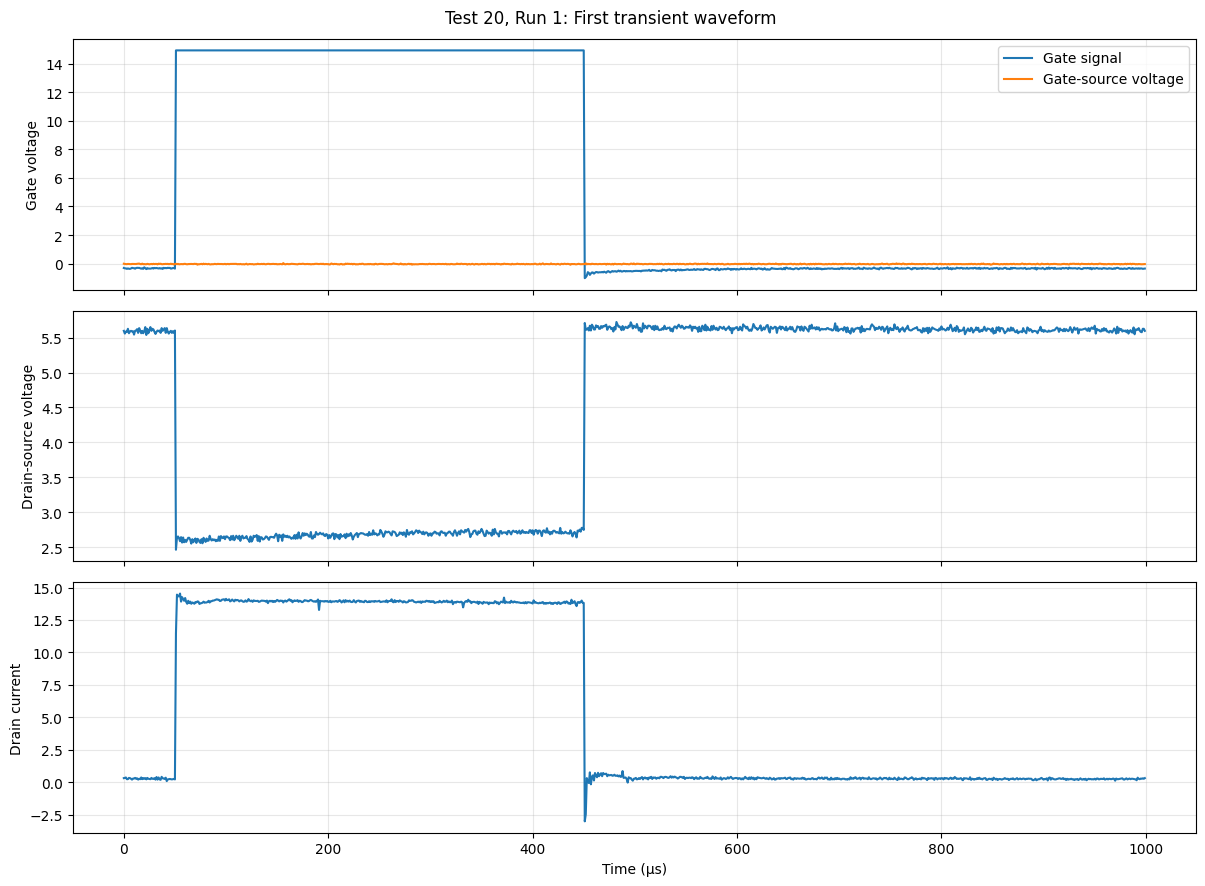

In [40]:
# CELL 38: Plot transient electrical waveforms

rec = np.asarray(transient_td.flat[0]).squeeze()

while isinstance(rec, np.ndarray) and rec.dtype.names is None and rec.size == 1:
    rec = rec.item()

dt = scalar_value(rec["dt"])
gate_signal = waveform_array(rec["gateSignalVoltage"])
gate_source = waveform_array(rec["gateSourceVoltage"])
vds = waveform_array(rec["drainSourceVoltage"])
current = waveform_array(rec["drainCurrent"])

print("Sampling interval dt:", dt, "seconds")
print("Waveform lengths:", {
    "gate_signal": len(gate_signal),
    "gate_source": len(gate_source),
    "vds": len(vds),
    "current": len(current)
})

# Use the common length if channels have different lengths.
n = min(map(len, [gate_signal, gate_source, vds, current]))
time_us = np.arange(n) * dt * 1e6

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(time_us, gate_signal[:n], label="Gate signal")
axes[0].plot(time_us, gate_source[:n], label="Gate-source voltage")
axes[0].set_ylabel("Gate voltage")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_us, vds[:n])
axes[1].set_ylabel("Drain-source voltage")
axes[1].grid(True, alpha=0.3)

axes[2].plot(time_us, current[:n])
axes[2].set_ylabel("Drain current")
axes[2].set_xlabel("Time (µs)")
axes[2].grid(True, alpha=0.3)

plt.suptitle("Test 20, Run 1: First transient waveform")
plt.tight_layout()
plt.show()

In [41]:
# CELL 39: Transient waveform quality check

waveform_summary = []

for i in range(min(10, transient_td.size)):
    rec = np.asarray(transient_td.flat[i]).squeeze()

    while isinstance(rec, np.ndarray) and rec.dtype.names is None and rec.size == 1:
        rec = rec.item()

    row = {"record": i}

    try:
        row["dt_seconds"] = scalar_value(rec["dt"])

        for field in [
            "gateSignalVoltage",
            "gateSourceVoltage",
            "drainSourceVoltage",
            "drainCurrent"
        ]:
            arr = waveform_array(rec[field])
            row[f"{field}_length"] = len(arr)
            row[f"{field}_min"] = np.min(arr) if arr.size else np.nan
            row[f"{field}_median"] = np.median(arr) if arr.size else np.nan
            row[f"{field}_max"] = np.max(arr) if arr.size else np.nan

    except Exception as e:
        row["error"] = str(e)

    waveform_summary.append(row)

waveform_summary_df = pd.DataFrame(waveform_summary)
display(waveform_summary_df)

,record,dt_seconds,gateSignalVoltage_length,gateSignalVoltage_min,gateSignalVoltage_median,gateSignalVoltage_max,gateSourceVoltage_length,gateSourceVoltage_min,gateSourceVoltage_median,gateSourceVoltage_max,drainSourceVoltage_length,drainSourceVoltage_min,drainSourceVoltage_median,drainSourceVoltage_max,drainCurrent_length,drainCurrent_min,drainCurrent_median,drainCurrent_max
0,0,0.000001,1000,-1.020508,-0.319825,14.921876,1000,-0.078125,-0.034180,0.034179,1000,2.465820,5.590820,5.722656,1000,-3.016005,0.346435,14.534294
1,1,0.000001,1000,-1.020508,-0.332032,14.921876,1000,-0.083008,-0.029297,0.029297,1000,2.548828,5.590820,5.703125,1000,-2.933995,0.330033,14.337468
2,2,0.000001,1000,-0.996094,-0.327149,14.921876,1000,-0.078125,-0.029297,0.029297,1000,2.670898,5.590820,5.712891,1000,-2.737169,0.313631,13.943817
3,3,0.000001,1000,-0.996094,-0.332032,14.921876,1000,-0.083008,-0.029297,0.014648,1000,2.695312,5.590820,5.751953,1000,-2.737169,0.305430,13.746991
4,4,0.000001,1000,-1.015625,-0.336914,14.921876,1000,-0.078125,-0.024414,0.019531,1000,2.807617,5.585938,5.747070,1000,-2.622354,0.346435,13.615774
5,5,0.000001,1000,-1.005860,-0.336914,14.921876,1000,-0.063477,-0.024414,0.024414,1000,2.773437,5.595703,5.703125,1000,-2.622354,0.313631,13.402546
6,6,0.000001,1000,-1.113282,-0.415040,19.472657,1000,-0.073242,-0.024414,0.024414,1000,2.880859,5.590820,5.747070,1000,-2.655158,0.346435,13.123709
7,7,0.000001,1000,-1.113282,-0.410157,19.531251,1000,-0.073242,-0.019532,0.034179,1000,2.866211,5.590820,5.703125,1000,-2.605952,0.330033,13.058101
8,8,0.000001,1000,-1.132813,-0.410157,19.443360,1000,-0.073242,-0.019532,0.034179,1000,2.807617,5.595703,5.712891,1000,-2.491137,0.313631,12.959688
9,9,0.000001,1000,-1.103516,-0.410157,19.345704,1000,-0.068360,-0.019532,0.029297,1000,2.880859,5.590820,5.708008,1000,-2.573147,0.313631,12.779264


Analysis: first transient waveform
Sampling interval (s): 1e-06
Waveform samples: 1000
Total samples: 1000
Valid high-current samples: 400
Valid sample percentage: 40.0

Resistance proxy statistics (ohms):


,RDS_proxy_ohm
count,400.000000
mean,0.192715
std,0.004186
min,0.178054
10%,0.186994
50%,0.193123
90%,0.197609
99%,0.201152
max,0.215034


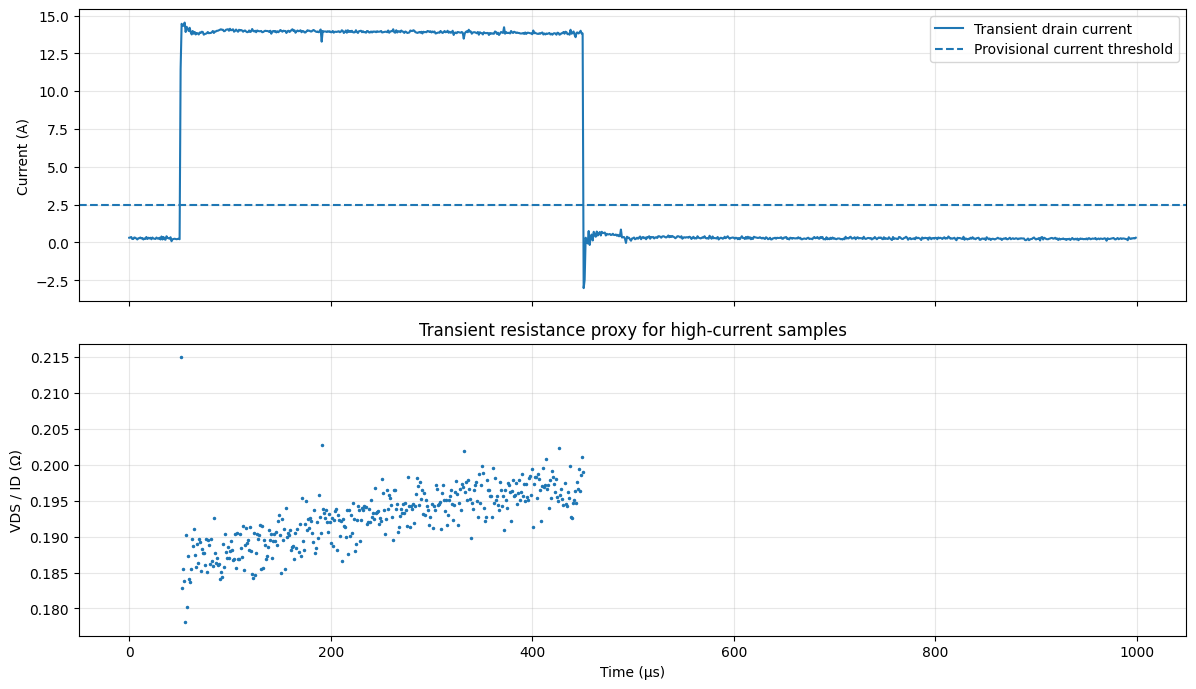

In [42]:

# CELL 40: Transient ON-state resistance proxy
# Uses the first transient waveform extracted in Cell 38.
# Does not modify the raw waveform arrays.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Re-extract the first transient record explicitly to avoid
# accidentally using steady-state arrays from another cell.
rec = np.asarray(transient_td.flat[0]).squeeze()

while (
    isinstance(rec, np.ndarray)
    and rec.dtype.names is None
    and rec.size == 1
):
    rec = rec.item()

dt = scalar_value(rec["dt"])
gate_signal = waveform_array(rec["gateSignalVoltage"])
gate_source = waveform_array(rec["gateSourceVoltage"])
vds_transient = waveform_array(rec["drainSourceVoltage"])
current_transient = waveform_array(rec["drainCurrent"])

# Use a common length for the waveform channels.
n = min(
    len(gate_signal),
    len(gate_source),
    len(vds_transient),
    len(current_transient)
)

gate_signal = gate_signal[:n]
gate_source = gate_source[:n]
vds_transient = vds_transient[:n]
current_transient = current_transient[:n]

time_us_transient = np.arange(n) * dt * 1e6

# Provisional screening threshold, not a validated physical limit.
current_threshold = 2.5  # A

valid = (
    np.isfinite(vds_transient)
    & np.isfinite(current_transient)
    & (current_transient >= current_threshold)
    & (vds_transient > 0)
)

rds_proxy_transient = np.full(n, np.nan, dtype=float)
rds_proxy_transient[valid] = (
    vds_transient[valid] / current_transient[valid]
)

print("Analysis: first transient waveform")
print("Sampling interval (s):", dt)
print("Waveform samples:", n)
print("Total samples:", n)
print("Valid high-current samples:", int(valid.sum()))
print(
    "Valid sample percentage:",
    round(100 * valid.mean(), 2)
)

if valid.any():
    print("\nResistance proxy statistics (ohms):")
    display(
        pd.Series(rds_proxy_transient[valid]).describe(
            percentiles=[0.1, 0.5, 0.9, 0.99]
        ).to_frame("RDS_proxy_ohm")
    )
else:
    print(
        "\nNo samples passed the provisional threshold. "
        "No resistance statistics are available."
    )

# Plot transient current and its threshold.
fig, axes = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True
)

axes[0].plot(
    time_us_transient,
    current_transient,
    label="Transient drain current"
)
axes[0].axhline(
    current_threshold,
    linestyle="--",
    label="Provisional current threshold"
)
axes[0].set_ylabel("Current (A)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot the proxy only where the screening criteria pass.
axes[1].plot(
    time_us_transient[valid],
    rds_proxy_transient[valid],
    ".",
    markersize=3
)
axes[1].set_xlabel("Time (µs)")
axes[1].set_ylabel("VDS / ID (Ω)")
axes[1].set_title(
    "Transient resistance proxy for high-current samples"
)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [43]:
# CELL 41: Compare high-current samples across the first 20 records

threshold_A = 2.5
transient_rows = []

for i in range(min(20, transient_td.size)):
    rec = np.asarray(transient_td.flat[i]).squeeze()

    while isinstance(rec, np.ndarray) and rec.dtype.names is None and rec.size == 1:
        rec = rec.item()

    try:
        vds_i = waveform_array(rec["drainSourceVoltage"])
        current_i = waveform_array(rec["drainCurrent"])

        n = min(len(vds_i), len(current_i))
        vds_i = vds_i[:n]
        current_i = current_i[:n]

        valid_i = (
            np.isfinite(vds_i)
            & np.isfinite(current_i)
            & (current_i >= threshold_A)
            & (vds_i > 0)
        )

        ratio_i = vds_i[valid_i] / current_i[valid_i]

        transient_rows.append({
            "record": i,
            "samples": n,
            "valid_samples": int(valid_i.sum()),
            "valid_percent": 100 * valid_i.mean() if n else np.nan,
            "current_median_A": np.median(current_i),
            "rds_median_ohm": np.median(ratio_i) if len(ratio_i) else np.nan,
            "rds_p90_ohm": np.percentile(ratio_i, 90) if len(ratio_i) else np.nan
        })

    except Exception as e:
        transient_rows.append({"record": i, "error": str(e)})

transient_check_df = pd.DataFrame(transient_rows)
display(transient_check_df)

,record,samples,valid_samples,valid_percent,current_median_A,rds_median_ohm,rds_p90_ohm
0,0,1000,400,40.0,0.346435,0.193123,0.197609
1,1,1000,400,40.0,0.330033,0.213236,0.217858
2,2,1000,400,40.0,0.313631,0.225873,0.230926
3,3,1000,400,40.0,0.305430,0.236326,0.241573
4,4,1000,400,40.0,0.346435,0.243743,0.248974
5,5,1000,400,40.0,0.313631,0.253058,0.257559
6,6,1000,400,40.0,0.346435,0.258202,0.263480
7,7,1000,400,40.0,0.330033,0.264026,0.270306
8,8,1000,400,40.0,0.313631,0.269791,0.275037
9,9,1000,400,40.0,0.313631,0.274586,0.280163


In [44]:
# CELL 42: Steady-state resistance proxy quality check

# Reuse sample_df from Cell 11, if available.
required = [
    "drainSourceVoltage",
    "drainCurrent",
    "packageTemperature",
    "flangeTemperature"
]

missing = [c for c in required if c not in sample_df.columns]
if missing:
    raise KeyError(
        f"sample_df is missing {missing}. Re-run the steady-state extraction cell."
    )

steady_check = sample_df[required].copy()

for c in required:
    steady_check[c] = pd.to_numeric(steady_check[c], errors="coerce")

# Use high-current samples for this diagnostic only.
# We will validate the threshold across runs before applying it globally.
steady_threshold_A = 2.5

valid_steady = (
    np.isfinite(steady_check["drainSourceVoltage"])
    & np.isfinite(steady_check["drainCurrent"])
    & (steady_check["drainCurrent"] >= steady_threshold_A)
    & (steady_check["drainSourceVoltage"] > 0)
)

steady_check["RDS_proxy"] = np.nan
steady_check.loc[valid_steady, "RDS_proxy"] = (
    steady_check.loc[valid_steady, "drainSourceVoltage"]
    / steady_check.loc[valid_steady, "drainCurrent"]
)

print("Steady-state records:", len(steady_check))
print("Valid high-current records:", int(valid_steady.sum()))
print("Valid percentage:", round(100 * valid_steady.mean(), 2))

display(
    steady_check.loc[valid_steady, [
        "drainSourceVoltage",
        "drainCurrent",
        "RDS_proxy",
        "packageTemperature",
        "flangeTemperature"
    ]].describe()
)

Steady-state records: 21743
Valid high-current records: 9994
Valid percentage: 45.96


,drainSourceVoltage,drainCurrent,RDS_proxy,packageTemperature,flangeTemperature
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,5.039528,2.652651,1.909000,119.691977,207.182185
std,0.044185,0.208591,0.119664,9.098317,16.601774
min,4.506810,2.500019,0.866240,28.540243,25.048969
25%,5.029743,2.558589,1.871020,120.906960,208.024424
50%,5.045900,2.621938,1.924475,121.259564,209.004188
75%,5.060755,2.688001,1.978035,121.524665,209.695743
max,5.087549,5.202726,2.034301,126.149402,223.145604


In [45]:
# CELL 43: Correctly calculate statistics for the first 20 waveforms

transient_rows = []

for i in range(min(20, transient_td.size)):
    rec = np.asarray(transient_td.flat[i]).squeeze()

    while isinstance(rec, np.ndarray) and rec.dtype.names is None and rec.size == 1:
        rec = rec.item()

    vds_i = waveform_array(rec["drainSourceVoltage"])
    current_i = waveform_array(rec["drainCurrent"])
    n = min(len(vds_i), len(current_i))

    vds_i, current_i = vds_i[:n], current_i[:n]

    # Use the same provisional threshold for this diagnostic.
    mask = (
        np.isfinite(vds_i)
        & np.isfinite(current_i)
        & (current_i >= 2.5)
        & (vds_i > 0)
    )

    ratio = vds_i[mask] / current_i[mask]

    transient_rows.append({
        "record": i,
        "samples": n,
        "valid_samples": int(mask.sum()),
        "valid_percent": 100 * mask.mean() if n else np.nan,
        "current_median_A": float(np.median(current_i)),
        "vds_median": float(np.median(vds_i)),
        "rds_median_proxy": float(np.median(ratio)) if ratio.size else np.nan,
        "rds_p90_proxy": float(np.percentile(ratio, 90)) if ratio.size else np.nan
    })

transient_check_df = pd.DataFrame(transient_rows)
display(transient_check_df)

,record,samples,valid_samples,valid_percent,current_median_A,vds_median,rds_median_proxy,rds_p90_proxy
0,0,1000,400,40.0,0.346435,5.590820,0.193123,0.197609
1,1,1000,400,40.0,0.330033,5.590820,0.213236,0.217858
2,2,1000,400,40.0,0.313631,5.590820,0.225873,0.230926
3,3,1000,400,40.0,0.305430,5.590820,0.236326,0.241573
4,4,1000,400,40.0,0.346435,5.585938,0.243743,0.248974
5,5,1000,400,40.0,0.313631,5.595703,0.253058,0.257559
6,6,1000,400,40.0,0.346435,5.590820,0.258202,0.263480
7,7,1000,400,40.0,0.330033,5.590820,0.264026,0.270306
8,8,1000,400,40.0,0.313631,5.595703,0.269791,0.275037
9,9,1000,400,40.0,0.313631,5.590820,0.274586,0.280163


STEADY-STATE measurements


,drainSourceVoltage,drainCurrent
count,21743.000000,21743.000000
mean,5.113355,2.298741
std,0.143498,0.688227
min,4.506810,0.038107
10%,5.027312,2.086341
50%,5.076524,2.475461
90%,5.159585,2.697372
max,5.585155,5.202726



TRANSIENT measurements: first 20 records combined


,drainSourceVoltage,drainCurrent
count,20000.000000,20000.000000
mean,4.543298,5.264575
std,1.316926,6.120903
min,2.465820,-3.114418
10%,2.817383,0.215218
50%,5.585938,0.346435
90%,5.644531,13.320535
max,5.751953,14.534294


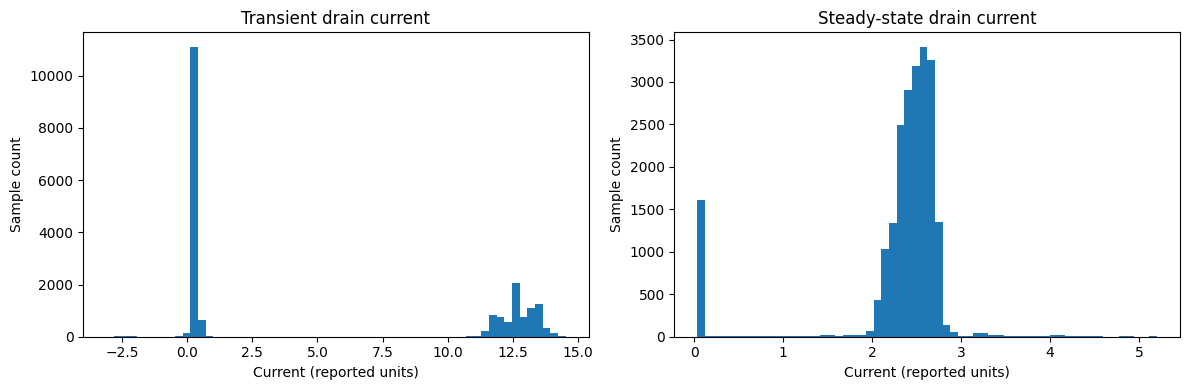

In [46]:
# CELL 44: Compare measurement ranges without assuming equal operating conditions

steady_ranges = sample_df[
    ["drainSourceVoltage", "drainCurrent"]
].describe(percentiles=[0.1, 0.5, 0.9])

print("STEADY-STATE measurements")
display(steady_ranges)

print("\nTRANSIENT measurements: first 20 records combined")

vds_list, current_list = [], []

for i in range(min(20, transient_td.size)):
    rec = np.asarray(transient_td.flat[i]).squeeze()

    while isinstance(rec, np.ndarray) and rec.dtype.names is None and rec.size == 1:
        rec = rec.item()

    vds_list.extend(waveform_array(rec["drainSourceVoltage"]))
    current_list.extend(waveform_array(rec["drainCurrent"]))

transient_comparison = pd.DataFrame({
    "drainSourceVoltage": vds_list,
    "drainCurrent": current_list
})

display(
    transient_comparison.describe(
        percentiles=[0.1, 0.5, 0.9]
    )
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    transient_comparison["drainCurrent"],
    bins=60
)
axes[0].set_title("Transient drain current")
axes[0].set_xlabel("Current (reported units)")
axes[0].set_ylabel("Sample count")

axes[1].hist(
    sample_df["drainCurrent"].dropna(),
    bins=60
)
axes[1].set_title("Steady-state drain current")
axes[1].set_xlabel("Current (reported units)")
axes[1].set_ylabel("Sample count")

plt.tight_layout()
plt.show()

In [47]:
# CELL 45: Inspect the ramp-up file's steady-state measurements

ramp_measurement = ramp_mat["measurement"]
ramp_steady = ramp_measurement["steadyState"][0, 0] 
ramp_td = ramp_steady["timeDomain"]

ramp_rows = []

for wrapped in ramp_td.flat:
    rec = np.asarray(wrapped).squeeze()

    while isinstance(rec, np.ndarray) and rec.dtype.names is None and rec.size == 1:
        rec = rec.item()

    row = {}
    for field in rec.dtype.names:
        try:
            row[field] = scalar_value(rec[field])
        except (TypeError, ValueError):
            row[field] = np.nan

    ramp_rows.append(row)

ramp_df = pd.DataFrame(ramp_rows)

print("Ramp-up steady-state records:", len(ramp_df))
print("Columns:", ramp_df.columns.tolist())
display(ramp_df.head())

numeric_cols = [ 
    c for c in [
        "supplyVoltage", "packageTemperature",
        "drainSourceVoltage", "drainCurrent",
        "flangeTemperature"    
    ] if c in ramp_df.columns  
]
 
display(ramp_df[numeric_cols].describe()) 

Ramp-up steady-state records: 6554
Columns: ['supplyVoltage', 'packageTemperature', 'drainSourceVoltage', 'drainCurrent', 'flangeTemperature']


,supplyVoltage,packageTemperature,drainSourceVoltage,drainCurrent,flangeTemperature
0,5.608000,29.362661,5.396827,0.899791,23.254690
1,5.622259,29.360071,5.435835,0.729651,23.254679
2,5.621380,29.292561,5.423883,0.778120,23.257547
3,5.622231,29.418191,5.427134,0.763251,23.261698
4,5.621687,29.465302,5.417078,0.800844,23.255757


,supplyVoltage,packageTemperature,drainSourceVoltage,drainCurrent,flangeTemperature
count,6554.000000,6554.000000,6554.000000,6554.000000,6554.000000
mean,5.618282,109.827978,5.306042,1.357244,23.136637
std,0.003625,29.574958,0.084544,0.399873,0.119066
min,5.587071,29.292561,5.124855,0.037438,22.686079
25%,5.615423,99.207586,5.243806,1.126838,23.050100
50%,5.618611,118.845729,5.298652,1.389050,23.125636
75%,5.620655,131.974380,5.356482,1.640435,23.220681
max,5.654336,157.061413,5.583509,2.188377,23.464000


In [48]:

# CELL 46: Audit experimental chronology across tests and runs
# Goal: determine whether run numbering agrees with recorded timestamps.
# This is a chronology audit, NOT an assumption that runs represent aging.

import numpy as np
import pandas as pd

assert "run_features_df" in globals(), (
    "run_features_df is unavailable. Run the existing run-feature "
    "extraction cell first."
)

chronology_df = run_features_df.copy()

print("Rows in run_features_df:", len(chronology_df))
print("Available columns:")
print(chronology_df.columns.tolist())

# Identify timestamp columns without assuming their exact names.
lower_to_original = {
    str(col).lower(): col for col in chronology_df.columns
}

start_candidates = [
    "start_epoch", "start_time_epoch", "epoch_start",
    "start_timestamp", "first_epoch", "time_start"
]
end_candidates = [
    "end_epoch", "end_time_epoch", "epoch_end",
    "end_timestamp", "last_epoch", "time_end"
]

start_col = next(
    (lower_to_original[c] for c in start_candidates
     if c in lower_to_original),
    None
)
end_col = next(
    (lower_to_original[c] for c in end_candidates
     if c in lower_to_original),
    None
)

required_ids = ["filename", "test_id", "run_id"]
missing_ids = [
    col for col in required_ids
    if col not in chronology_df.columns
]

if missing_ids:
    raise KeyError(
        f"Missing run identity columns: {missing_ids}"
    )

chronology_df["test_id"] = pd.to_numeric(
    chronology_df["test_id"], errors="coerce"
)
chronology_df["run_id"] = pd.to_numeric(
    chronology_df["run_id"], errors="coerce"
)

print("\nUnique test IDs:", chronology_df["test_id"].nunique())
print("Unique test/run pairs:", chronology_df[
    ["test_id", "run_id"]
].drop_duplicates().shape[0])

print("\nDuplicate test/run pairs:")
duplicate_pairs = chronology_df[
    chronology_df.duplicated(
        ["test_id", "run_id"], keep=False
    )
].sort_values(["test_id", "run_id"])

if duplicate_pairs.empty:
    print("None")
else:
    display(duplicate_pairs)

# Summarize how many runs appear in each test.
test_summary = (
    chronology_df.groupby("test_id", dropna=False)
    .agg(
        run_count=("run_id", "nunique"),
        first_run_id=("run_id", "min"),
        last_run_id=("run_id", "max"),
        filenames=("filename", "count")
    )
    .reset_index()
    .sort_values("test_id")
)

print("\nRun inventory by test:")
display(test_summary)

# If timestamp endpoints exist in the current feature table,
# compare run-number order against recorded chronology.
if start_col is not None and end_col is not None:
    chronology_df[start_col] = pd.to_numeric(
        chronology_df[start_col], errors="coerce"
    )
    chronology_df[end_col] = pd.to_numeric(
        chronology_df[end_col], errors="coerce"
    )

    chronology_df = chronology_df.sort_values(
        ["test_id", "run_id"]
    ).copy()

    chronology_df["recorded_duration_days"] = (
        chronology_df[end_col] - chronology_df[start_col]
    )

    chronology_df["next_run_start_epoch"] = (
        chronology_df.groupby("test_id")[start_col].shift(-1)
    )

    chronology_df["next_run_gap_days"] = (
        chronology_df["next_run_start_epoch"]
        - chronology_df[end_col]
    )

    chronology_df["next_run_starts_after_this_run"] = (
        chronology_df["next_run_gap_days"] > 0
    )

    print("\nTimestamp fields detected:")
    print("Start:", start_col)
    print("End:", end_col)

    print("\nRun chronology details:")
    display(
        chronology_df[
            [
                "test_id", "run_id", "filename",
                start_col, end_col,
                "recorded_duration_days",
                "next_run_gap_days",
                "next_run_starts_after_this_run"
            ]
        ].sort_values(["test_id", "run_id"])
    )

    print("\nChronology checks:")
    print(
        "Invalid or reversed run intervals:",
        int(
            (
                chronology_df[end_col].isna()
                | chronology_df[start_col].isna()
                | (chronology_df[end_col] < chronology_df[start_col])
            ).sum()
        )
    )
    print(
        "Runs whose next numbered run starts later:",
        int(
            chronology_df["next_run_starts_after_this_run"]
            .fillna(False).sum()
        )
    )
else:
    print(
        "\nStart/end timestamp columns were not found in "
        "run_features_df. No chronology conclusion is drawn "
        "from run_id alone."
    )
    print(
        "We will use the existing timestamp audit information "
        "to determine the next validation step."
    )


Rows in run_features_df: 104
Available columns:
['filename', 'test_id', 'run_id', 'records', 'start_epoch', 'end_epoch', 'duration_seconds', 'timestamps_monotonic', 'valid_proxy_count', 'valid_proxy_fraction', 'RDS_proxy_median', 'RDS_proxy_p90', 'package_temp_median', 'flange_temp_median', 'drain_current_median', 'invalid_package_temp_count', 'invalid_current_count', 'invalid_voltage_count']

Unique test IDs: 42
Unique test/run pairs: 104

Duplicate test/run pairs:
None

Run inventory by test:


,test_id,run_count,first_run_id,last_run_id,filenames
0,1,2,1,2,2
1,2,3,1,3,3
2,3,1,1,1,1
3,4,2,1,2,2
4,5,2,1,2,2
5,6,2,1,2,2
6,7,1,1,1,1
7,8,7,1,7,7
8,9,7,1,7,7
9,10,7,1,7,7



Timestamp fields detected:
Start: start_epoch
End: end_epoch

Run chronology details:


,test_id,run_id,filename,start_epoch,end_epoch,recorded_duration_days,next_run_gap_days,next_run_starts_after_this_run
40,1,1,Test_1_run_1.mat,734186.739922,734186.744882,0.004960,0.680984,True
41,1,2,Test_1_run_2.mat,734187.425866,734187.436841,0.010975,NaN,False
63,2,1,Test_2_run_1.mat,734187.646426,734187.660239,0.013813,0.006654,True
64,2,2,Test_2_run_2.mat,734187.666893,734187.672032,0.005139,0.012624,True
65,2,3,Test_2_run_3.mat,734187.684656,734187.701106,0.016450,NaN,False
...,...,...,...,...,...,...,...,...
77,39,1,Test_39_run_1.mat,734374.556795,734374.592467,0.035672,NaN,False
79,40,1,Test_40_run_1.mat,734374.884140,734374.893119,0.008979,0.016643,True
80,40,2,Test_40_run_2.mat,734374.909762,734374.930572,0.020810,NaN,False
81,41,1,Test_41_run_1.mat,734374.936063,734375.238317,0.302254,NaN,False



Chronology checks:
Invalid or reversed run intervals: 0
Runs whose next numbered run starts later: 62


Tests with multiple runs: 22
Runs belonging to multi-run tests: 84

Chronology consistency:
Consecutive run-ID increases: 62
Negative time gaps / overlaps: 0

Run-by-run proxy changes:


,test_id,run_id,start_epoch,RDS_proxy_median,valid_proxy_fraction,proxy_change_from_previous,proxy_pct_change_from_previous
0,1,1,734186.739922,1.712394,0.862524,NaN,NaN
1,1,2,734187.425866,1.957194,0.631692,0.244800,14.295767
2,2,1,734187.646426,1.389986,0.117746,NaN,NaN
3,2,2,734187.666893,1.428926,0.158416,0.038940,2.801452
4,2,3,734187.684656,2.316936,0.380778,0.888010,62.145305
...,...,...,...,...,...,...,...
92,34,1,734360.910652,1.770773,0.513374,NaN,NaN
93,34,2,734361.691049,1.796487,0.517962,0.025714,1.452130
94,34,3,734362.513198,2.124639,0.554654,0.328152,18.266312
100,40,1,734374.884140,NaN,0.000000,NaN,NaN



Exploratory within-test trend summary:


,test_id,runs,first_proxy,last_proxy,median_proxy,min_proxy,max_proxy,median_proxy_coverage,first_to_last_change,first_to_last_pct_change
2,4,2,2.690488,2.028584,2.359536,2.028584,2.690488,0.420724,-0.661904,-24.601621
18,27,5,1.892025,1.857915,1.887451,1.851872,1.892025,0.559436,-0.034110,-1.802830
13,19,2,3.112033,3.112033,3.112033,3.112033,3.112033,0.378276,0.000000,0.000000
3,5,2,2.717308,2.717308,2.717308,2.717308,2.717308,0.420495,0.000000,0.000000
21,40,2,2.749028,2.749028,2.749028,2.749028,2.749028,0.111037,0.000000,0.000000
19,28,2,1.963924,1.970502,1.967213,1.963924,1.970502,0.392367,0.006578,0.334958
15,23,2,1.944671,2.041177,1.992924,1.944671,2.041177,0.477663,0.096506,4.962567
14,20,2,2.028895,2.137667,2.083281,2.028895,2.137667,0.859142,0.108772,5.361129
9,12,7,1.860361,1.976768,1.810772,1.694127,1.976768,0.496661,0.116408,6.257274
8,11,7,1.850963,1.994114,1.795367,1.689937,1.994114,0.503182,0.143151,7.733873


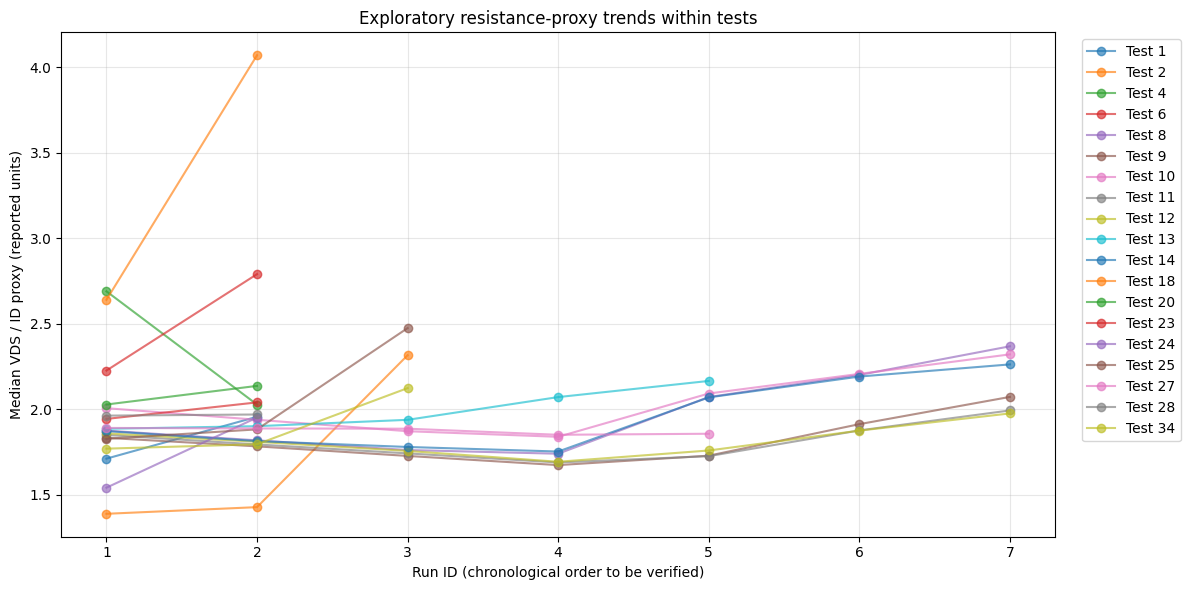

In [49]:

# CELL 47: Check within-test chronology and resistance-proxy trends
# Exploratory only: run order is not yet a validated aging label.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required_cols = [
    "test_id", "run_id", "start_epoch", "end_epoch",
    "RDS_proxy_median", "valid_proxy_fraction",
    "package_temp_median", "flange_temp_median"
]

missing = [
    col for col in required_cols
    if col not in run_features_df.columns
]

if missing:
    raise KeyError(f"Missing required columns: {missing}")

trend_df = run_features_df[required_cols].copy()

for col in required_cols:
    trend_df[col] = pd.to_numeric(
        trend_df[col], errors="coerce"
    )

trend_df = trend_df.sort_values(
    ["test_id", "start_epoch"]
).reset_index(drop=True)

# Determine whether run ID order agrees with recorded time order.
trend_df["previous_end_epoch"] = (
    trend_df.groupby("test_id")["end_epoch"].shift(1)
)
trend_df["gap_days_from_previous_run"] = (
    trend_df["start_epoch"] - trend_df["previous_end_epoch"]
)
trend_df["run_id_increases"] = (
    trend_df.groupby("test_id")["run_id"].diff() > 0
)

multi_run_tests = (
    trend_df.groupby("test_id")["run_id"]
    .nunique()
)
multi_run_ids = multi_run_tests[multi_run_tests >= 2].index

multi = trend_df[
    trend_df["test_id"].isin(multi_run_ids)
].copy()

# Calculate within-test changes in the exploratory resistance proxy.
multi["proxy_change_from_previous"] = (
    multi.groupby("test_id")["RDS_proxy_median"].diff()
)

multi["proxy_pct_change_from_previous"] = (
    multi.groupby("test_id")["RDS_proxy_median"]
    .pct_change(fill_method=None) * 100
)

print("Tests with multiple runs:", len(multi_run_ids))
print("Runs belonging to multi-run tests:", len(multi))

print("\nChronology consistency:")
print(
    "Consecutive run-ID increases:",
    int(multi["run_id_increases"].fillna(False).sum())
)
print(
    "Negative time gaps / overlaps:",
    int((multi["gap_days_from_previous_run"] < 0).sum())
)

print("\nRun-by-run proxy changes:")
display(
    multi[
        [
            "test_id", "run_id", "start_epoch",
            "RDS_proxy_median", "valid_proxy_fraction",
            "proxy_change_from_previous",
            "proxy_pct_change_from_previous"
        ]
    ]
)

# Summarize each test's proxy trend without treating it as confirmed aging.
trend_summary = (
    multi.groupby("test_id")
    .agg(
        runs=("run_id", "nunique"),
        first_proxy=("RDS_proxy_median", "first"),
        last_proxy=("RDS_proxy_median", "last"),
        median_proxy=("RDS_proxy_median", "median"),
        min_proxy=("RDS_proxy_median", "min"),
        max_proxy=("RDS_proxy_median", "max"),
        median_proxy_coverage=("valid_proxy_fraction", "median")
    )
    .reset_index()
)

trend_summary["first_to_last_change"] = (
    trend_summary["last_proxy"] - trend_summary["first_proxy"]
)
trend_summary["first_to_last_pct_change"] = (
    (
        trend_summary["last_proxy"] - trend_summary["first_proxy"]
    ) / trend_summary["first_proxy"].abs().replace(0, np.nan)
) * 100

print("\nExploratory within-test trend summary:")
display(
    trend_summary.sort_values(
        "first_to_last_pct_change",
        na_position="last"
    )
)

# Visualize only tests with multiple runs.
plt.figure(figsize=(12, 6))

for test_id, group in multi.groupby("test_id"):
    group = group.sort_values("start_epoch")
    valid = group["RDS_proxy_median"].notna()

    if valid.sum() >= 2:
        plt.plot(
            group.loc[valid, "run_id"],
            group.loc[valid, "RDS_proxy_median"],
            marker="o",
            alpha=0.65,
            label=f"Test {int(test_id)}"
        )

plt.xlabel("Run ID (chronological order to be verified)")
plt.ylabel("Median VDS / ID proxy (reported units)")
plt.title("Exploratory resistance-proxy trends within tests")
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [50]:

# CELL 48: Audit available metadata for lifetime endpoint evidence

import re
import numpy as np
import pandas as pd
from scipy.io import loadmat

assert "inventory_df" in globals()
assert "run_features_df" in globals()

print("Run-feature columns:")
print(run_features_df.columns.tolist())

print("\nInventory columns:")
print(inventory_df.columns.tolist())

# Search existing names for potential endpoint-related evidence.
endpoint_pattern = re.compile(
    r"fail|failure|end.?of.?life|eol|shutdown|"
    r"lifetime|life.?end|termination|degrad|"
    r"stop.?time|test.?status",
    re.IGNORECASE
)

candidate_columns = [
    col for col in list(run_features_df.columns)
    + list(inventory_df.columns)
    if endpoint_pattern.search(str(col))
]

print("\nColumns with possible endpoint relevance:")
print(candidate_columns if candidate_columns else "None found")

candidate_filenames = inventory_df[
    inventory_df["filename"].astype(str).str.contains(
        endpoint_pattern, na=False
    )
]

print("\nFilenames containing endpoint-related terms:")
display(candidate_filenames)

# Inspect one existing regular run file for documented field names.
sample_path = inventory_df.loc[
    inventory_df["filename"].astype(str).eq("Test_20_run_1.mat"),
    "path"
]

if sample_path.empty:
    print("\nTest_20_run_1.mat not found in inventory_df.")
else:
    mat = loadmat(str(sample_path.iloc[0]))

    print("\nTop-level MATLAB variables:")
    print([k for k in mat if not k.startswith("__")])

    if "measurement" in mat:
        measurement = mat["measurement"]
        print("\nMeasurement fields:")
        print(measurement.dtype.names)

        measurement_record = measurement[0, 0]

        for group_name in measurement_record.dtype.names:
            group = measurement_record[group_name]
            group_arr = np.asarray(group).squeeze()

            print(f"\n{group_name}:")
            print("Shape:", np.asarray(group).shape)

            if getattr(group_arr.dtype, "names", None):
                print("Fields:", group_arr.dtype.names)
            else:
                print("No directly exposed structured field names.")

print(
    "\nInterpretation: absence of an endpoint field in this inspection "
    "does not prove the full dataset lacks failure information."
)


Run-feature columns:
['filename', 'test_id', 'run_id', 'records', 'start_epoch', 'end_epoch', 'duration_seconds', 'timestamps_monotonic', 'valid_proxy_count', 'valid_proxy_fraction', 'RDS_proxy_median', 'RDS_proxy_p90', 'package_temp_median', 'flange_temp_median', 'drain_current_median', 'invalid_package_temp_count', 'invalid_current_count', 'invalid_voltage_count']

Inventory columns:
['filename', 'test_id', 'run_id', 'size_MB', 'possible_setup_error', 'path']

Columns with possible endpoint relevance:
None found

Filenames containing endpoint-related terms:


,filename,test_id,run_id,size_MB,possible_setup_error,path



Top-level MATLAB variables:
['measurement']

Measurement fields:
('pwmTempControllerState', 'transient', 'steadyState')

pwmTempControllerState:
Shape: (1, 1382)
Fields: ('time', 'timeEpoch', 'nanosec_time', 'lowTemp', 'highTemp', 'shutdownTemp', 'gateVoltage', 'supplyVoltage', 'switchingFrequency', 'dutyCycle', 'gateState')

transient:
Shape: (1, 20162)
Fields: ('date', 'nanosec_time', 'timeEpoch', 'timeDomain')

steadyState:
Shape: (1, 21743)
Fields: ('date', 'nanosec_time', 'timeEpoch', 'timeDomain')

Interpretation: absence of an endpoint field in this inspection does not prove the full dataset lacks failure information.


In [51]:

# CELL 49: Validate timestamp-derived durations

duration_check = run_features_df[
    [
        "filename", "test_id", "run_id",
        "start_epoch", "end_epoch", "duration_seconds"
    ]
].copy()

for col in [
    "start_epoch", "end_epoch", "duration_seconds"
]:
    duration_check[col] = pd.to_numeric(
        duration_check[col], errors="coerce"
    )

duration_check["epoch_difference_days"] = (
    duration_check["end_epoch"] - duration_check["start_epoch"]
)

duration_check["calculated_duration_seconds"] = (
    duration_check["epoch_difference_days"] * 86400
)

duration_check["duration_difference_seconds"] = (
    duration_check["duration_seconds"]
    - duration_check["calculated_duration_seconds"]
)

print("Runs checked:", len(duration_check))
print(
    "Missing start/end timestamps:",
    int(
        (
            duration_check["start_epoch"].isna()
            | duration_check["end_epoch"].isna()
        ).sum()
    )
)

print("\nDuration comparison:")
display(
    duration_check[
        [
            "filename", "duration_seconds",
            "calculated_duration_seconds",
            "duration_difference_seconds"
        ]
    ].sort_values(
        "duration_difference_seconds",
        key=lambda s: s.abs(),
        ascending=False
    ).head(15)
)

valid_duration = duration_check[
    duration_check["duration_difference_seconds"].notna()
]

print("\nAbsolute duration discrepancy (seconds):")
if len(valid_duration):
    print(
        valid_duration["duration_difference_seconds"]
        .abs()
        .describe(percentiles=[0.5, 0.9, 0.99])
    )
else:
    print("No valid duration comparisons available.")

print("\nNegative epoch intervals:",
      int((duration_check["epoch_difference_days"] < 0).sum()))

print(
    "\nThis checks internal consistency; it does not independently "
    "prove the physical time unit or that measurements span device life."
)


Runs checked: 104
Missing start/end timestamps: 0

Duration comparison:


,filename,duration_seconds,calculated_duration_seconds,duration_difference_seconds
0,Test_10_run_1.mat,2213.976998,2213.976998,0.0
1,Test_10_run_2.mat,1970.887006,1970.887006,0.0
2,Test_10_run_3.mat,1998.006000,1998.006000,0.0
3,Test_10_run_4.mat,2027.763001,2027.763001,0.0
4,Test_10_run_5.mat,11099.270002,11099.270002,0.0
5,Test_10_run_6.mat,14660.046001,14660.046001,0.0
6,Test_10_run_7.mat,14047.720998,14047.720998,0.0
7,Test_11_run_1.mat,2099.211999,2099.211999,0.0
8,Test_11_run_2.mat,2099.378001,2099.378001,0.0
9,Test_11_run_3.mat,2099.192999,2099.192999,0.0



Absolute duration discrepancy (seconds):
count    104.0
mean       0.0
std        0.0
min        0.0
50%        0.0
90%        0.0
99%        0.0
max        0.0
Name: duration_difference_seconds, dtype: float64

Negative epoch intervals: 0

This checks internal consistency; it does not independently prove the physical time unit or that measurements span device life.


In [52]:

# CELL 50: Assess eligibility for exploratory degradation trajectories

trajectory_df = run_features_df.copy()

numeric_columns = [
    "test_id", "run_id", "RDS_proxy_median",
    "valid_proxy_fraction", "start_epoch"
]

for col in numeric_columns:
    trajectory_df[col] = pd.to_numeric(
        trajectory_df[col], errors="coerce"
    )

trajectory_summary = (
    trajectory_df.groupby("test_id")
    .agg(
        run_count=("run_id", "nunique"),
        valid_proxy_runs=("RDS_proxy_median", "count"),
        median_proxy_coverage=("valid_proxy_fraction", "median"),
        minimum_proxy_coverage=("valid_proxy_fraction", "min"),
        first_epoch=("start_epoch", "min"),
        last_epoch=("start_epoch", "max")
    )
    .reset_index()
)

trajectory_summary["usable_proxy_fraction"] = (
    trajectory_summary["valid_proxy_runs"]
    / trajectory_summary["run_count"]
)

trajectory_summary["elapsed_days_between_run_starts"] = (
    trajectory_summary["last_epoch"]
    - trajectory_summary["first_epoch"]
)

trajectory_summary["exploratory_trajectory_candidate"] = (
    (trajectory_summary["run_count"] >= 3)
    & (trajectory_summary["valid_proxy_runs"] >= 3)
    & (trajectory_summary["median_proxy_coverage"] >= 0.50)
)

print("Total tests:", len(trajectory_summary))
print(
    "Tests with at least 3 runs:",
    int((trajectory_summary["run_count"] >= 3).sum())
)
print(
    "Tests with at least 3 usable proxy runs:",
    int((trajectory_summary["valid_proxy_runs"] >= 3).sum())
)
print(
    "Exploratory trajectory candidates under this screening rule:",
    int(trajectory_summary["exploratory_trajectory_candidate"].sum())
)

print("\nAll tests:")
display(
    trajectory_summary.sort_values(
        ["exploratory_trajectory_candidate", "run_count"],
        ascending=[False, False]
    )
)

print(
    "\nThe candidate flag is only a data-screening heuristic. "
    "It does not establish that a test represents an aging trajectory "
    "or contains a failure endpoint."
)


Total tests: 42
Tests with at least 3 runs: 11
Tests with at least 3 usable proxy runs: 11
Exploratory trajectory candidates under this screening rule: 7

All tests:


,test_id,run_count,valid_proxy_runs,median_proxy_coverage,minimum_proxy_coverage,first_epoch,last_epoch,usable_proxy_fraction,elapsed_days_between_run_starts,exploratory_trajectory_candidate
7,8,7,7,0.575645,0.514451,734195.353030,734200.713239,1.00,5.360209,True
9,10,7,7,0.510751,0.485845,734213.557808,734215.450009,1.00,1.892201,True
10,11,7,7,0.503182,0.465112,734220.706146,734223.299018,1.00,2.592871,True
13,14,7,7,0.513310,0.403078,734248.610020,734250.334998,1.00,1.724978,True
12,13,5,5,0.539676,0.216174,734248.457496,734248.600745,1.00,0.143249,True
26,27,5,5,0.559436,0.549178,734354.479449,734355.542659,1.00,1.063210,True
33,34,3,3,0.517962,0.513374,734360.910652,734362.513198,1.00,1.602546,True
8,9,7,7,0.498938,0.447782,734208.681908,734210.710802,1.00,2.028894,False
11,12,7,7,0.496661,0.374347,734241.713974,734243.617695,1.00,1.903721,False
24,25,4,3,0.469742,0.000000,734349.566100,734352.647701,0.75,3.081600,False



The candidate flag is only a data-screening heuristic. It does not establish that a test represents an aging trajectory or contains a failure endpoint.


Correlation with run-level median resistance proxy:


,RDS_proxy_median,drain_current_median,package_temp_median,flange_temp_median,valid_proxy_fraction
RDS_proxy_median,1.000,-0.179,-0.176,-0.232,0.148
drain_current_median,-0.179,1.000,0.421,0.502,0.708
package_temp_median,-0.176,0.421,1.000,0.730,0.443
flange_temp_median,-0.232,0.502,0.730,1.000,0.489
valid_proxy_fraction,0.148,0.708,0.443,0.489,1.000


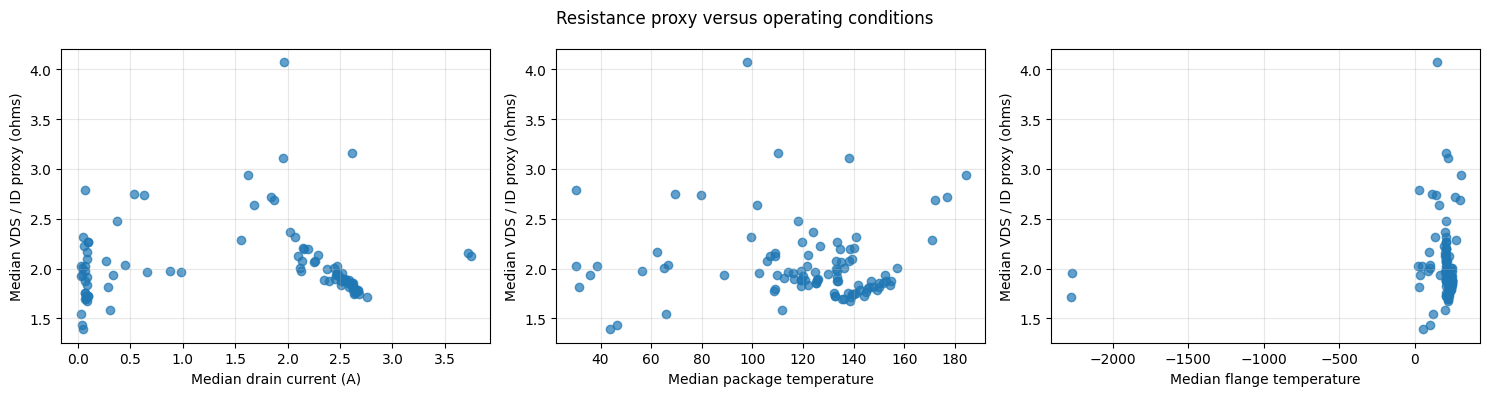

In [53]:

# CELL 51: Compare resistance proxy with operating conditions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

analysis_df = run_features_df.copy()

cols = [
    "RDS_proxy_median",
    "drain_current_median",
    "package_temp_median",
    "flange_temp_median",
    "valid_proxy_fraction"
]

for col in cols:
    analysis_df[col] = pd.to_numeric(
        analysis_df[col], errors="coerce"
    )

print("Correlation with run-level median resistance proxy:")
display(
    analysis_df[
        [
            "RDS_proxy_median",
            "drain_current_median",
            "package_temp_median",
            "flange_temp_median",
            "valid_proxy_fraction"
        ]
    ].corr(method="spearman").round(3)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

pairs = [
    ("drain_current_median", "Median drain current (A)"),
    ("package_temp_median", "Median package temperature"),
    ("flange_temp_median", "Median flange temperature")
]

for ax, (col, xlabel) in zip(axes, pairs):
    ax.scatter(
        analysis_df[col],
        analysis_df["RDS_proxy_median"],
        alpha=0.7
    )
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Median VDS / ID proxy (ohms)")
    ax.grid(True, alpha=0.3)

plt.suptitle("Resistance proxy versus operating conditions")
plt.tight_layout()
plt.show()


In [54]:

# CELL 52: Inspect candidate tests individually

candidate_test_ids = [8, 10, 11, 14, 13, 27, 34]

candidate_df = run_features_df[
    run_features_df["test_id"].isin(candidate_test_ids)
].copy()

candidate_df = candidate_df.sort_values(
    ["test_id", "start_epoch"]
)

display(
    candidate_df[
        [
            "test_id", "run_id", "filename",
            "start_epoch", "duration_seconds",
            "RDS_proxy_median", "RDS_proxy_p90",
            "drain_current_median",
            "package_temp_median", "flange_temp_median",
            "valid_proxy_count", "valid_proxy_fraction"
        ]
    ].round(4)
)

candidate_summary = (
    candidate_df.groupby("test_id")
    .agg(
        runs=("run_id", "nunique"),
        valid_runs=("RDS_proxy_median", "count"),
        median_coverage=("valid_proxy_fraction", "median"),
        first_proxy=("RDS_proxy_median", "first"),
        last_proxy=("RDS_proxy_median", "last"),
        first_package_temp=("package_temp_median", "first"),
        last_package_temp=("package_temp_median", "last")
    )
    .reset_index()
)

candidate_summary["proxy_change"] = (
    candidate_summary["last_proxy"]
    - candidate_summary["first_proxy"]
)

candidate_summary["proxy_percent_change"] = (
    100 * candidate_summary["proxy_change"]
    / candidate_summary["first_proxy"].abs().replace(0, np.nan)
)

print("\nCandidate-test summary:")
display(candidate_summary.round(4))


,test_id,run_id,filename,start_epoch,duration_seconds,RDS_proxy_median,RDS_proxy_p90,drain_current_median,package_temp_median,flange_temp_median,valid_proxy_count,valid_proxy_fraction
90,8,1,Test_8_run_1.mat,734195.3530,2099.240,1.8761,1.9736,2.5217,154.8687,247.4331,3216,0.6195
91,8,2,Test_8_run_2.mat,734195.4118,2099.129,1.8193,1.9144,2.5859,149.9753,238.1622,3058,0.5892
92,8,3,Test_8_run_3.mat,734195.4527,2099.235,1.7627,1.8513,2.6456,144.6636,228.6750,2821,0.5434
93,8,4,Test_8_run_4.mat,734195.5039,2099.390,1.7412,1.8295,2.6341,139.3659,218.6498,2670,0.5145
94,8,5,Test_8_run_5.mat,734195.5991,10799.371,2.0726,2.1902,2.2650,138.0531,208.8522,14800,0.5561
95,8,6,Test_8_run_6.mat,734199.6333,13324.608,2.2016,2.3362,2.1549,138.7001,208.8120,18899,0.5756
96,8,7,Test_8_run_7.mat,734200.7132,11785.013,2.3691,2.5579,2.0264,123.8275,200.3364,18712,0.6636
0,10,1,Test_10_run_1.mat,734213.5578,2213.977,2.0074,2.1385,2.1165,157.0315,247.4342,2803,0.5108
1,10,2,Test_10_run_2.mat,734213.5857,1970.887,1.9396,2.0337,2.4818,152.2873,238.2832,2667,0.5471
2,10,3,Test_10_run_3.mat,734213.6132,1998.006,1.8727,1.9631,2.5119,146.6353,227.9718,2495,0.5046



Candidate-test summary:


,test_id,runs,valid_runs,median_coverage,first_proxy,last_proxy,first_package_temp,last_package_temp,proxy_change,proxy_percent_change
0,8,7,7,0.5756,1.8761,2.3691,154.8687,123.8275,0.4931,26.2831
1,10,7,7,0.5108,2.0074,2.3220,157.0315,140.8877,0.3146,15.6719
2,11,7,7,0.5032,1.8510,1.9941,150.0179,133.1537,0.1432,7.7339
3,13,5,5,0.5397,1.8870,2.1666,119.0492,62.4610,0.2796,14.8196
4,14,7,7,0.5133,1.8735,2.2633,152.5719,133.5742,0.3898,20.8058
5,27,5,5,0.5594,1.8920,1.8579,125.7426,124.9864,-0.0341,-1.8028
6,34,3,3,0.5180,1.7708,2.1246,108.6111,109.0565,0.3539,19.9837


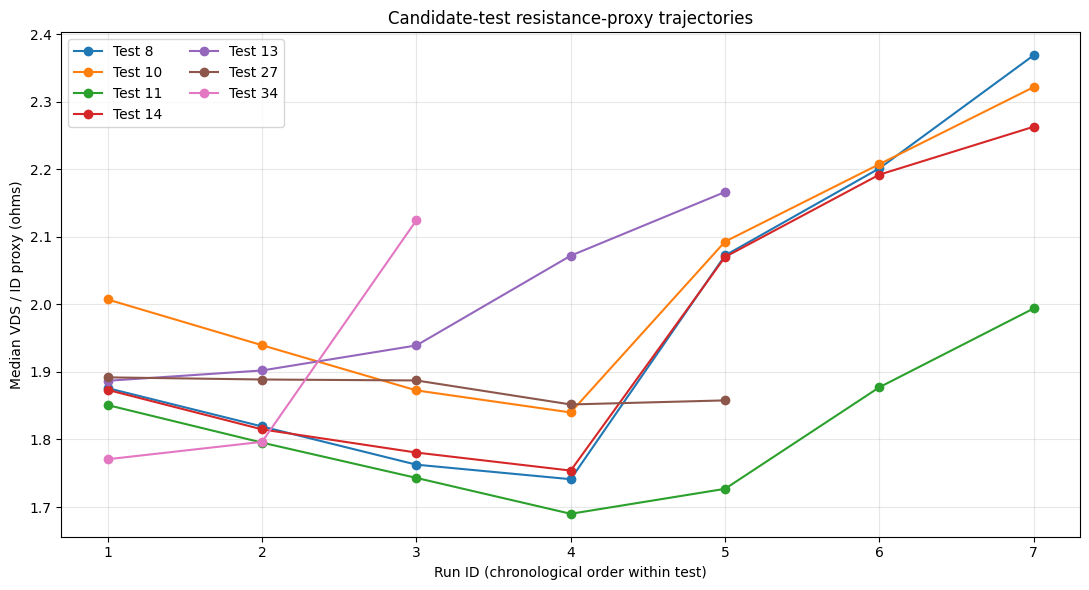

Tests plotted: 7
Reminder: run ID ordering is being checked against timestamps; the plot does not establish device aging or failure.


In [55]:

# CELL 53: Visualize proxy trends for candidate tests

plt.figure(figsize=(11, 6))

for test_id in candidate_test_ids:
    subset = candidate_df[
        candidate_df["test_id"] == test_id
    ].sort_values("start_epoch")

    valid = subset["RDS_proxy_median"].notna()

    if valid.sum() == 0:
        continue

    plt.plot(
        subset.loc[valid, "run_id"],
        subset.loc[valid, "RDS_proxy_median"],
        marker="o",
        linewidth=1.5,
        label=f"Test {test_id}"
    )

plt.xlabel("Run ID (chronological order within test)")
plt.ylabel("Median VDS / ID proxy (ohms)")
plt.title("Candidate-test resistance-proxy trajectories")
plt.legend(ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Tests plotted:", candidate_df["test_id"].nunique())
print(
    "Reminder: run ID ordering is being checked against timestamps; "
    "the plot does not establish device aging or failure."
)


In [56]:

# CELL 54: Current-threshold sensitivity across candidate runs

from pathlib import Path
from scipy.io import loadmat
import numpy as np
import pandas as pd

DATASET_DIR = Path(
    "/kaggle/working/mosfet_dataset/"
    "MOSFET_Thermal_Overstress_Aging_v0"
)

candidate_test_ids = [8, 10, 11, 13, 14, 27, 34]
thresholds = [1.5, 2.0, 2.5]

rows = []

def unwrap_scalar_or_record(value):
    value = np.asarray(value).squeeze()
    while (
        isinstance(value, np.ndarray)
        and value.dtype.names is None
        and value.size == 1
    ):
        value = value.item()
    return value

def numeric_scalar(value):
    try:
        return float(np.asarray(value).squeeze())
    except (TypeError, ValueError):
        return np.nan

for _, run in run_features_df[
    run_features_df["test_id"].isin(candidate_test_ids)
].iterrows():

    file_path = DATASET_DIR / run["filename"]
    if not file_path.exists():
        print("Skipping missing file:", file_path.name)
        continue

    mat = loadmat(
        str(file_path),
        squeeze_me=False,
        struct_as_record=True
    )
    measurement = mat["measurement"][0, 0]
    steady = measurement["steadyState"]
    records = steady.reshape(-1)

    vds_values, current_values = [], []

    for wrapped in records:
        rec = unwrap_scalar_or_record(wrapped)
        td = unwrap_scalar_or_record(rec["timeDomain"])

        vds_values.append(numeric_scalar(td["drainSourceVoltage"]))
        current_values.append(numeric_scalar(td["drainCurrent"]))

    vds = np.asarray(vds_values, dtype=float)
    current = np.asarray(current_values, dtype=float)

    for threshold in thresholds:
        mask = (
            np.isfinite(vds)
            & np.isfinite(current)
            & (vds > 0)
            & (current >= threshold)
        )
        ratios = vds[mask] / current[mask]
        ratios = ratios[np.isfinite(ratios)]

        rows.append({
            "test_id": int(run["test_id"]),
            "run_id": int(run["run_id"]),
            "filename": run["filename"],
            "threshold_A": threshold,
            "valid_samples": len(ratios),
            "valid_fraction": float(mask.mean()),
            "proxy_median": (
                float(np.median(ratios)) if len(ratios) else np.nan
            ),
            "proxy_p90": (
                float(np.percentile(ratios, 90))
                if len(ratios) else np.nan
            )
        })

threshold_sensitivity_df = pd.DataFrame(rows)

display(
    threshold_sensitivity_df.sort_values(
        ["test_id", "run_id", "threshold_A"]
    ).round(4)
)


/tmp/ipykernel_49/1792917696.py:30: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return float(np.asarray(value).squeeze())


,test_id,run_id,filename,threshold_A,valid_samples,valid_fraction,proxy_median,proxy_p90
102,8,1,Test_8_run_1.mat,1.5,3216,0.6195,1.8761,1.9736
103,8,1,Test_8_run_1.mat,2.0,3216,0.6195,1.8761,1.9736
104,8,1,Test_8_run_1.mat,2.5,2814,0.5421,1.8633,1.9425
105,8,2,Test_8_run_2.mat,1.5,3058,0.5892,1.8193,1.9144
106,8,2,Test_8_run_2.mat,2.0,3058,0.5892,1.8193,1.9144
...,...,...,...,...,...,...,...,...
97,34,2,Test_34_run_2.mat,2.0,36694,0.5180,1.7965,1.8830
98,34,2,Test_34_run_2.mat,2.5,36694,0.5180,1.7965,1.8830
99,34,3,Test_34_run_3.mat,1.5,36560,0.5547,2.1246,2.4507
100,34,3,Test_34_run_3.mat,2.0,34196,0.5188,2.1018,2.3328


In [58]:

# CELL 55: Candidate trend sensitivity summary

trend_rows = []

for threshold, group in threshold_sensitivity_df.groupby("threshold_A"):
    for test_id, test_group in group.groupby("test_id"):
        test_group = test_group.sort_values("run_id")
        usable = test_group.dropna(subset=["proxy_median"])

        if len(usable) < 2:
            continue

        first = usable.iloc[0]
        last = usable.iloc[-1]

        trend_rows.append({
            "threshold_A": threshold,
            "test_id": test_id,
            "usable_runs": len(usable),
            "first_run": int(first["run_id"]),
            "last_run": int(last["run_id"]),
            "first_proxy": first["proxy_median"],
            "last_proxy": last["proxy_median"],
            "absolute_change": (
                last["proxy_median"] - first["proxy_median"]
            ),
            "percent_change": (
                100
                * (last["proxy_median"] - first["proxy_median"])
                / abs(first["proxy_median"])
                if first["proxy_median"] != 0 else np.nan
            ),
            "median_coverage": usable["valid_fraction"].median()
        })

trend_sensitivity_df = pd.DataFrame(trend_rows)

display(
    trend_sensitivity_df.sort_values(
        ["test_id", "threshold_A"]
    ).round(4)
)

print("\nNumber of candidate-test/threshold comparisons:",
      len(trend_sensitivity_df))
print(
    "Interpretation: threshold robustness is a diagnostic, "
    "not proof of device degradation."
)


,threshold_A,test_id,usable_runs,first_run,last_run,first_proxy,last_proxy,absolute_change,percent_change,median_coverage
0,1.5,8,7,1,7,1.8761,2.3691,0.4931,26.2831,0.5756
7,2.0,8,7,1,7,1.8761,2.3380,0.4620,24.6236,0.5561
14,2.5,8,7,1,7,1.8633,1.7359,-0.1274,-6.8371,0.5145
1,1.5,10,7,1,7,2.0074,2.3220,0.3146,15.6719,0.5108
8,2.0,10,7,1,7,2.0056,2.3204,0.3147,15.6932,0.5046
15,2.5,10,7,1,7,1.9495,1.8068,-0.1428,-7.3223,0.2877
2,1.5,11,7,1,7,1.8510,1.9941,0.1432,7.7339,0.5032
9,2.0,11,7,1,7,1.8510,1.9941,0.1432,7.7339,0.5032
16,2.5,11,7,1,7,1.8509,1.9548,0.1038,5.6092,0.4766
3,1.5,13,5,1,5,1.8870,2.1666,0.2796,14.8196,0.5397



Number of candidate-test/threshold comparisons: 21
Interpretation: threshold robustness is a diagnostic, not proof of device degradation.


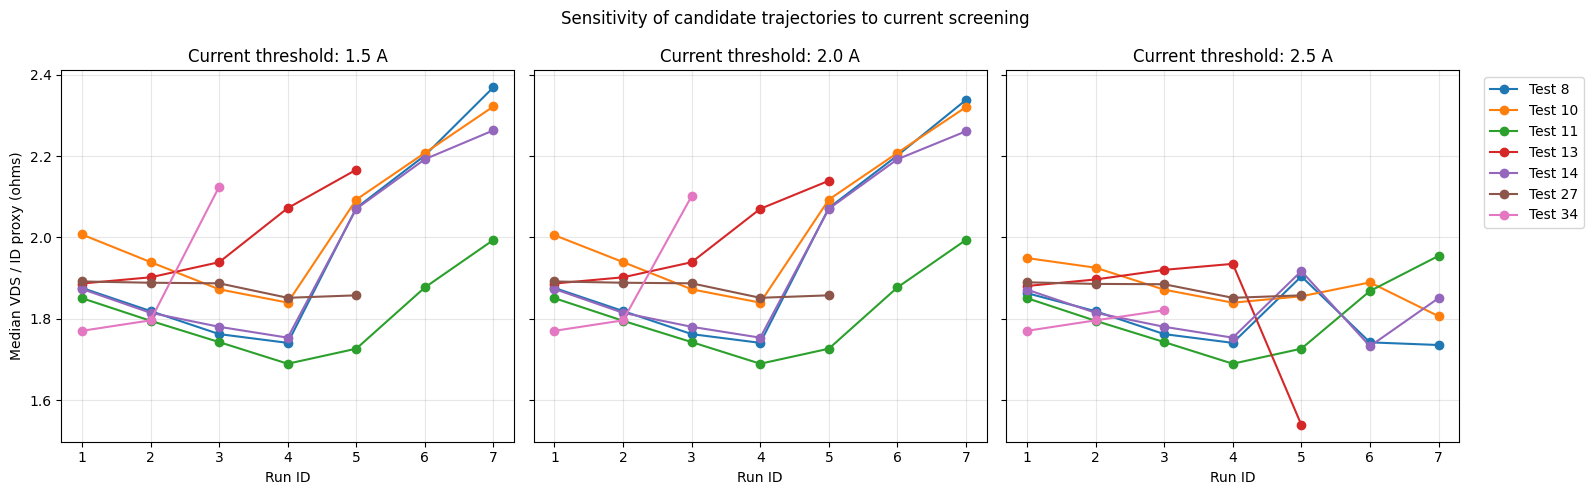

In [59]:

# CELL 56: Compare proxy trajectories at different current thresholds

if trend_sensitivity_df.empty:
    print("No candidate tests have enough usable runs for comparison.")
else:
    fig, axes = plt.subplots(
        1, len(thresholds), figsize=(16, 5), sharey=True
    )

    for ax, threshold in zip(axes, thresholds):
        subset = threshold_sensitivity_df[
            threshold_sensitivity_df["threshold_A"] == threshold
        ]

        for test_id, test_group in subset.groupby("test_id"):
            test_group = test_group.sort_values("run_id")
            valid = test_group.dropna(subset=["proxy_median"])

            if valid.empty:
                continue

            ax.plot(
                valid["run_id"],
                valid["proxy_median"],
                marker="o",
                label=f"Test {test_id}"
            )

        ax.set_title(f"Current threshold: {threshold} A")
        ax.set_xlabel("Run ID")
        ax.grid(True, alpha=0.3)

    axes[0].set_ylabel("Median VDS / ID proxy (ohms)")
    axes[-1].legend(bbox_to_anchor=(1.04, 1), loc="upper left")
    plt.suptitle("Sensitivity of candidate trajectories to current screening")
    plt.tight_layout()
    plt.show()


In [60]:

# CELL 57: Audit current and temperature coverage by candidate run

candidate_test_ids = [8, 10, 11, 13, 14, 27, 34]

candidate_runs = run_features_df[
    run_features_df["test_id"].isin(candidate_test_ids)
].copy()

coverage_cols = [
    "test_id", "run_id", "filename", "records",
    "drain_current_median", "package_temp_median",
    "flange_temp_median", "valid_proxy_count",
    "valid_proxy_fraction", "RDS_proxy_median"
]

display(
    candidate_runs[coverage_cols]
    .sort_values(["test_id", "run_id"])
    .round(4)
)

print("Candidate runs:", len(candidate_runs))
print(
    "Runs with zero valid proxy samples:",
    int((candidate_runs["valid_proxy_count"] == 0).sum())
)
print(
    "Runs with less than 25% proxy coverage:",
    int((candidate_runs["valid_proxy_fraction"] < 0.25).sum())
)

print(
    "\nNote: run-level medians summarize different operating conditions. "
    "They are not automatically comparable as aging measurements."
)


,test_id,run_id,filename,records,drain_current_median,package_temp_median,flange_temp_median,valid_proxy_count,valid_proxy_fraction,RDS_proxy_median
90,8,1,Test_8_run_1.mat,5191,2.5217,154.8687,247.4331,3216,0.6195,1.8761
91,8,2,Test_8_run_2.mat,5190,2.5859,149.9753,238.1622,3058,0.5892,1.8193
92,8,3,Test_8_run_3.mat,5191,2.6456,144.6636,228.6750,2821,0.5434,1.7627
93,8,4,Test_8_run_4.mat,5190,2.6341,139.3659,218.6498,2670,0.5145,1.7412
94,8,5,Test_8_run_5.mat,26613,2.2650,138.0531,208.8522,14800,0.5561,2.0726
95,8,6,Test_8_run_6.mat,32831,2.1549,138.7001,208.8120,18899,0.5756,2.2016
96,8,7,Test_8_run_7.mat,28199,2.0264,123.8275,200.3364,18712,0.6636,2.3691
0,10,1,Test_10_run_1.mat,5488,2.1165,157.0315,247.4342,2803,0.5108,2.0074
1,10,2,Test_10_run_2.mat,4875,2.4818,152.2873,238.2832,2667,0.5471,1.9396
2,10,3,Test_10_run_3.mat,4945,2.5119,146.6353,227.9718,2495,0.5046,1.8727


Candidate runs: 41
Runs with zero valid proxy samples: 0
Runs with less than 25% proxy coverage: 1

Note: run-level medians summarize different operating conditions. They are not automatically comparable as aging measurements.


In [61]:

# CELL 58: Quantify per-run sensitivity to current threshold

sensitivity_rows = []

for (test_id, run_id), group in threshold_sensitivity_df.groupby(
    ["test_id", "run_id"]
):
    group = group.sort_values("threshold_A")

    values = group.set_index("threshold_A")["proxy_median"]
    coverage = group.set_index("threshold_A")["valid_fraction"]

    low = values.get(1.5, np.nan)
    high = values.get(2.5, np.nan)

    sensitivity_rows.append({
        "test_id": test_id,
        "run_id": run_id,
        "proxy_at_1_5A": low,
        "proxy_at_2_0A": values.get(2.0, np.nan),
        "proxy_at_2_5A": high,
        "coverage_at_1_5A": coverage.get(1.5, np.nan),
        "coverage_at_2_0A": coverage.get(2.0, np.nan),
        "coverage_at_2_5A": coverage.get(2.5, np.nan),
        "change_1_5A_to_2_5A": (
            high - low
            if pd.notna(low) and pd.notna(high)
            else np.nan
        )
    })

run_threshold_sensitivity_df = pd.DataFrame(sensitivity_rows)

display(
    run_threshold_sensitivity_df
    .sort_values(["test_id", "run_id"])
    .round(4)
)

print(
    "Runs where proxy changes by more than 10% between thresholds:",
    int(
        (
            run_threshold_sensitivity_df["change_1_5A_to_2_5A"].abs()
            / run_threshold_sensitivity_df["proxy_at_1_5A"].abs()
            > 0.10
        ).fillna(False).sum()
    )
)


,test_id,run_id,proxy_at_1_5A,proxy_at_2_0A,proxy_at_2_5A,coverage_at_1_5A,coverage_at_2_0A,coverage_at_2_5A,change_1_5A_to_2_5A
0,8,1,1.8761,1.8761,1.8633,0.6195,0.6195,0.5421,-0.0128
1,8,2,1.8193,1.8193,1.8188,0.5892,0.5892,0.5884,-0.0005
2,8,3,1.7627,1.7627,1.7627,0.5434,0.5434,0.5434,0.0000
3,8,4,1.7412,1.7412,1.7412,0.5145,0.5145,0.5145,0.0000
4,8,5,2.0726,2.0726,1.9044,0.5561,0.5561,0.0620,-0.1681
5,8,6,2.2016,2.2013,1.7425,0.5756,0.5742,0.0047,-0.4591
6,8,7,2.3691,2.3380,1.7359,0.6636,0.5477,0.0052,-0.6332
7,10,1,2.0074,2.0056,1.9495,0.5108,0.5044,0.2877,-0.0579
8,10,2,1.9396,1.9396,1.9258,0.5471,0.5471,0.4765,-0.0138
9,10,3,1.8727,1.8727,1.8718,0.5046,0.5046,0.5025,-0.0009


Runs where proxy changes by more than 10% between thresholds: 9


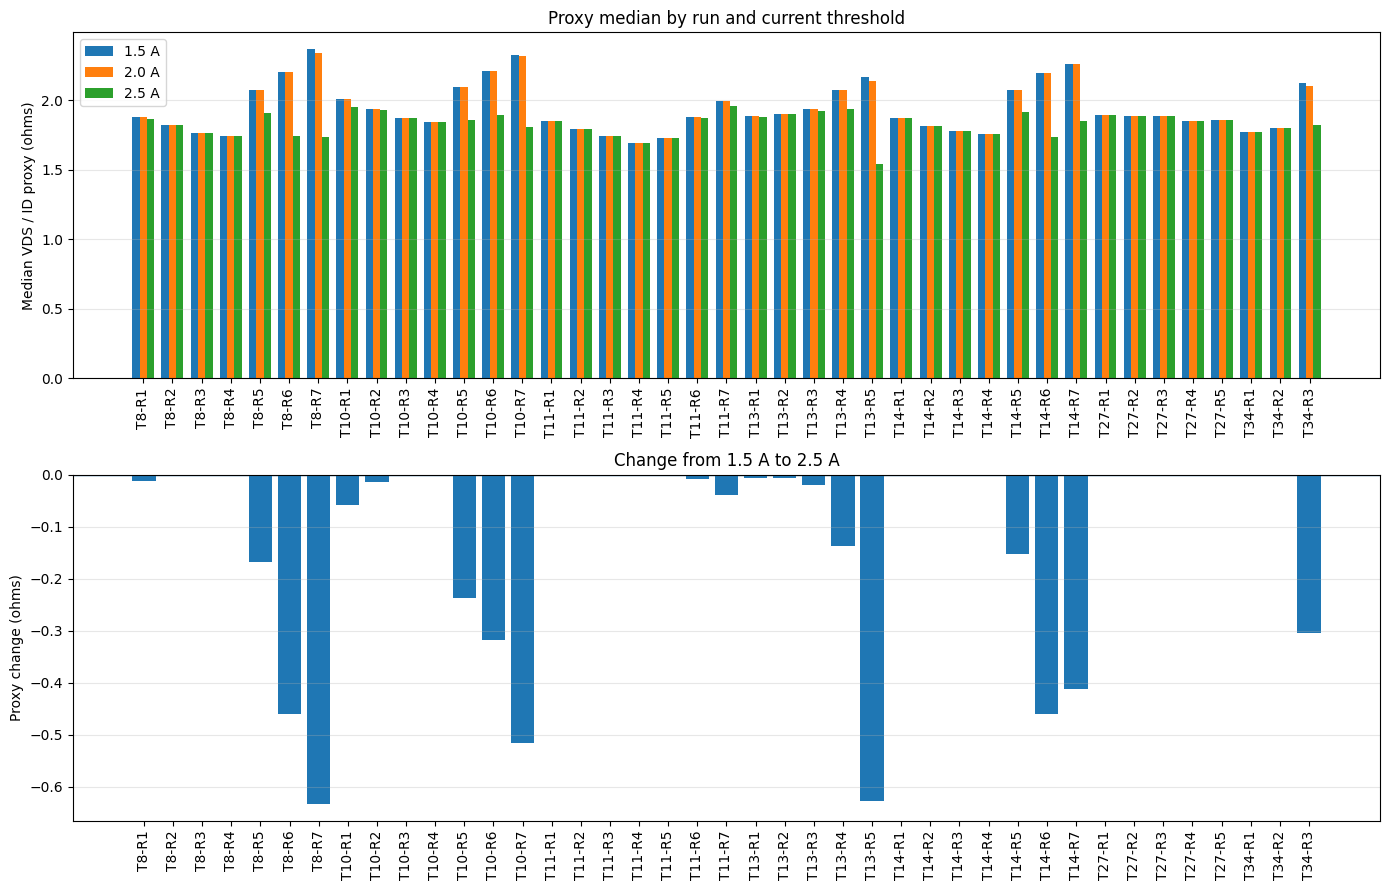

In [62]:

# CELL 59: Visualize per-run threshold sensitivity

plot_df = run_threshold_sensitivity_df.copy()
plot_df["run_label"] = (
    "T" + plot_df["test_id"].astype(str)
    + "-R" + plot_df["run_id"].astype(str)
)

plot_df = plot_df.sort_values(["test_id", "run_id"])

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

x = np.arange(len(plot_df))
width = 0.25

axes[0].bar(
    x - width,
    plot_df["proxy_at_1_5A"],
    width,
    label="1.5 A"
)
axes[0].bar(
    x,
    plot_df["proxy_at_2_0A"],
    width,
    label="2.0 A"
)   
axes[0].bar(
    x + width,
    plot_df["proxy_at_2_5A"],
    width,
    label="2.5 A"
)

axes[0].set_ylabel("Median VDS / ID proxy (ohms)")
axes[0].set_title("Proxy median by run and current threshold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(plot_df["run_label"], rotation=90)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    x,
    plot_df["change_1_5A_to_2_5A"]
)
axes[1].axhline(0, linewidth=1)
axes[1].set_ylabel("Proxy change (ohms)")
axes[1].set_title("Change from 1.5 A to 2.5 A")
axes[1].set_xticks(x)
axes[1].set_xticklabels(plot_df["run_label"], rotation=90)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
  

In [63]:

# CELL 60: Flag low-coverage and threshold-sensitive runs

audit_df = run_threshold_sensitivity_df.copy()

audit_df["relative_threshold_change"] = (
    audit_df["change_1_5A_to_2_5A"].abs()
    / audit_df["proxy_at_1_5A"].abs().replace(0, np.nan)
)

audit_df["flag_low_2_5A_coverage"] = (
    audit_df["coverage_at_2_5A"] < 0.10
)

audit_df["flag_threshold_sensitive"] = (
    audit_df["relative_threshold_change"] > 0.10
)

audit_df["flag_low_1_5A_coverage"] = (
    audit_df["coverage_at_1_5A"] < 0.25
)

print("Quality-flag counts:")
display(
    audit_df[
        [
            "flag_low_1_5A_coverage",
            "flag_low_2_5A_coverage",
            "flag_threshold_sensitive"
        ]
    ].sum().to_frame("number_of_runs")
)

print("\nRuns requiring review:")
display(
    audit_df.loc[
        audit_df[
            [
                "flag_low_1_5A_coverage",
                "flag_low_2_5A_coverage",
                "flag_threshold_sensitive"
            ]
        ].any(axis=1),
        [
            "test_id", "run_id",
            "coverage_at_1_5A", "coverage_at_2_5A",
            "proxy_at_1_5A", "proxy_at_2_5A",
            "relative_threshold_change",
            "flag_low_1_5A_coverage",
            "flag_low_2_5A_coverage",
            "flag_threshold_sensitive"
        ]
    ].sort_values(["test_id", "run_id"]).round(4)
)


Quality-flag counts:


,number_of_runs
flag_low_1_5A_coverage,1
flag_low_2_5A_coverage,8
flag_threshold_sensitive,9



Runs requiring review:


,test_id,run_id,coverage_at_1_5A,coverage_at_2_5A,proxy_at_1_5A,proxy_at_2_5A,relative_threshold_change,flag_low_1_5A_coverage,flag_low_2_5A_coverage,flag_threshold_sensitive
4,8,5,0.5561,0.0620,2.0726,1.9044,0.0811,False,True,False
5,8,6,0.5756,0.0047,2.2016,1.7425,0.2085,False,True,True
6,8,7,0.6636,0.0052,2.3691,1.7359,0.2673,False,True,True
11,10,5,0.4984,0.1597,2.0931,1.8556,0.1135,False,False,True
12,10,6,0.5238,0.0055,2.2078,1.8897,0.1441,False,True,True
13,10,7,0.5376,0.0041,2.3220,1.8068,0.2219,False,True,True
25,13,5,0.2162,0.0544,2.1666,1.5398,0.2893,True,True,True
31,14,6,0.5436,0.0044,2.1923,1.7330,0.2095,False,True,True
32,14,7,0.4031,0.0184,2.2633,1.8510,0.1822,False,True,True
40,34,3,0.5547,0.2315,2.1246,1.8212,0.1428,False,False,True


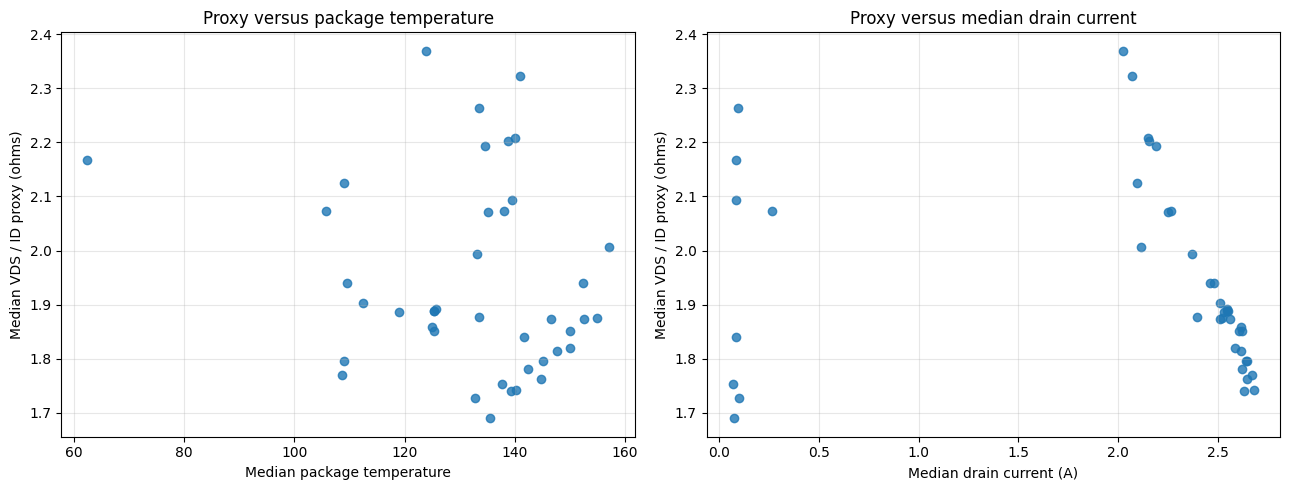

Pearson correlations for candidate runs:


,RDS_proxy_median,package_temp_median,drain_current_median
RDS_proxy_median,1.000,-0.201,-0.176
package_temp_median,-0.201,1.000,0.235
drain_current_median,-0.176,0.235,1.000


In [64]:

# CELL 61: Temperature versus resistance-proxy changes

temperature_df = run_features_df[
    run_features_df["test_id"].isin(candidate_test_ids)
].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    temperature_df["package_temp_median"],
    temperature_df["RDS_proxy_median"],
    alpha=0.8
)
axes[0].set_xlabel("Median package temperature")
axes[0].set_ylabel("Median VDS / ID proxy (ohms)")
axes[0].set_title("Proxy versus package temperature")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(
    temperature_df["drain_current_median"],
    temperature_df["RDS_proxy_median"],
    alpha=0.8
)
axes[1].set_xlabel("Median drain current (A)")
axes[1].set_ylabel("Median VDS / ID proxy (ohms)")
axes[1].set_title("Proxy versus median drain current")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Pearson correlations for candidate runs:")
display(
    temperature_df[
        [
            "RDS_proxy_median",
            "package_temp_median",
            "drain_current_median"
        ]
    ].corr().round(3)
)


In [65]:

# CELL 62: Research-readiness summary

summary = {
    "valid_runs": int(len(run_features_df)),
    "unique_tests": int(run_features_df["test_id"].nunique()),
    "candidate_runs": int(len(temperature_df)),
    "candidate_runs_with_proxy": int(
        temperature_df["RDS_proxy_median"].notna().sum()
    ),
    "threshold_sensitive_runs": int(
        audit_df["flag_threshold_sensitive"].sum()
    ),
    "runs_with_less_than_10pct_coverage_at_2_5A": int(
        audit_df["flag_low_2_5A_coverage"].sum()
    ),
    "runs_with_nonpositive_flange_median": int(
        (run_features_df["flange_temp_median"] <= 0).sum()
    )
}

display(pd.Series(summary, name="value").to_frame())

print(
    "\nResearch status: exploratory feature analysis and quality auditing. "
    "A validated failure endpoint and defensible lifetime target are still "
    "required before supervised RUL training."
)


,value
valid_runs,104
unique_tests,42
candidate_runs,41
candidate_runs_with_proxy,41
threshold_sensitive_runs,9
runs_with_less_than_10pct_coverage_at_2_5A,8
runs_with_nonpositive_flange_median,2



Research status: exploratory feature analysis and quality auditing. A validated failure endpoint and defensible lifetime target are still required before supervised RUL training.


In [66]:

# CELL 63: Search available metadata for possible failure indicators

from pathlib import Path
import re
import pandas as pd
import numpy as np
from scipy.io import loadmat

keywords = re.compile(
    r"fail|failure|fault|breakdown|shutdown|end.?of.?life|"
    r"eol|lifetime|degrad|damage|stop.?test",
    re.IGNORECASE
)

print("Potentially relevant inventory columns:")
display(pd.DataFrame({
    "column": inventory_df.columns,
    "dtype": [str(inventory_df[c].dtype) for c in inventory_df.columns]
}))

print("\nFilenames matching endpoint-related terms:")
display(
    inventory_df[
        inventory_df["filename"].str.contains(
            keywords, na=False
        )
    ][["filename", "test_id", "run_id", "size_MB"]]
)

print(
    "\nNote: no filename or metadata match does not prove "
    "the dataset lacks endpoint information."
)


Potentially relevant inventory columns:


,column,dtype
0,filename,object
1,test_id,float64
2,run_id,float64
3,size_MB,float64
4,possible_setup_error,bool
5,path,object



Filenames matching endpoint-related terms:


,filename,test_id,run_id,size_MB



Note: no filename or metadata match does not prove the dataset lacks endpoint information.


In [67]:

# CELL 64: Inspect controller settings across selected runs

selected_files = [
    "Test_8_run_1.mat",
    "Test_8_run_7.mat",
    "Test_20_run_1.mat",
    "Test_34_run_3.mat"
]

controller_rows = []

for filename in selected_files:
    matches = inventory_df[inventory_df["filename"] == filename]

    if matches.empty:
        print("Skipping missing file:", filename)
        continue

    mat = loadmat(str(matches.iloc[0]["path"]))
    measurement = mat["measurement"][0, 0]
    controller = measurement["pwmTempControllerState"][0, 0]

    def unwrap_scalar(x):
        arr = np.asarray(x).squeeze()
        while isinstance(arr, np.ndarray) and arr.size == 1:
            arr = arr.item()
        try:
            return float(arr)
        except (TypeError, ValueError):
            return np.nan

    row = {"filename": filename}

    for field in [
        "lowTemp", "highTemp", "shutdownTemp",
        "gateVoltage", "supplyVoltage",
        "switchingFrequency", "dutyCycle", "gateState"
    ]:
        if field not in controller.dtype.names:
            continue

        values = [
            unwrap_scalar(x)
            for x in np.asarray(controller[field]).reshape(-1)
        ]
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]

        if values.size:
            row[f"{field}_min"] = values.min()
            row[f"{field}_max"] = values.max()
            row[f"{field}_unique_count"] = np.unique(values).size

    controller_rows.append(row)

display(pd.DataFrame(controller_rows).round(4))


,filename,lowTemp_min,lowTemp_max,lowTemp_unique_count,highTemp_min,highTemp_max,highTemp_unique_count,shutdownTemp_min,shutdownTemp_max,shutdownTemp_unique_count,...,supplyVoltage_unique_count,switchingFrequency_min,switchingFrequency_max,switchingFrequency_unique_count,dutyCycle_min,dutyCycle_max,dutyCycle_unique_count,gateState_min,gateState_max,gateState_unique_count
0,Test_8_run_1.mat,39.0,39.0,1,40.0,40.0,1,280.0,280.0,1,...,1,1000.0,1000.0,1,40.0,40.0,1,0.0,0.0,1
1,Test_8_run_7.mat,39.0,39.0,1,40.0,40.0,1,280.0,280.0,1,...,1,1000.0,1000.0,1,40.0,40.0,1,0.0,0.0,1
2,Test_20_run_1.mat,39.0,39.0,1,40.0,40.0,1,250.0,250.0,1,...,1,1000.0,1000.0,1,40.0,40.0,1,0.0,0.0,1
3,Test_34_run_3.mat,39.0,39.0,1,40.0,40.0,1,240.0,240.0,1,...,1,1000.0,1000.0,1,40.0,40.0,1,0.0,0.0,1


In [68]:

# CELL 65: Compare run IDs with recorded timestamps

chronology_df = run_features_df.sort_values(
    ["test_id", "start_epoch"]
).copy()

chronology_df["timestamp_order"] = (
    chronology_df.groupby("test_id").cumcount() + 1
)

chronology_df["run_id_matches_timestamp_order"] = (
    chronology_df["run_id"] == chronology_df["timestamp_order"]
)

print("Runs checked:", len(chronology_df))
print(
    "Runs where run ID matches timestamp order:",
    int(chronology_df["run_id_matches_timestamp_order"].sum())
)
print(
    "Runs where run ID differs from timestamp order:",
    int((~chronology_df["run_id_matches_timestamp_order"]).sum())
)

print("\nExamples where the ordering differs:")
display(
    chronology_df.loc[
        ~chronology_df["run_id_matches_timestamp_order"],
        [
            "filename", "test_id", "run_id",
            "timestamp_order", "start_epoch", "end_epoch"
        ]
    ].head(20)
)

print(
    "\nChronological ordering is not proof of aging: "
    "the recorded runs must also represent successive stages "
    "of the same device's life."
)


Runs checked: 104
Runs where run ID matches timestamp order: 104
Runs where run ID differs from timestamp order: 0

Examples where the ordering differs:


,filename,test_id,run_id,timestamp_order,start_epoch,end_epoch



Chronological ordering is not proof of aging: the recorded runs must also represent successive stages of the same device's life.


In [69]:
# CELL 66: Per-test trajectory table (does each test look like one aging sequence?)
import numpy as np
import pandas as pd
from IPython.display import display

print("run_features_df columns:\n", list(run_features_df.columns), "\n")

df = run_features_df.sort_values(["test_id", "start_epoch"]).copy()

rows = []
for test_id, g in df.groupby("test_id"):
    g = g.sort_values("start_epoch")
    # ASSUMPTION: timeEpoch is in days (MATLAB datenum). Verify against paper's time scale.
    gaps_h = ((g["start_epoch"].values[1:] - g["end_epoch"].values[:-1]) * 24).tolist()
    rows.append({
        "test_id": test_id,
        "n_runs": len(g),
        "run_ids": g["run_id"].tolist(),
        "total_span_h": (g["end_epoch"].max() - g["start_epoch"].min()) * 24,
        "sum_run_duration_h": g["duration_seconds"].sum() / 3600,
        "max_gap_between_runs_h": max(gaps_h) if gaps_h else np.nan,
        "proxy_first": g["RDS_proxy_median"].iloc[0],
        "proxy_last": g["RDS_proxy_median"].iloc[-1],
        "proxy_last_over_first": (g["RDS_proxy_median"].iloc[-1] / g["RDS_proxy_median"].iloc[0])
                                 if g["RDS_proxy_median"].iloc[0] not in (0, np.nan) else np.nan,
        "min_valid_fraction": g["valid_proxy_fraction"].min(),
    })

traj_df = pd.DataFrame(rows).sort_values("n_runs", ascending=False)
display(traj_df.round(3).reset_index(drop=True))

print("\nTests with >=3 runs (candidate aging trajectories):", int((traj_df["n_runs"] >= 3).sum()))
print("Tests with 1 run:", int((traj_df["n_runs"] == 1).sum()))
print("Distribution of runs per test:")
print(traj_df["n_runs"].value_counts().sort_index())

run_features_df columns:
 ['filename', 'test_id', 'run_id', 'records', 'start_epoch', 'end_epoch', 'duration_seconds', 'timestamps_monotonic', 'valid_proxy_count', 'valid_proxy_fraction', 'RDS_proxy_median', 'RDS_proxy_p90', 'package_temp_median', 'flange_temp_median', 'drain_current_median', 'invalid_package_temp_count', 'invalid_current_count', 'invalid_voltage_count'] 



,test_id,n_runs,run_ids,total_span_h,sum_run_duration_h,max_gap_between_runs_h,proxy_first,proxy_last,proxy_last_over_first,min_valid_fraction
0,10,7,"[1, 2, 3, 4, 5, 6, 7]",49.315,13.338,23.277,2.007,2.322,1.157,0.486
1,9,7,"[1, 2, 3, 4, 5, 6, 7]",52.693,13.332,19.446,1.834,2.073,1.131,0.448
2,8,7,"[1, 2, 3, 4, 5, 6, 7]",131.919,12.307,93.823,1.876,2.369,1.263,0.514
3,14,7,"[1, 2, 3, 4, 5, 6, 7]",42.587,10.372,15.386,1.873,2.263,1.208,0.403
4,12,7,"[1, 2, 3, 4, 5, 6, 7]",49.272,12.915,17.217,1.860,1.977,1.063,0.374
5,11,7,"[1, 2, 3, 4, 5, 6, 7]",66.229,13.332,22.371,1.851,1.994,1.077,0.465
6,13,5,"[1, 2, 3, 4, 5]",3.510,2.273,0.531,1.887,2.167,1.148,0.216
7,27,5,"[1, 2, 3, 4, 5]",26.517,2.999,21.034,1.892,1.858,0.982,0.549
8,25,4,"[1, 2, 3, 4]",73.962,10.283,52.687,1.829,NaN,NaN,0.000
9,2,3,"[1, 2, 3]",1.312,0.850,0.303,1.390,2.317,1.667,0.118



Tests with >=3 runs (candidate aging trajectories): 11
Tests with 1 run: 20
Distribution of runs per test:
n_runs
1    20
2    11
3     2
4     1
5     2
7     6
Name: count, dtype: int64


In [70]:
# CELL 67: Controller settings (stress conditions) for every run, cached to CSV
import os
import numpy as np
import pandas as pd
from scipy.io import loadmat
from IPython.display import display

CACHE = "/kaggle/working/controller_settings.csv"

def unwrap_scalar(x):
    arr = np.asarray(x).squeeze()
    while isinstance(arr, np.ndarray) and arr.dtype == object and arr.size == 1:
        arr = np.asarray(arr.item()).squeeze()
    try:
        return float(np.asarray(arr).reshape(-1)[0])
    except Exception:
        return np.nan

fields = ["lowTemp", "highTemp", "shutdownTemp", "gateVoltage",
          "supplyVoltage", "switchingFrequency", "dutyCycle"]

if os.path.exists(CACHE):
    ctrl_df = pd.read_csv(CACHE)
    print("Loaded cache:", CACHE)
else:
    rows = []
    for _, r in valid_inventory.dropna(subset=["test_id", "run_id"]).iterrows():
        try:
            m = loadmat(str(r["path"]))["measurement"][0, 0]
            c = m["pwmTempControllerState"][0, 0]
            row = {"filename": r["filename"], "test_id": int(r["test_id"]), "run_id": int(r["run_id"])}
            for f in fields:
                if f in c.dtype.names:
                    vals = np.array([unwrap_scalar(v) for v in np.asarray(c[f]).reshape(-1)], dtype=float)
                    vals = vals[np.isfinite(vals)]
                    row[f] = float(np.median(vals)) if vals.size else np.nan
                    row[f + "_nunique"] = int(np.unique(vals).size) if vals.size else 0
            rows.append(row)
        except Exception as e:
            print("Skipped", r["filename"], "->", type(e).__name__, e)
    ctrl_df = pd.DataFrame(rows)
    ctrl_df.to_csv(CACHE, index=False)
    print("Saved cache:", CACHE)

print("Runs with controller settings:", len(ctrl_df))
display(ctrl_df.head(10).round(3))

setting_cols = [f for f in fields if f in ctrl_df.columns]
print("\nUnique value combinations of stress settings across tests:")
combo = (ctrl_df.groupby("test_id")[setting_cols]
         .agg(lambda s: tuple(sorted(set(np.round(s.dropna(), 3))))))
display(combo.head(45))

# Do settings change between runs of the same test? (if yes, runs are not identical-condition repeats)
changes = ctrl_df.groupby("test_id")[setting_cols].nunique(dropna=True)
print("\nTests where a setting changes between runs:")
display((changes > 1).sum().to_frame("n_tests_with_change"))

Saved cache: /kaggle/working/controller_settings.csv
Runs with controller settings: 104


,filename,test_id,run_id,lowTemp,lowTemp_nunique,highTemp,highTemp_nunique,shutdownTemp,shutdownTemp_nunique,gateVoltage,gateVoltage_nunique,supplyVoltage,supplyVoltage_nunique,switchingFrequency,switchingFrequency_nunique,dutyCycle,dutyCycle_nunique
0,Test_10_run_1.mat,10,1,39.0,1,40.0,1,280.0,1,10.0,1,5.0,1,1000.0,1,40.0,1
1,Test_10_run_2.mat,10,2,39.0,1,40.0,1,280.0,1,10.0,1,5.0,1,1000.0,1,40.0,1
2,Test_10_run_3.mat,10,3,39.0,1,40.0,1,280.0,1,10.0,1,5.0,1,1000.0,1,40.0,1
3,Test_10_run_4.mat,10,4,39.0,1,40.0,1,280.0,1,10.0,1,5.0,1,1000.0,1,40.0,1
4,Test_10_run_5.mat,10,5,39.0,1,40.0,1,280.0,1,10.0,1,5.0,1,1000.0,1,40.0,1
5,Test_10_run_6.mat,10,6,39.0,1,40.0,1,280.0,1,10.0,1,5.0,1,1000.0,1,40.0,1
6,Test_10_run_7.mat,10,7,39.0,1,40.0,1,280.0,1,10.0,1,5.0,1,1000.0,1,40.0,1
7,Test_11_run_1.mat,11,1,39.0,1,40.0,1,280.0,1,10.0,1,5.0,1,1000.0,1,40.0,1
8,Test_11_run_2.mat,11,2,39.0,1,40.0,1,280.0,1,10.0,1,5.0,1,1000.0,1,40.0,1
9,Test_11_run_3.mat,11,3,39.0,1,40.0,1,280.0,1,10.0,1,5.0,1,1000.0,1,40.0,1



Unique value combinations of stress settings across tests:


,lowTemp,highTemp,shutdownTemp,gateVoltage,supplyVoltage,switchingFrequency,dutyCycle
test_id,,,,,,,
1,"(99.0,)","(100.0,)","(120.0,)","(5.25, 10.0)","(2.0, 5.0)","(1000.0,)","(40.0,)"
2,"(34.0,)","(35.0,)","(260.0,)","(10.0,)","(5.0,)","(1000.0,)","(40.0,)"
3,"(34.0,)","(35.0,)","(260.0,)","(10.0,)","(5.0,)","(1000.0,)","(40.0,)"
4,"(34.0, 39.0)","(35.0, 40.0)","(230.0,)","(10.0,)","(5.0,)","(1000.0,)","(40.0,)"
5,"(39.0,)","(40.0,)","(230.0,)","(10.0,)","(5.0,)","(1000.0,)","(40.0,)"
6,"(39.0,)","(40.0,)","(300.0,)","(10.0,)","(5.0,)","(1000.0,)","(40.0,)"
7,"(39.0,)","(40.0,)","(300.0,)","(10.0,)","(5.0,)","(1000.0,)","(40.0,)"
8,"(39.0,)","(40.0,)","(280.0,)","(10.0,)","(5.0,)","(1000.0,)","(40.0,)"
9,"(39.0,)","(40.0,)","(280.0,)","(10.0,)","(5.0,)","(1000.0,)","(40.0,)"



Tests where a setting changes between runs:


,n_tests_with_change
lowTemp,1
highTemp,1
shutdownTemp,3
gateVoltage,1
supplyVoltage,1
switchingFrequency,0
dutyCycle,0


Temperature-related columns available: ['package_temp_median', 'flange_temp_median', 'invalid_package_temp_count']
Tests with >=3 runs and valid proxy: 11


,test_id,n_runs,spearman_proxy_vs_time,p_value,spearman_package_temp_median_vs_time,spearman_flange_temp_median_vs_time
0,2,3,1.000,0.000,1.000,1.000
1,25,3,1.000,0.000,-1.000,-1.000
2,34,3,1.000,0.000,1.000,-0.500
3,13,5,1.000,0.000,-1.000,-1.000
4,8,7,0.643,0.119,-0.964,-1.000
5,14,7,0.643,0.119,-1.000,-1.000
6,10,7,0.643,0.119,-0.857,-1.000
7,9,7,0.393,0.383,-0.893,-0.964
8,12,7,0.393,0.383,-0.893,-1.000
9,11,7,0.321,0.482,-0.893,-1.000



Tests with strong upward proxy trend (rho > 0.7): 4 of 11


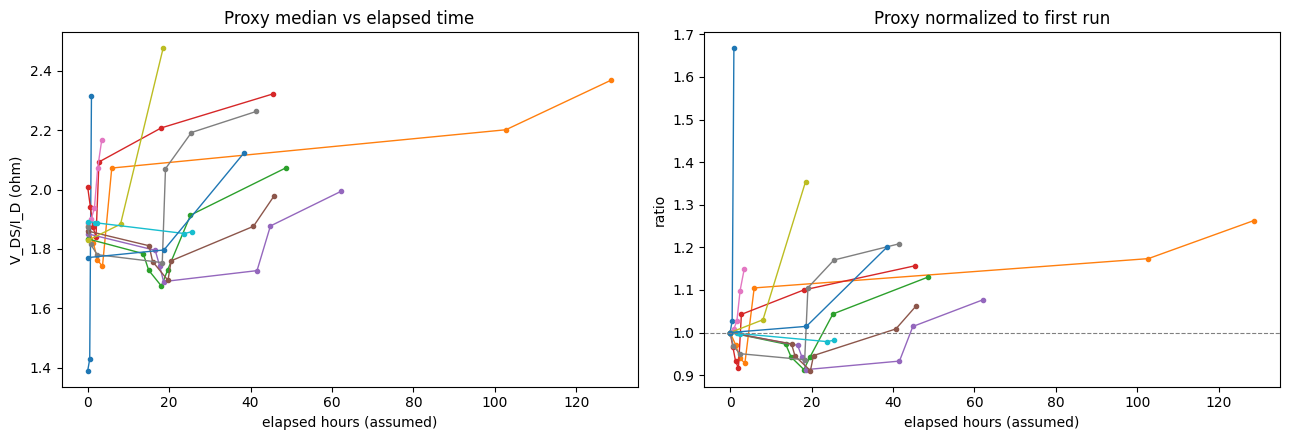

In [71]:
# CELL 68: Does the resistance proxy trend across runs within a test?
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display

df = run_features_df.sort_values(["test_id", "start_epoch"]).copy()
temp_cols = [c for c in df.columns if "temp" in c.lower()]
print("Temperature-related columns available:", temp_cols)

df["elapsed_h"] = df.groupby("test_id")["start_epoch"].transform(lambda s: (s - s.min()) * 24)  # assumes days

multi = df.groupby("test_id").filter(lambda g: len(g) >= 3 and g["RDS_proxy_median"].notna().sum() >= 3)
print("Tests with >=3 runs and valid proxy:", multi["test_id"].nunique())

trend_rows = []
for tid, g in multi.groupby("test_id"):
    g = g.dropna(subset=["RDS_proxy_median"])
    rho, p = spearmanr(g["elapsed_h"], g["RDS_proxy_median"])
    out = {"test_id": tid, "n_runs": len(g), "spearman_proxy_vs_time": rho, "p_value": p}
    for tc in temp_cols[:2]:
        if g[tc].notna().sum() >= 3:
            out[f"spearman_{tc}_vs_time"] = spearmanr(g["elapsed_h"], g[tc])[0]
    trend_rows.append(out)

trend_df = pd.DataFrame(trend_rows).sort_values("spearman_proxy_vs_time", ascending=False)
display(trend_df.round(3).reset_index(drop=True))

n_pos = int((trend_df["spearman_proxy_vs_time"] > 0.7).sum())
print(f"\nTests with strong upward proxy trend (rho > 0.7): {n_pos} of {len(trend_df)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for tid, g in multi.groupby("test_id"):
    g = g.dropna(subset=["RDS_proxy_median"])
    axes[0].plot(g["elapsed_h"], g["RDS_proxy_median"], marker="o", ms=3, lw=1, label=str(tid))
    axes[1].plot(g["elapsed_h"], g["RDS_proxy_median"] / g["RDS_proxy_median"].iloc[0],
                 marker="o", ms=3, lw=1)
axes[0].set(title="Proxy median vs elapsed time", xlabel="elapsed hours (assumed)", ylabel="V_DS/I_D (ohm)")
axes[1].set(title="Proxy normalized to first run", xlabel="elapsed hours (assumed)", ylabel="ratio")
axes[1].axhline(1, color="gray", ls="--", lw=0.8)
plt.tight_layout(); plt.show()

In [72]:
# CELL 69: Extract record-level steady-state data for the six 7-run tests
import os
import numpy as np
import pandas as pd
from scipy.io import loadmat
from IPython.display import display

TARGET_TESTS = [8, 9, 10, 11, 12, 14]
CACHE = "/kaggle/working/stage_records.pkl"
fields = ["packageTemperature", "drainSourceVoltage", "drainCurrent", "flangeTemperature"]

def load_run_records(path):
    steady = loadmat(str(path))["measurement"]["steadyState"][0, 0]
    td = steady["timeDomain"].reshape(-1)
    raw_epochs = np.asarray(steady["timeEpoch"]).reshape(-1)
    epochs = np.array([extract_record_scalar({"value": v}, "value") for v in raw_epochs], dtype=float)
    n = len(td)
    if len(epochs) != n:
        raise ValueError(f"epoch count {len(epochs)} != record count {n}")
    vals = {f: np.full(n, np.nan) for f in fields}
    for i, w in enumerate(td):
        rec = np.asarray(w).squeeze()
        while isinstance(rec, np.ndarray) and rec.dtype.names is None and rec.size == 1:
            rec = rec.item()
        if getattr(getattr(rec, "dtype", None), "names", None) is None:
            continue
        for f in fields:
            vals[f][i] = extract_record_scalar(rec, f)
    out = pd.DataFrame(vals)
    out["epoch"] = epochs
    return out

if os.path.exists(CACHE):
    rec_df = pd.read_pickle(CACHE)
    print("Loaded cache:", CACHE)
else:
    parts = []
    sel = (valid_inventory[valid_inventory["test_id"].isin(TARGET_TESTS)]
           .sort_values(["test_id", "run_id"]))
    for _, r in sel.iterrows():
        try:
            d = load_run_records(r["path"])
            d["test_id"] = int(r["test_id"])
            d["run_id"] = int(r["run_id"])
            parts.append(d)
            print(f"Loaded test {int(r['test_id'])} run {int(r['run_id'])}: {len(d)} records")
        except Exception as e:
            print("Skipped", r["filename"], "->", type(e).__name__, e)
    rec_df = pd.concat(parts, ignore_index=True)
    rec_df = rec_df.sort_values(["test_id", "run_id", "epoch"]).reset_index(drop=True)

    # ASSUMPTION: epoch is in days. Stress time = cumulative recorded run duration (excludes idle gaps).
    g = rec_df.groupby(["test_id", "run_id"])["epoch"]
    rec_df["run_start"] = g.transform("min")
    run_dur_h = (g.max() - g.min()) * 24
    offsets = (run_dur_h.groupby(level=0).cumsum() - run_dur_h).rename("run_offset_h")
    rec_df = rec_df.merge(offsets.reset_index(), on=["test_id", "run_id"], how="left")
    rec_df["stress_h"] = rec_df["run_offset_h"] + (rec_df["epoch"] - rec_df["run_start"]) * 24
    rec_df.to_pickle(CACHE)
    print("Saved cache:", CACHE)

print("\nTotal records:", len(rec_df))
summ = (rec_df.groupby(["test_id", "run_id"])
        .agg(n=("epoch", "size"), stress_h_start=("stress_h", "min"), stress_h_end=("stress_h", "max"),
             I_median=("drainCurrent", "median"), pkgT_median=("packageTemperature", "median"))
        .round(3))
display(summ)
print("\nTotal stress hours per test:")
display(rec_df.groupby("test_id")["stress_h"].max().round(2).to_frame("total_stress_h"))

Loaded test 8 run 1: 5191 records
Loaded test 8 run 2: 5190 records
Loaded test 8 run 3: 5191 records
Loaded test 8 run 4: 5190 records
Loaded test 8 run 5: 26613 records
Loaded test 8 run 6: 32831 records
Loaded test 8 run 7: 28199 records
Loaded test 9 run 1: 5184 records
Loaded test 9 run 2: 5176 records
Loaded test 9 run 3: 5177 records
Loaded test 9 run 4: 5176 records
Loaded test 9 run 5: 26600 records
Loaded test 9 run 6: 35422 records
Loaded test 9 run 7: 35397 records
Loaded test 10 run 1: 5488 records
Loaded test 10 run 2: 4875 records
Loaded test 10 run 3: 4945 records
Loaded test 10 run 4: 5016 records
Loaded test 10 run 5: 27406 records
Loaded test 10 run 6: 36151 records
Loaded test 10 run 7: 34667 records
Loaded test 11 run 1: 5183 records
Loaded test 11 run 2: 5183 records
Loaded test 11 run 3: 5185 records
Loaded test 11 run 4: 5188 records
Loaded test 11 run 5: 26681 records
Loaded test 11 run 6: 35527 records
Loaded test 11 run 7: 35520 records
Loaded test 12 run 1: 

n  stress_h_start  stress_h_end  I_median  pkgT_median
test_id run_id                                                            
8       1        5191           0.000         0.583     2.522      154.869
        2        5190           0.583         1.166     2.586      149.975
        3        5191           1.166         1.749     2.646      144.664
        4        5190           1.749         2.332     2.634      139.366
        5       26613           2.332         5.332     2.265      138.053
        6       32831           5.332         9.034     2.155      138.700
        7       28199           9.034        12.307     2.026      123.828
9       1        5184           0.000         0.583     2.602      154.235
        2        5176           0.583         1.166     2.667      149.254
        3        5177           1.166         1.749     0.079      143.879
        4        5176           1.749         2.333     0.081      138.524
        5       26600           2.333         5.332     0.093      132.613
        6       35422           5.332         9.332     0.089      133.282
        7       35397           9.332        13.332     2.133      132.933
10      1        5488           0.000         0.615     2.117      157.031
        2        4875           0.615         1.162     2.482      152.287
        3        4945           1.162         1.717     2.512      146.635
        4        5016           1.717         2.281     0.084      141.673
        5       27406           2.281         5.364     0.084      139.404
        6       36151           5.364         9.436     2.149      140.039
        7       34667           9.436        13.338     2.071      140.888
11      1        5183           0.000         0.583     2.607      150.018
        2        5183           0.583         1.166     2.646      145.146
        3        5185           1.166         1.749     2.683      140.239
        4        5188           1.749         2.333     0.071      135.465
        5       26681           2.333         5.332     0.096      132.766
        6       35527           5.332         9.332     2.396      133.468
        7       35520           9.332        13.332     2.374      133.154
12      1        5198           0.000         0.583     2.579      151.571
        2        5196           0.583         1.166     2.625      145.919
        3        5197           1.166         1.749     2.643      140.880
        4        5196           1.749         2.333     0.067      135.970
        5       26659           2.333         5.332     0.068      132.350
        6       35487           5.332         9.332     0.069      133.640
        7       31957           9.332        12.915     0.881      133.447
14      1        5091           0.000         0.573     2.562      152.572
        2        5044           0.573         1.141     2.620      147.720
        3        5184           1.141         1.724     2.621      142.392
        4        5183           1.724         2.307     0.066      137.666
        5       26584           2.307         5.307     2.252      135.143
        6       34306           5.307         9.184     2.191      134.678
        7       10591           9.184        10.372     0.092      133.574


Total stress hours per test:


,total_stress_h
test_id,
8,12.31
9,13.33
10,13.34
11,13.33
12,12.91
14,10.37


Windows per test:


,n_windows
test_id,
8,198
9,776
10,220
11,801
12,744
14,251


Window pkgT range per test:


,min,50%,max
test_id,,,
8,34.3,140.8,156.0
9,36.1,133.0,155.5
10,30.1,140.2,158.1
11,26.9,133.2,150.8
12,28.3,133.4,152.3
14,32.2,135.7,153.2


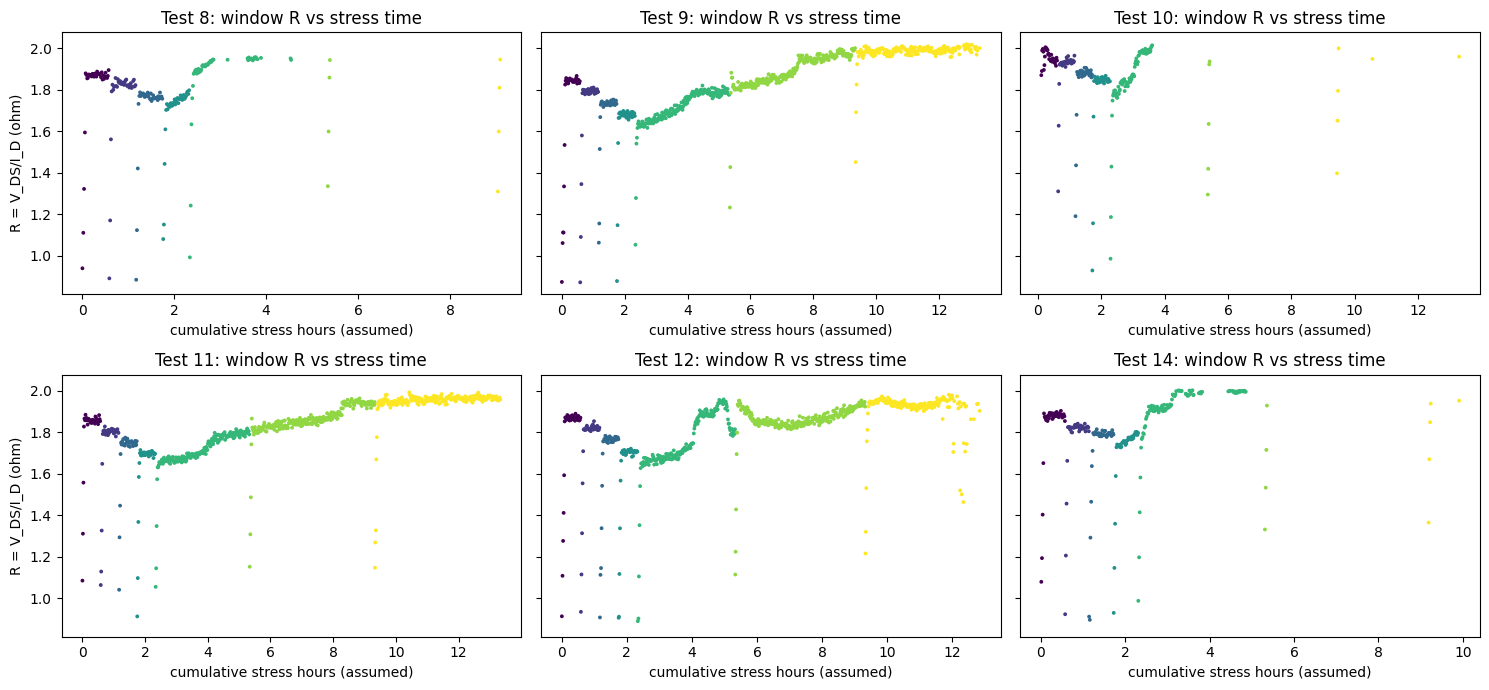

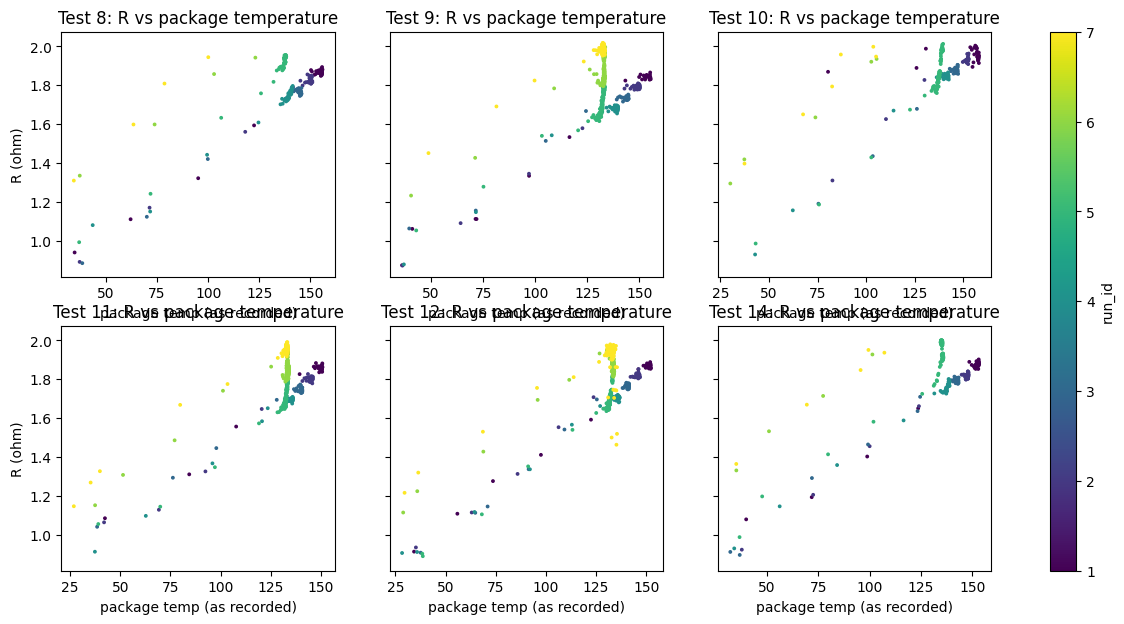

In [73]:
# CELL 70: 1-minute window trajectories and R vs temperature by run
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

I_MIN = 2.5   # provisional conduction threshold (A)
WINDOW_MIN = 1.0

d = rec_df[(rec_df["drainCurrent"] >= I_MIN) & (rec_df["drainSourceVoltage"] > 0)].copy()
d["R"] = d["drainSourceVoltage"] / d["drainCurrent"]
d["win"] = np.floor((d["stress_h"] * 60) / WINDOW_MIN).astype(int)

win_df = (d.groupby(["test_id", "run_id", "win"])
          .agg(stress_h=("stress_h", "mean"), R=("R", "median"), I=("drainCurrent", "median"),
               pkgT=("packageTemperature", "median"), flangeT=("flangeTemperature", "median"),
               n=("R", "size"))
          .reset_index())
win_df = win_df[win_df["n"] >= 5].copy()
win_df.to_pickle("/kaggle/working/window_df.pkl")

print("Windows per test:")
display(win_df.groupby("test_id").size().to_frame("n_windows"))
print("Window pkgT range per test:")
display(win_df.groupby("test_id")["pkgT"].describe()[["min", "50%", "max"]].round(1))

tests = sorted(win_df["test_id"].unique())
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, t in zip(axes.ravel(), tests):
    g = win_df[win_df["test_id"] == t]
    ax.scatter(g["stress_h"], g["R"], s=3, c=g["run_id"], cmap="viridis")
    ax.set_title(f"Test {t}: window R vs stress time"); ax.set_xlabel("cumulative stress hours (assumed)")
axes[0, 0].set_ylabel("R = V_DS/I_D (ohm)"); axes[1, 0].set_ylabel("R = V_DS/I_D (ohm)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, t in zip(axes.ravel(), tests):
    g = win_df[win_df["test_id"] == t]
    sc = ax.scatter(g["pkgT"], g["R"], s=3, c=g["run_id"], cmap="viridis")
    ax.set_title(f"Test {t}: R vs package temperature"); ax.set_xlabel("package temp (as recorded)")
axes[0, 0].set_ylabel("R (ohm)"); axes[1, 0].set_ylabel("R (ohm)")
fig.colorbar(sc, ax=axes, label="run_id")
plt.show()

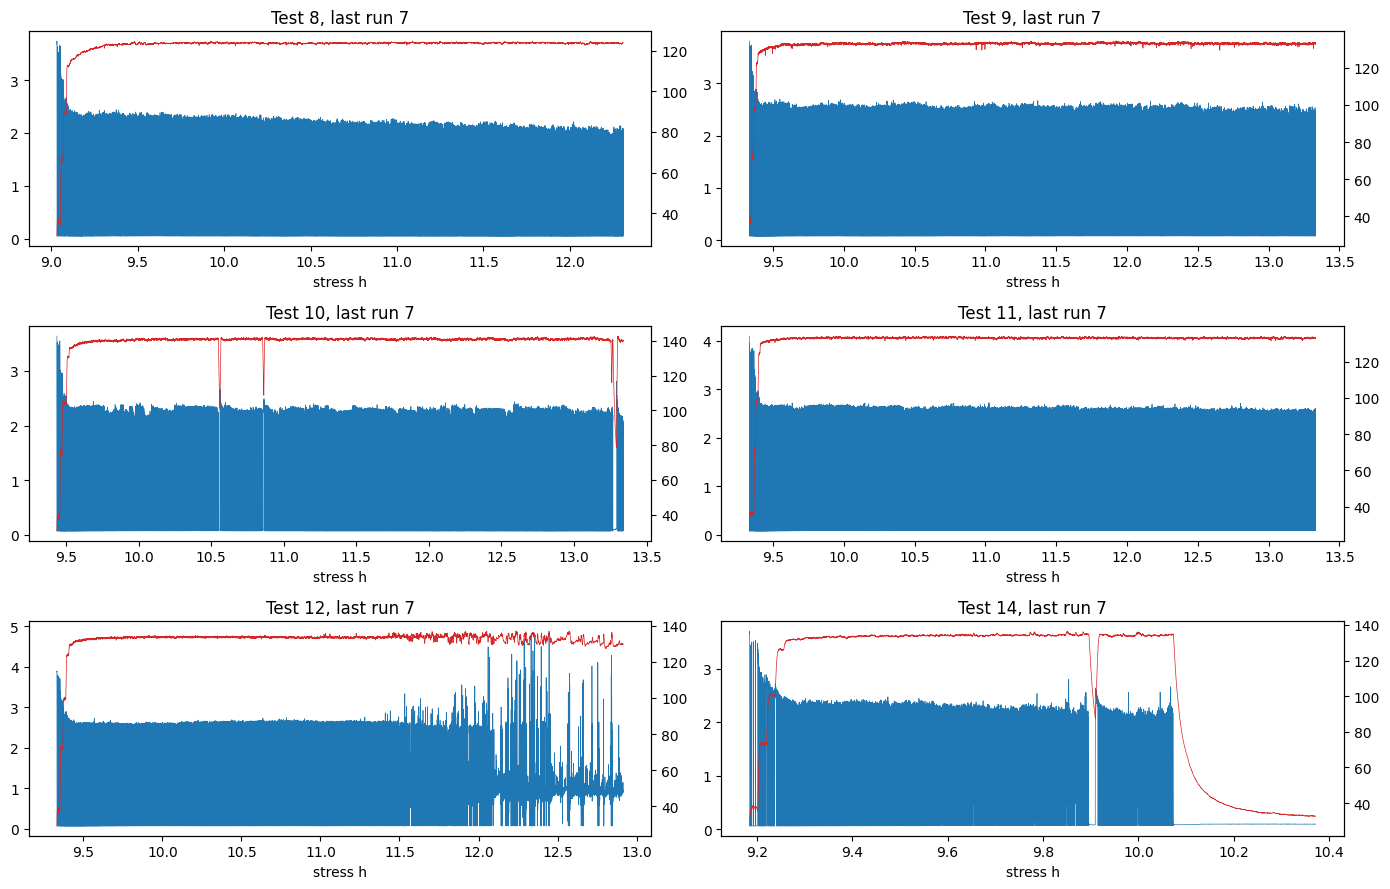

test_id,8,9,10,11,12,14
last_run,7.000,7.000,7.000,7.000,7.000,7.000
n_records,28199.000,35397.000,34667.000,35520.000,31957.000,10591.000
first10pct_I_med,2.171,0.085,2.043,0.084,0.068,0.058
first10pct_Vds_med,5.017,5.579,5.157,5.582,5.580,5.582
first10pct_pkgT_med,119.557,131.584,139.057,132.173,132.195,124.349
first10pct_frac_I_below_1.5A,0.405,0.514,0.491,0.521,0.517,0.532
first10pct_R_med_valid,1.736,1.959,1.744,1.933,1.928,1.824
last10pct_I_med,1.916,2.188,2.002,2.364,0.886,0.092
last10pct_Vds_med,5.036,5.132,5.164,5.039,5.387,5.578
last10pct_pkgT_med,123.845,132.881,140.940,133.124,130.559,33.411


In [74]:
# CELL 71: End-of-test behaviour of the last run in each test
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

rows = []
last_runs = rec_df.groupby("test_id")["run_id"].max()
fig, axes = plt.subplots(3, 2, figsize=(14, 9))

for ax, (t, rid) in zip(axes.ravel(), last_runs.items()):
    g = rec_df[(rec_df["test_id"] == t) & (rec_df["run_id"] == rid)].copy()
    n = len(g); k = max(int(0.1 * n), 50)
    head, tail = g.iloc[:k], g.iloc[-k:]
    def stats(x):
        ok = (x["drainCurrent"] >= 2.5) & (x["drainSourceVoltage"] > 0)
        return pd.Series({
            "I_med": x["drainCurrent"].median(), "Vds_med": x["drainSourceVoltage"].median(),
            "pkgT_med": x["packageTemperature"].median(),
            "frac_I_below_1.5A": (x["drainCurrent"] < 1.5).mean(),
            "R_med_valid": (x.loc[ok, "drainSourceVoltage"] / x.loc[ok, "drainCurrent"]).median()})
    s_head, s_tail = stats(head), stats(tail)
    rows.append({"test_id": t, "last_run": rid, "n_records": n,
                 **{f"first10pct_{c}": v for c, v in s_head.items()},
                 **{f"last10pct_{c}": v for c, v in s_tail.items()}})
    ax.plot(g["stress_h"], g["drainCurrent"], lw=0.5, label="I_D (A)")
    ax2 = ax.twinx()
    ax2.plot(g["stress_h"], g["packageTemperature"], lw=0.5, color="tab:red")
    ax.set_title(f"Test {t}, last run {rid}"); ax.set_xlabel("stress h")
plt.tight_layout(); plt.show()

end_df = pd.DataFrame(rows).set_index("test_id").round(3)
pd.set_option("display.max_columns", None)
display(end_df.T)

/tmp/ipykernel_49/1694399229.py:42: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  stats_df = rec_df.groupby(["test_id", "run_id"]).apply(run_stats).round(3)


on_thr  on_frac  I_on_med  Vds_on_med  I_off_med  Vds_off_med  \
test_id run_id                                                                  
8       1        0.500    0.620     2.605       4.886      0.041        5.580   
        2        0.500    0.589     2.683       4.883      0.041        5.579   
        3        0.500    0.543     2.766       4.874      0.041        5.579   
        4        0.500    0.514     2.797       4.869      0.041        5.579   
        5        0.500    0.556     2.377       4.929      0.042        5.579   
        6        0.500    0.576     2.256       4.965      0.041        5.579   
        7        0.500    0.664     2.104       4.988      0.051        5.582   
9       1        0.500    0.526     2.736       5.018      0.087        5.579   
        2        0.500    0.529     2.804       5.003      0.077        5.580   
        3        0.500    0.499     2.885       4.986      0.077        5.580   
        4        0.500    0.467     2.966       4.967      0.079        5.579   
        5        0.500    0.448     2.875       4.973      0.092        5.578   
        6        0.500    0.479     2.628       5.029      0.088        5.579   
        7        0.500    0.501     2.445       5.068      0.085        5.580   
10      1        1.358    0.513     2.516       5.050      0.086        5.578   
        2        0.500    0.547     2.594       5.032      0.086        5.578   
        3        0.500    0.505     2.677       5.013      0.084        5.578   
        4        0.500    0.486     2.720       5.004      0.083        5.578   
        5        0.500    0.498     2.421       5.068      0.082        5.578   
        6        0.500    0.524     2.307       5.094      0.079        5.579   
        7        0.500    0.538     2.203       5.116      0.076        5.579   
11      1        0.500    0.573     2.705       5.005      0.070        5.581   
        2        0.500    0.533     2.779       4.989      0.070        5.581   
        3        0.500    0.503     2.852       4.971      0.069        5.581   
        4        0.500    0.465     2.932       4.954      0.070        5.580   
        5        0.500    0.477     2.857       4.934      0.094        5.580   
        6        0.500    0.500     2.650       4.975      0.091        5.581   
        7        0.500    0.512     2.521       5.026      0.085        5.583   
12      1        0.500    0.566     2.683       4.991      0.071        5.582   
        2        0.500    0.546     2.740       4.962      0.065        5.583   
        3        0.500    0.509     2.804       4.926      0.065        5.583   
        4        0.500    0.476     2.915       4.938      0.065        5.582   
        5        0.500    0.478     2.804       4.937      0.067        5.582   
        6        0.500    0.497     2.646       4.964      0.068        5.582   
        7        1.436    0.378     2.523       4.990      0.070        5.580   
14      1        0.500    0.590     2.652       4.967      0.073        5.581   
        2        0.500    0.557     2.733       4.960      0.074        5.581   
        3        0.500    0.513     2.773       4.937      0.066        5.582   
        4        0.500    0.486     2.827       4.959      0.065        5.582   
        5        0.500    0.512     2.430       5.032      0.067        5.581   
        6        0.500    0.544     2.299       5.040      0.065        5.582   
        7        1.153    0.406     2.231       5.054      0.063        5.582   

                R_adaptive_med  R_fixed2.5_med  frac_kept_by_fixed2.5  
test_id run_id                                                         
8       1                1.876           1.863                  0.875  
        2                1.819           1.819                  0.999  
        3                1.763           1.763                  1.000  
        4                1.741           1.741                  1.000  
        5          

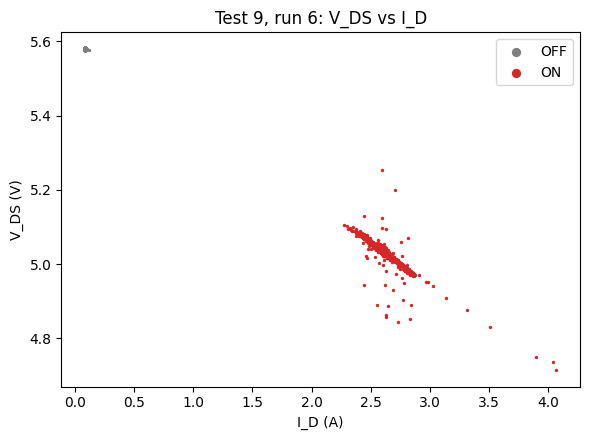

In [75]:
# CELL 72: Adaptive ON/OFF classification (a fixed 2.5 A cut censors degraded, lower-current data)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def otsu_threshold(x, bins=128):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    hist, edges = np.histogram(x, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    w0 = np.cumsum(hist)
    w1 = w0[-1] - w0
    s = hist * centers
    m0 = np.cumsum(s) / np.maximum(w0, 1)
    m1 = (s.sum() - np.cumsum(s)) / np.maximum(w1, 1)
    return centers[np.argmax(w0 * w1 * (m0 - m1) ** 2)]

thr = (rec_df.groupby(["test_id", "run_id"])["drainCurrent"]
       .apply(lambda s: float(np.clip(otsu_threshold(s.values), 0.5, 1.5)))
       .rename("on_thr").reset_index())
rec_df = rec_df.drop(columns=["on_thr", "on"], errors="ignore").merge(thr, on=["test_id", "run_id"], how="left")
rec_df["on"] = rec_df["drainCurrent"] > rec_df["on_thr"]
rec_df.to_pickle("/kaggle/working/stage_records.pkl")

def run_stats(g):
    on = g[g["on"] & (g["drainSourceVoltage"] > 0)]
    fx = g[(g["drainCurrent"] >= 2.5) & (g["drainSourceVoltage"] > 0)]
    off = g[~g["on"]]
    return pd.Series({
        "on_thr": g["on_thr"].iloc[0],
        "on_frac": g["on"].mean(),
        "I_on_med": on["drainCurrent"].median(),
        "Vds_on_med": on["drainSourceVoltage"].median(),
        "I_off_med": off["drainCurrent"].median(),
        "Vds_off_med": off["drainSourceVoltage"].median(),
        "R_adaptive_med": (on["drainSourceVoltage"] / on["drainCurrent"]).median(),
        "R_fixed2.5_med": (fx["drainSourceVoltage"] / fx["drainCurrent"]).median(),
        "frac_kept_by_fixed2.5": len(fx) / max(len(on), 1),
    })

stats_df = rec_df.groupby(["test_id", "run_id"]).apply(run_stats).round(3)
pd.set_option("display.max_rows", 100)
display(stats_df)

g = rec_df[(rec_df["test_id"] == 9) & (rec_df["run_id"] == 6)].iloc[::10]
plt.figure(figsize=(6, 4.5))
plt.scatter(g.loc[~g["on"], "drainCurrent"], g.loc[~g["on"], "drainSourceVoltage"], s=2, c="tab:gray", label="OFF")
plt.scatter(g.loc[g["on"], "drainCurrent"], g.loc[g["on"], "drainSourceVoltage"], s=2, c="tab:red", label="ON")
plt.xlabel("I_D (A)"); plt.ylabel("V_DS (V)"); plt.title("Test 9, run 6: V_DS vs I_D"); plt.legend(markerscale=4)
plt.tight_layout(); plt.show()

ON-state windows per test (adaptive mask):


,n_windows
test_id,
8,739
9,800
10,797
11,801
12,759
14,611


,k_exponent,R2,n,T_min_C,T_max_C
test_id,,,,,
8,2.204,0.994,70,34.656,155.950
9,2.196,0.986,70,36.053,155.511
10,-0.128,0.008,65,60.016,158.123
11,1.973,0.981,70,41.938,150.840
12,2.120,0.992,70,34.290,152.281
14,2.058,0.987,70,37.771,153.184


Pooled (median) exponent k = 2.089 (silicon power-MOSFET R_on is commonly quoted to scale roughly as T^2 to T^2.5)


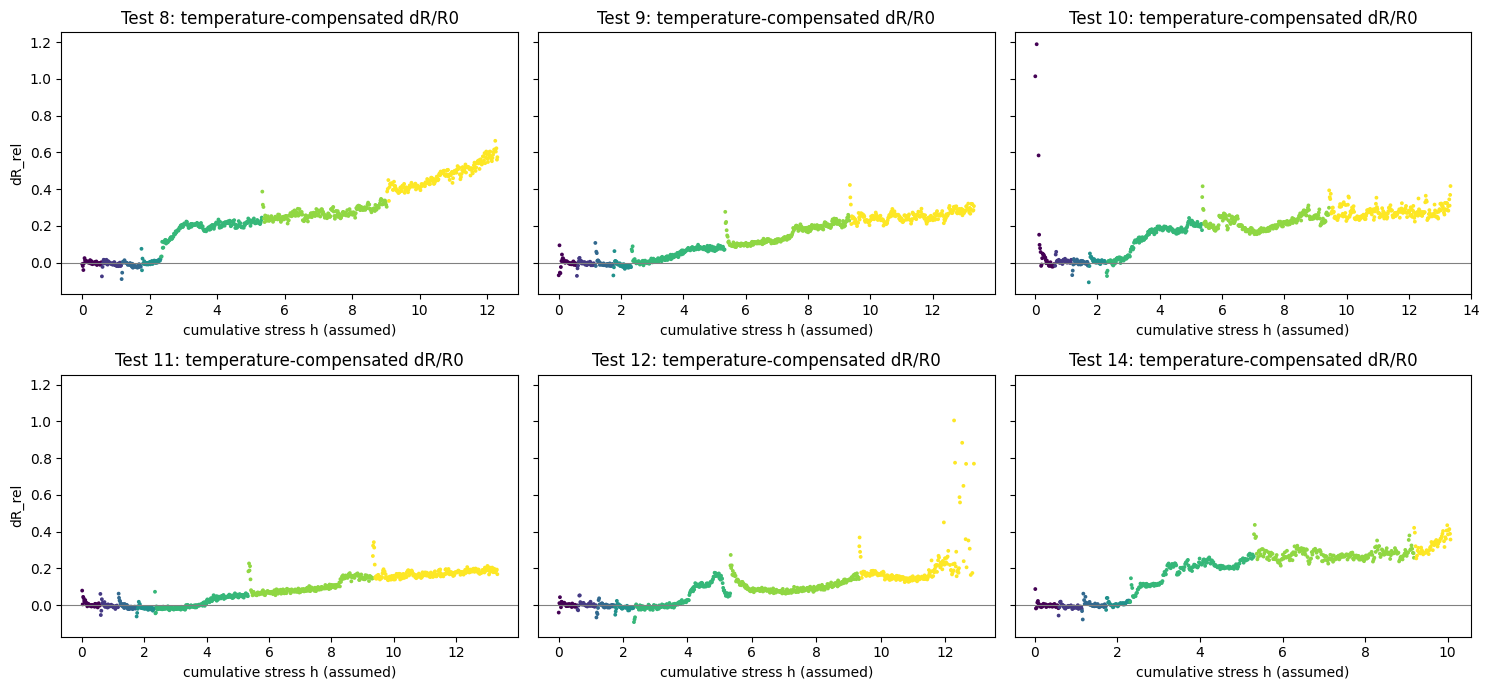

,dR_rel_final,dR_rel_max,t_cross_10pct_h,t_cross_15pct_h,t_cross_20pct_h,t_cross_25pct_h
test_id,,,,,,
8,0.572,0.601,2.525,2.842,3.092,6.192
9,0.287,0.290,5.458,7.608,8.708,9.792
10,0.287,0.308,0.192,3.725,5.008,6.108
11,0.189,0.195,8.042,8.508,NaN,NaN
12,0.226,0.352,4.341,4.925,11.806,12.646
14,0.341,0.385,2.675,3.225,3.325,5.242


In [76]:
# CELL 73: Physics-based temperature compensation of the ON-state resistance proxy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

on = rec_df[rec_df["on"] & (rec_df["drainSourceVoltage"] > 0)].copy()
on["R"] = on["drainSourceVoltage"] / on["drainCurrent"]
on["win"] = np.floor(on["stress_h"] * 60).astype(int)
w = (on.groupby(["test_id", "run_id", "win"])
     .agg(stress_h=("stress_h", "mean"), R=("R", "median"), pkgT=("packageTemperature", "median"),
          I=("drainCurrent", "median"), n=("R", "size")).reset_index())
w = w[(w["n"] >= 5) & (w["pkgT"] > 20) & (w["R"] > 0)].copy()
w["Tk"] = w["pkgT"] + 273.15
w.to_pickle("/kaggle/working/window_on_df.pkl")
print("ON-state windows per test (adaptive mask):")
display(w.groupby("test_id").size().to_frame("n_windows"))

# Fit log R = a + k*log(T_K) on the EARLIEST runs (1-2), i.e. before most aging
fit_rows = []
for t, g in w[w["run_id"] <= 2].groupby("test_id"):
    k, a = np.polyfit(np.log(g["Tk"]), np.log(g["R"]), 1)
    pred = a + k * np.log(g["Tk"])
    r2 = 1 - ((np.log(g["R"]) - pred) ** 2).sum() / ((np.log(g["R"]) - np.log(g["R"]).mean()) ** 2).sum()
    fit_rows.append({"test_id": t, "k_exponent": k, "R2": r2, "n": len(g),
                     "T_min_C": g["pkgT"].min(), "T_max_C": g["pkgT"].max()})
fit_df = pd.DataFrame(fit_rows).set_index("test_id").round(3)
display(fit_df)
k_pool = float(fit_df["k_exponent"].median())
print("Pooled (median) exponent k =", round(k_pool, 3),
      "(silicon power-MOSFET R_on is commonly quoted to scale roughly as T^2 to T^2.5)")

T_REF = 403.15  # 130 C reference
w["R_comp"] = w["R"] * (T_REF / w["Tk"]) ** k_pool
base = (w[(w["run_id"] == 1) & (w["pkgT"] > 120)].groupby("test_id")["R_comp"].median().rename("R0"))
w = w.merge(base.reset_index(), on="test_id", how="left")
w["dR_rel"] = w["R_comp"] / w["R0"] - 1
w.to_pickle("/kaggle/working/window_on_df.pkl")

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, t in zip(axes.ravel(), sorted(w["test_id"].unique())):
    g = w[w["test_id"] == t]
    ax.scatter(g["stress_h"], g["dR_rel"], s=3, c=g["run_id"], cmap="viridis")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(f"Test {t}: temperature-compensated dR/R0"); ax.set_xlabel("cumulative stress h (assumed)")
axes[0, 0].set_ylabel("dR_rel"); axes[1, 0].set_ylabel("dR_rel")
plt.tight_layout(); plt.show()

rows = []
for t, g in w.groupby("test_id"):
    g = g.sort_values("stress_h")
    sm = g.set_index("stress_h")["dR_rel"].rolling(15, min_periods=8).median()
    row = {"test_id": t, "dR_rel_final": sm.iloc[-30:].median(), "dR_rel_max": sm.max()}
    for thr in (0.10, 0.15, 0.20, 0.25):
        hit = sm[sm >= thr]
        row[f"t_cross_{int(thr*100)}pct_h"] = hit.index[0] if len(hit) else np.nan
    rows.append(row)
display(pd.DataFrame(rows).set_index("test_id").round(3))

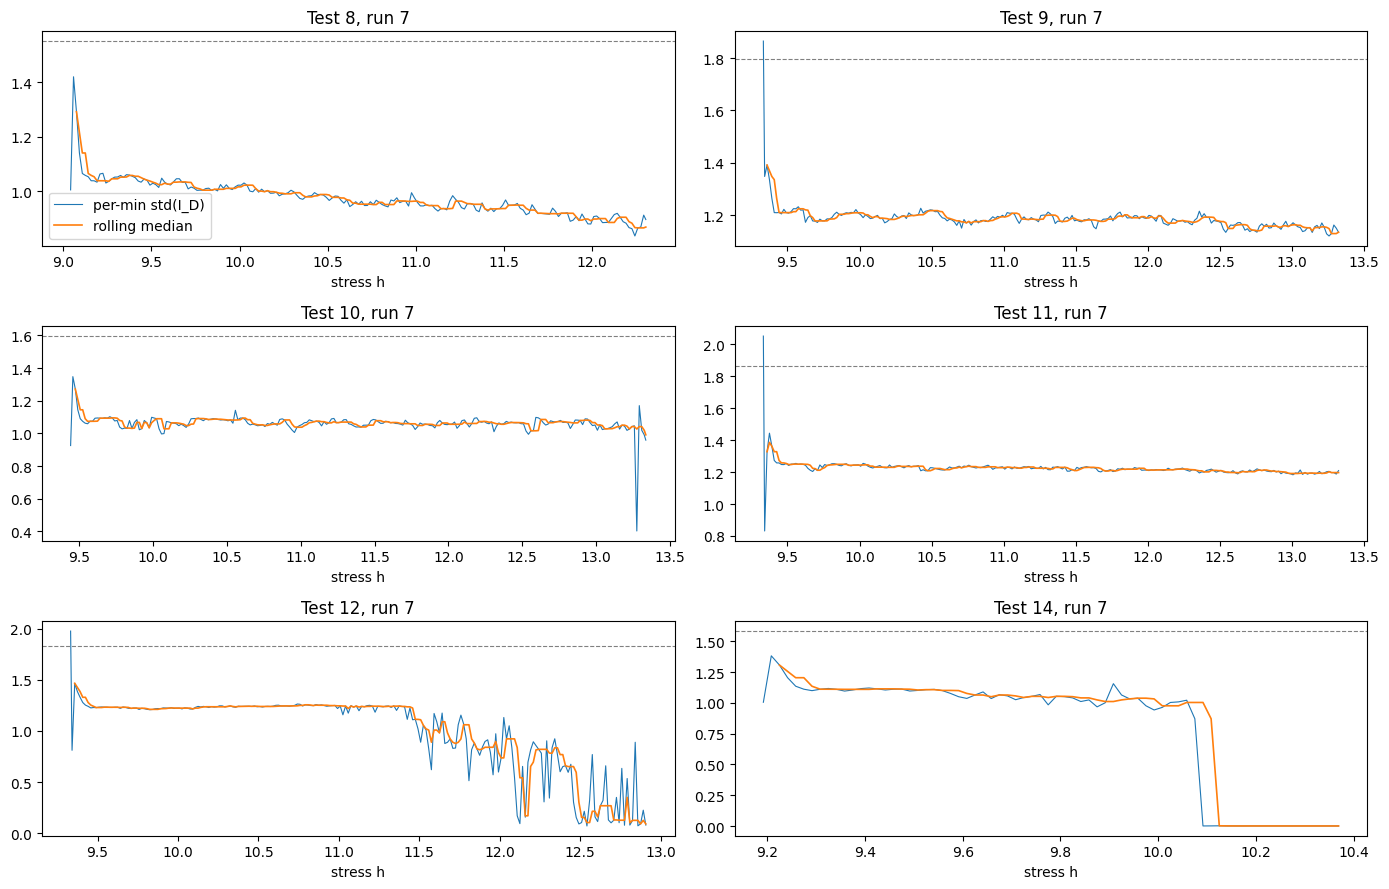

,last_run,last_run_start_h,test_end_h,baseline_I_std,t_instability_onset_h,t_current_collapse_h,final_pkgT
test_id,,,,,,,
8,7,9.042,12.304,1.034,NaN,NaN,123.833
9,7,9.333,13.324,1.198,NaN,NaN,132.933
10,7,9.443,13.336,1.064,NaN,NaN,139.918
11,7,9.333,13.324,1.243,NaN,NaN,133.145
12,7,9.333,12.908,1.222,NaN,NaN,129.754
14,7,9.192,10.369,1.055,NaN,10.125,33.166


In [77]:
# CELL 74: Look for failure-like events (current collapse / instability) in each test's last run
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

rows = []
fig, axes = plt.subplots(3, 2, figsize=(14, 9))
last_runs = rec_df.groupby("test_id")["run_id"].max()

for ax, (t, rid) in zip(axes.ravel(), last_runs.items()):
    g = rec_df[(rec_df["test_id"] == t) & (rec_df["run_id"] == rid)].copy()
    g["win"] = np.floor(g["stress_h"] * 60).astype(int)
    m = (g.groupby("win").agg(stress_h=("stress_h", "mean"), on_frac=("on", "mean"),
                              I_p95=("drainCurrent", lambda s: np.nanpercentile(s, 95)),
                              I_std=("drainCurrent", "std"), pkgT=("packageTemperature", "median"))
         .reset_index())
    t0 = m["stress_h"].min()
    base = m[(m["stress_h"] > t0 + 0.25) & (m["stress_h"] < t0 + 0.75)]
    base_std = base["I_std"].median()
    m["I_std_roll"] = m["I_std"].rolling(5, min_periods=3).median()
    collapse = (m["I_p95"] < 1.0).astype(int).rolling(3).sum() == 3
    unstable = (m["I_std_roll"] > 1.5 * base_std) & (m["stress_h"] > t0 + 0.75)
    t_collapse = m.loc[collapse, "stress_h"].min() if collapse.any() else np.nan
    t_unstable = m.loc[unstable, "stress_h"].min() if unstable.any() else np.nan
    rows.append({"test_id": t, "last_run": rid, "last_run_start_h": t0, "test_end_h": m["stress_h"].max(),
                 "baseline_I_std": base_std, "t_instability_onset_h": t_unstable, "t_current_collapse_h": t_collapse,
                 "final_pkgT": m["pkgT"].iloc[-5:].median()})
    ax.plot(m["stress_h"], m["I_std"], lw=0.8, label="per-min std(I_D)")
    ax.plot(m["stress_h"], m["I_std_roll"], lw=1.2, label="rolling median")
    ax.axhline(1.5 * base_std, color="gray", ls="--", lw=0.8)
    ax.set_title(f"Test {t}, run {rid}"); ax.set_xlabel("stress h")
axes[0, 0].legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("test_id").round(3))

Transient group fields: ('date', 'nanosec_time', 'timeEpoch', 'timeDomain')
Done test 8 run 1: 3216 waveforms
Done test 8 run 5: 14800 waveforms
Done test 8 run 7: 18712 waveforms
Done test 9 run 1: 2728 waveforms
Done test 9 run 5: 11911 waveforms
Done test 9 run 7: 17726 waveforms
Done test 10 run 1: 2729 waveforms
Done test 10 run 5: 13658 waveforms
Done test 10 run 7: 19074 waveforms
Done test 11 run 1: 2970 waveforms
Done test 11 run 5: 12717 waveforms
Done test 11 run 7: 18194 waveforms
Done test 12 run 1: 2944 waveforms
Done test 12 run 5: 12749 waveforms
Done test 12 run 7: 19078 waveforms
Done test 14 run 1: 3006 waveforms
Done test 14 run 5: 13600 waveforms
Done test 14 run 7: 7071 waveforms


n   V_on   I_on  R_on_transient  V_cycle_mean  I_cycle_mean  \
test_id run_id                                                                  
8       1       120  3.916  6.501           0.602         5.000         2.744   
        5       120  4.019  5.981           0.670         5.047         2.536   
        7       120  4.097  5.448           0.750         5.067         2.336   
9       1       120  4.272  6.858           0.623         5.153         2.943   
        5       120  4.170  7.268           0.572         5.117         3.109   
        7       120  4.401  6.136           0.716         5.205         2.646   
10      1       120  4.331  0.311          13.495         5.163         0.317   
        5       120  4.375  0.311          14.053         5.186         0.305   
        7       120  4.502  0.311          14.335         5.240         0.311   
11      1       120  4.243  6.661           0.637         5.141         2.825   
        5       120  4.019  7.203           0.559         5.055         3.082   
        7       120  4.258  6.280           0.678         5.130         2.694   
12      1       120  4.150  6.678           0.622         5.076         2.855   
        5       120  3.973  7.186           0.551         5.006         3.053   
        7       120  4.202  6.239           0.672         5.110         2.677   
14      1       120  4.126  6.546           0.631         5.088         2.778   
        5       120  4.297  6.005           0.715         5.152         2.576   
        7       120  4.369  5.292           0.824         5.164         2.285   

                V_off  Vds_on_med  I_on_med  R_adaptive_med  
test_id run_id                                               
8       1       5.728       4.886     2.605           1.876  
        5       5.741       4.929     2.377           2.073  
        7       5.713       4.988     2.104           2.369  
9       1       5.752       5.018     2.736           1.834  
        5       5.757       4.973     2.875           1.730  
        7       5.742       5.068     2.445           2.073  
10      1       5.728       5.050     2.516           2.008  
        5       5.732       5.068     2.421           2.093  
        7       5.737       5.116     2.203           2.322  
11      1       5.747       5.005     2.705           1.851  
        5       5.747       4.934     2.857           1.727  
        7       5.723       5.026     2.521           1.994  
12      1       5.703       4.991     2.683           1.860  
        5       5.708       4.937     2.804           1.760  
        7       5.718       4.990     2.523           1.978  
14      1       5.737       4.967     2.652           1.873  
        5       5.728       5.032     2.430           2.070  
        7       5.688       5.054     2.231           2.265

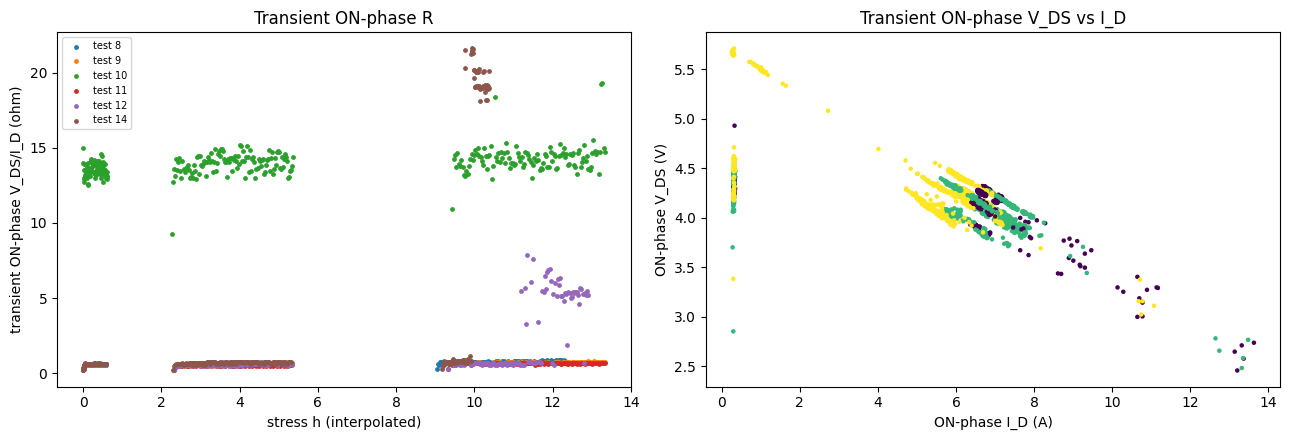

In [78]:
# CELL 75: Transient ON-phase resistance (paper-like) vs steady-state proxy, same runs
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import display

CACHE = "/kaggle/working/transient_on_phase.pkl"
TESTS = [8, 9, 10, 11, 12, 14]
RUNS = [1, 5, 7]
N_PER_RUN = 120

def unwrap_rec(x):
    rec = np.asarray(x).squeeze()
    while isinstance(rec, np.ndarray) and rec.dtype.names is None and rec.size == 1:
        rec = rec.item()
    return rec

if os.path.exists(CACHE):
    tr_df = pd.read_pickle(CACHE)
    print("Loaded cache:", CACHE)
else:
    rows = []
    run_span = rec_df.groupby(["test_id", "run_id"])["stress_h"].agg(["min", "max"])
    for t in TESTS:
        for r in RUNS:
            m = valid_inventory[(valid_inventory["test_id"] == t) & (valid_inventory["run_id"] == r)]
            if m.empty:
                continue
            mat = loadmat(str(m.iloc[0]["path"]))
            tr = mat["measurement"]["transient"][0, 0]
            if t == TESTS[0] and r == RUNS[0]:
                print("Transient group fields:", tr.dtype.names)
            td = tr["timeDomain"]
            n = td.size
            idx = np.unique(np.linspace(0, n - 1, N_PER_RUN).astype(int))
            s0, s1 = run_span.loc[(t, r)]
            for i in idx:
                try:
                    rec = unwrap_rec(td.flat[i])
                    g = waveform_array(rec["gateSignalVoltage"])
                    v = waveform_array(rec["drainSourceVoltage"])
                    c = waveform_array(rec["drainCurrent"])
                    k = min(len(g), len(v), len(c))
                    g, v, c = g[:k], v[:k], c[:k]
                    on = g > 0.5 * g.max()
                    # skip the first 15% of the ON window to avoid the turn-on edge
                    on_idx = np.where(on)[0]
                    if len(on_idx) < 20:
                        continue
                    cut = on_idx[0] + int(0.15 * len(on_idx))
                    sel = on & (np.arange(k) >= cut) & (c > 0.3 * np.nanmax(c))
                    if sel.sum() < 10:
                        continue
                    rows.append({"test_id": t, "run_id": r, "rec_idx": int(i),
                                 "stress_h": s0 + (s1 - s0) * i / max(n - 1, 1),
                                 "V_on": float(np.median(v[sel])), "I_on": float(np.median(c[sel])),
                                 "R_on_transient": float(np.median(v[sel] / c[sel])),
                                 "V_cycle_mean": float(np.mean(v)), "I_cycle_mean": float(np.mean(c)),
                                 "V_off": float(np.median(v[~on])) if (~on).sum() else np.nan})
                except Exception as e:
                    continue
            print(f"Done test {t} run {r}: {n} waveforms")
    tr_df = pd.DataFrame(rows)
    tr_df.to_pickle(CACHE)

summ = tr_df.groupby(["test_id", "run_id"]).agg(
    n=("R_on_transient", "size"), V_on=("V_on", "median"), I_on=("I_on", "median"),
    R_on_transient=("R_on_transient", "median"), V_cycle_mean=("V_cycle_mean", "median"),
    I_cycle_mean=("I_cycle_mean", "median"), V_off=("V_off", "median")).round(3)
cmp = summ.join(stats_df[["Vds_on_med", "I_on_med", "R_adaptive_med"]], how="left")
display(cmp)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for t, g in tr_df.groupby("test_id"):
    ax[0].scatter(g["stress_h"], g["R_on_transient"], s=6, label=f"test {t}")
ax[0].set(xlabel="stress h (interpolated)", ylabel="transient ON-phase V_DS/I_D (ohm)", title="Transient ON-phase R")
ax[0].legend(fontsize=7)
ax[1].scatter(tr_df["I_on"], tr_df["V_on"], s=5, c=tr_df["run_id"])
ax[1].set(xlabel="ON-phase I_D (A)", ylabel="ON-phase V_DS (V)", title="Transient ON-phase V_DS vs I_D")
plt.tight_layout(); plt.show()

In [79]:
# CELL 76: How robust is the compensated indicator? (exponent, temperature sensor, run-boundary jumps)
import numpy as np
import pandas as pd
from IPython.display import display

on = rec_df[rec_df["on"] & (rec_df["drainSourceVoltage"] > 0)].copy()
on["R"] = on["drainSourceVoltage"] / on["drainCurrent"]
on["win"] = np.floor(on["stress_h"] * 60).astype(int)
W = (on.groupby(["test_id", "run_id", "win"])
     .agg(stress_h=("stress_h", "mean"), R=("R", "median"), pkgT=("packageTemperature", "median"),
          flgT=("flangeTemperature", "median"), n=("R", "size")).reset_index())
W = W[(W["n"] >= 5) & (W["R"] > 0)].copy()

def hi(W, k, tcol):
    d = W[W[tcol] > 20].copy()
    Tk = d[tcol] + 273.15
    d["R_comp"] = d["R"] * (403.15 / Tk) ** k
    base = d[(d["run_id"] == 1) & (d[tcol] > 120)].groupby("test_id")["R_comp"].median().rename("R0")
    d = d.merge(base.reset_index(), on="test_id", how="left")
    d["dR"] = d["R_comp"] / d["R0"] - 1
    return d

rows = []
for tcol in ["pkgT", "flgT"]:
    for k in (1.9, 2.1, 2.3, 2.5):
        d = hi(W, k, tcol)
        fin = d.sort_values("stress_h").groupby("test_id")["dR"].apply(lambda s: s.iloc[-60:].median())
        r = {"temp_sensor": tcol, "k": k}
        r.update({f"test{t}": round(v, 3) for t, v in fin.items()})
        rows.append(r)
print("Final compensated dR/R0 (median of last 60 windows) under different assumptions:")
display(pd.DataFrame(rows))

d = hi(W, 2.1, "pkgT")
jump_rows = []
for t, g in d.groupby("test_id"):
    for r in sorted(g["run_id"].unique())[:-1]:
        a = g[(g["run_id"] == r) & (g["pkgT"] > 120)].sort_values("stress_h")["dR"].tail(15)
        b = g[(g["run_id"] == r + 1) & (g["pkgT"] > 120)].sort_values("stress_h")["dR"].head(15)
        if len(a) >= 5 and len(b) >= 5:
            jump_rows.append({"test_id": t, "boundary": f"{r}->{r+1}", "dR_end_of_run": a.median(),
                              "dR_start_of_next": b.median(), "jump": b.median() - a.median()})
jd = pd.DataFrame(jump_rows).round(3)
print("\nJumps in compensated indicator across run boundaries (reversible-looking component):")
display(jd)
print("\nMedian absolute jump by boundary:")
display(jd.assign(abs_jump=jd["jump"].abs()).groupby("boundary")["abs_jump"].median().round(3).to_frame())

Final compensated dR/R0 (median of last 60 windows) under different assumptions:


,temp_sensor,k,test8,test9,test10,test11,test12,test14
0,pkgT,1.9,0.526,0.271,0.267,0.179,0.210,0.308
1,pkgT,2.1,0.549,0.284,0.277,0.189,0.221,0.321
2,pkgT,2.3,0.571,0.298,0.287,0.199,0.232,0.335
3,pkgT,2.5,0.594,0.311,0.297,0.209,0.243,0.347
4,flgT,1.9,0.586,0.341,0.362,0.268,0.297,0.400
5,flgT,2.1,0.616,0.362,0.384,0.289,0.317,0.422
6,flgT,2.3,0.647,0.384,0.406,0.310,0.338,0.449
7,flgT,2.5,0.678,0.406,0.428,0.331,0.358,0.472



Jumps in compensated indicator across run boundaries (reversible-looking component):


,test_id,boundary,dR_end_of_run,dR_start_of_next,jump
0,8,1->2,-0.004,-0.002,0.002
1,8,2->3,-0.012,-0.001,0.010
2,8,3->4,-0.021,-0.004,0.017
3,8,4->5,0.007,0.115,0.108
4,8,5->6,0.223,0.239,0.016
5,8,6->7,0.323,0.396,0.072
6,9,1->2,-0.006,0.003,0.009
7,9,2->3,-0.006,-0.003,0.002
8,9,3->4,-0.012,-0.007,0.006
9,9,4->5,-0.021,0.005,0.026



Median absolute jump by boundary:


,abs_jump
boundary,
1->2,0.005
2->3,0.006
3->4,0.006
4->5,0.014
5->6,0.019
6->7,0.008


Event = sustained loss of switching-current swing (std(I_D) < 0.6 x baseline). NaN = no event (censored at end_h).


,event_h,end_h,baseline_I_std,dR_0.0h_before,dR_0.5h_before,dR_1.0h_before,dR_2.0h_before
test_id,,,,,,,
8,NaN,12.304,1.034,0.594,0.537,0.500,0.428
9,NaN,13.324,1.198,0.290,0.286,0.261,0.245
10,NaN,13.336,1.064,0.306,0.257,0.268,0.262
11,NaN,13.324,1.243,0.188,0.185,0.180,0.170
12,12.108,12.908,1.222,0.233,0.160,0.141,0.168
14,10.108,10.369,1.055,0.387,0.292,0.283,0.259


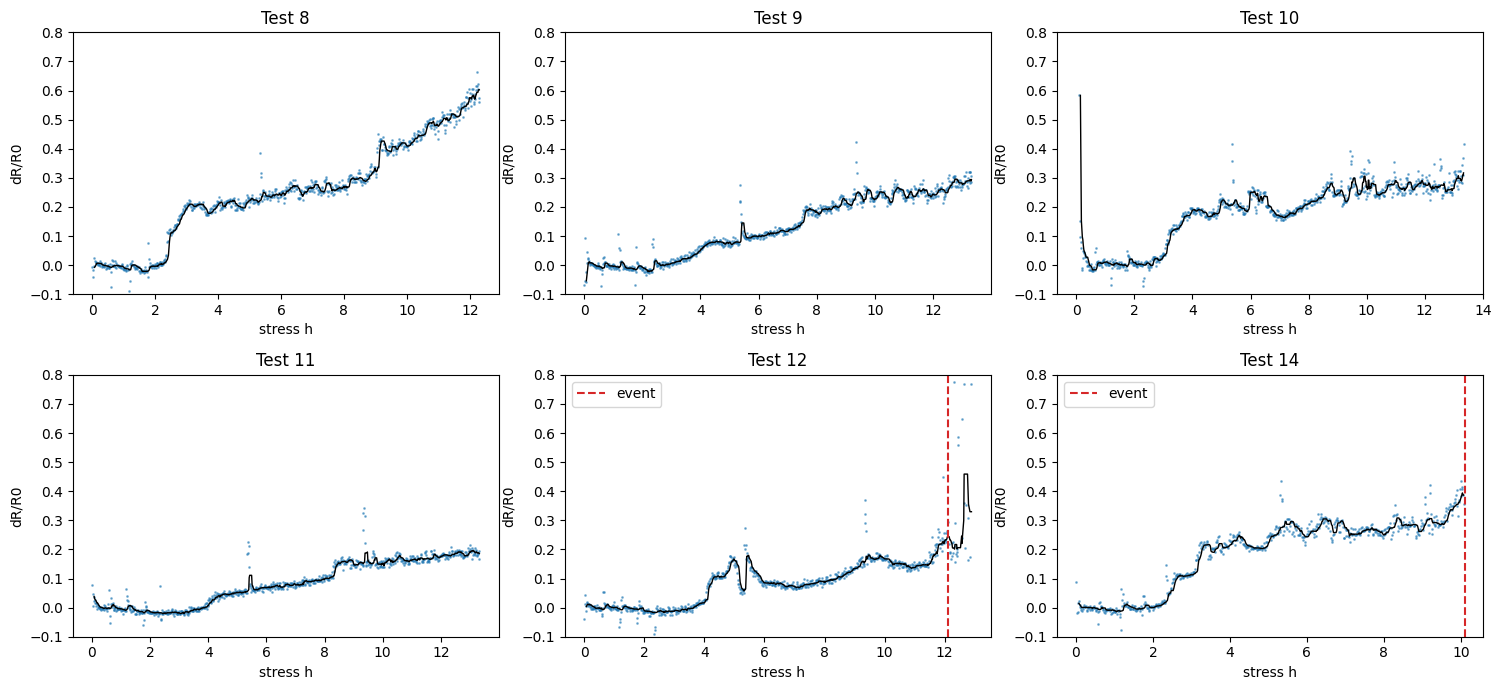

In [80]:
# CELL 77: Failure-event timing and precursor behaviour of the indicator
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    HIw = w.copy()
except NameError:
    HIw = pd.read_pickle("/kaggle/working/window_on_df.pkl")

ev_rows = []
for t, rid in rec_df.groupby("test_id")["run_id"].max().items():
    g = rec_df[(rec_df["test_id"] == t) & (rec_df["run_id"] == rid)].copy()
    g["win"] = np.floor(g["stress_h"] * 60).astype(int)
    m = g.groupby("win").agg(stress_h=("stress_h", "mean"), I_std=("drainCurrent", "std"),
                             I_p95=("drainCurrent", lambda s: np.nanpercentile(s, 95))).reset_index()
    t0 = m["stress_h"].min()
    base = m[(m["stress_h"] > t0 + 0.25) & (m["stress_h"] < t0 + 0.75)]["I_std"].median()
    m["std_roll"] = m["I_std"].rolling(5, min_periods=3).median()
    low = (m["std_roll"] < 0.6 * base) & (m["stress_h"] > t0 + 0.75)
    sustained = low.astype(int).rolling(5).sum() == 5
    t_ev = m.loc[sustained, "stress_h"].iloc[0] - 5 / 60 if sustained.any() else np.nan
    h = HIw[HIw["test_id"] == t].sort_values("stress_h")
    row = {"test_id": t, "event_h": t_ev, "end_h": m["stress_h"].max(), "baseline_I_std": base}
    ref = t_ev if np.isfinite(t_ev) else m["stress_h"].max()
    for lag in (0.0, 0.5, 1.0, 2.0):
        s = h[(h["stress_h"] > ref - lag - 0.25) & (h["stress_h"] <= ref - lag)]["dR_rel"]
        row[f"dR_{lag}h_before"] = s.median() if len(s) >= 5 else np.nan
    ev_rows.append(row)
ev = pd.DataFrame(ev_rows).set_index("test_id").round(3)
print("Event = sustained loss of switching-current swing (std(I_D) < 0.6 x baseline). NaN = no event (censored at end_h).")
display(ev)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (t, r) in zip(axes.ravel(), ev.iterrows()):
    h = HIw[HIw["test_id"] == t].sort_values("stress_h")
    sm = h.set_index("stress_h")["dR_rel"].rolling(10, min_periods=5).median()
    ax.plot(h["stress_h"], h["dR_rel"], ".", ms=2, color="tab:blue", alpha=0.5)
    ax.plot(sm.index, sm.values, color="k", lw=1)
    ax.set_ylim(-0.1, 0.8)
    if np.isfinite(r["event_h"]):
        ax.axvline(r["event_h"], color="tab:red", ls="--", label="event")
        ax.legend()
    ax.set_title(f"Test {t}"); ax.set_xlabel("stress h"); ax.set_ylabel("dR/R0")
plt.tight_layout(); plt.show()

In [81]:
# CELL 78: Scan ALL runs for failure-like endings (loss of switching current)
import os
import numpy as np
import pandas as pd
from IPython.display import display

CACHE = "/kaggle/working/run_scan.pkl"

def trailing_true(a):
    n = 0
    for x in a[::-1]:
        if x: n += 1
        else: break
    return n

def longest_true(a):
    best = cur = 0
    for x in a:
        cur = cur + 1 if x else 0
        best = max(best, cur)
    return best

if os.path.exists(CACHE):
    scan_df = pd.read_pickle(CACHE)
    print("Loaded cache:", CACHE)
else:
    rows = []
    for _, r in valid_inventory.dropna(subset=["test_id", "run_id"]).sort_values(["test_id", "run_id"]).iterrows():
        try:
            d = load_run_records(r["path"]).dropna(subset=["epoch"]).sort_values("epoch")
            d["m"] = np.floor((d["epoch"] - d["epoch"].min()) * 1440).astype(int)
            m = (d.groupby("m").agg(I_p95=("drainCurrent", lambda s: np.nanpercentile(s, 95)),
                                    I_std=("drainCurrent", "std"),
                                    pkgT=("packageTemperature", "median")).reset_index())
            off = (m["I_p95"] < 1.0).values
            mid = m.iloc[len(m) // 4: 3 * len(m) // 4]
            base = mid["I_std"].median()
            tail = m["I_std"].iloc[-10:].median()
            rows.append({"test_id": int(r["test_id"]), "run_id": int(r["run_id"]), "minutes": len(m),
                         "off_minute_frac": off.mean(), "trailing_off_min": trailing_true(off),
                         "longest_off_min_after10": longest_true(off[10:]),
                         "tail_over_base_std": tail / base if base and np.isfinite(base) else np.nan,
                         "pkgT_start": m["pkgT"].iloc[:5].median(), "pkgT_end": m["pkgT"].iloc[-5:].median()})
        except Exception as e:
            print("Skipped", r["filename"], "->", type(e).__name__, e)
    scan_df = pd.DataFrame(rows)
    scan_df.to_pickle(CACHE)

pd.set_option("display.max_rows", 200)
last = scan_df.sort_values(["test_id", "run_id"]).groupby("test_id").tail(1).copy()
last["failure_like"] = (last["trailing_off_min"] >= 10) | (last["tail_over_base_std"] < 0.6)
cols = ["test_id", "run_id", "minutes", "off_minute_frac", "trailing_off_min", "longest_off_min_after10",
        "tail_over_base_std", "pkgT_start", "pkgT_end", "failure_like"]
print("Last run of each test:")
display(last[cols].round(3).reset_index(drop=True))
print("\nTests whose last run looks failure-like:", int(last["failure_like"].sum()), "of", len(last))
print("Failure-like tests:", sorted(last.loc[last["failure_like"], "test_id"].tolist()))

Last run of each test:


,test_id,run_id,minutes,off_minute_frac,trailing_off_min,longest_off_min_after10,tail_over_base_std,pkgT_start,pkgT_end,failure_like
0,1,2,16,0.000,0,0,0.792,99.889,198.204,False
1,2,3,24,0.375,0,0,0.677,41.245,204.425,False
2,3,1,33,0.000,0,0,0.506,103.117,191.518,True
3,4,2,5,0.400,2,0,0.842,38.858,38.858,False
4,5,2,2,1.000,2,0,1.020,30.938,30.938,False
5,6,2,137,0.912,125,125,1.110,80.852,30.179,True
6,7,1,150,0.333,50,50,0.001,98.059,30.084,True
7,8,7,197,0.000,0,0,0.904,89.511,123.833,False
8,9,7,240,0.000,0,0,0.970,98.333,132.935,False
9,10,7,235,0.004,0,1,0.966,103.936,140.051,False



Tests whose last run looks failure-like: 19 of 42
Failure-like tests: [3, 6, 7, 12, 14, 20, 21, 24, 26, 28, 29, 32, 35, 36, 37, 38, 39, 40, 42]


I_on_est  R_on_est_Voff_steady  R_on_est_Voff_transient  \
test_id run_id                                                            
8       1          6.512                 0.591                    0.556   
        5          5.943                 0.665                    0.624   
        7          5.261                 0.779                    0.742   
9       1          6.840                 0.611                    0.573   
        5          7.188                 0.566                    0.528   
        7          6.112                 0.704                    0.664   
11      1          6.762                 0.613                    0.576   
        5          7.142                 0.555                    0.520   
        7          6.302                 0.665                    0.632   
12      1          6.707                 0.612                    0.585   
        5          7.009                 0.566                    0.540   
        7          6.309                 0.651                    0.618   
14      1          6.629                 0.610                    0.575   
        5          6.076                 0.693                    0.657   
        7          5.577                 0.764                    0.736   

                I_on_tr  V_on_tr  R_on_tr  V_off_tr  ratio_est_steady_over_tr  \
test_id run_id                                                                  
8       1         6.501    3.916    0.602     5.728                     0.981   
        5         5.981    4.019    0.670     5.741                     0.992   
        7         5.448    4.097    0.750     5.713                     1.039   
9       1         6.858    4.272    0.623     5.752                     0.980   
        5         7.268    4.170    0.572     5.757                     0.988   
        7         6.136    4.401    0.716     5.742                     0.983   
11      1         6.661    4.243    0.637     5.747                     0.962   
        5         7.203    4.019    0.559     5.747                     0.994   
        7         6.280    4.258    0.678     5.723                     0.981   
12      1         6.678    4.150    0.622     5.703                     0.984   
        5         7.186    3.973    0.551     5.708                     1.028   
        7         6.239    4.202    0.672     5.718                     0.969   
14      1         6.546    4.126    0.631     5.737                     0.967   
        5         6.005    4.297    0.715     5.728                     0.968   
        7         5.292    4.369    0.824     5.688                     0.927   

                ratio_est_trans_over_tr  
test_id run_id                           
8       1                         0.925  
        5                         0.931  
        7                         0.989  
9       1                         0.919  
        5                         0.923  
        7                         0.927  
11      1                         0.904  
        5                         0.931  
        7                         0.932  
12      1                         0.941  
        5                         0.979  
        7                         0.920  
14      1                         0.911  
        5                         0.918  
        7                         0.893

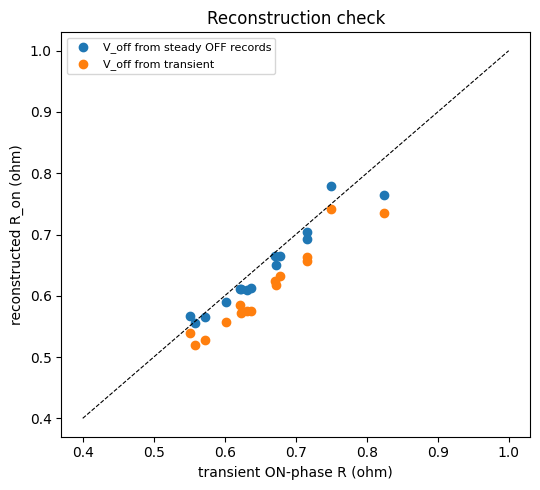

Duty cycle assumed: 0.4 (controller setting: 40%)


In [82]:
# CELL 79: Reconstruct ON-phase quantities from cycle-averaged steady-state values
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DUTY = 0.40
trs = tr_df[tr_df["test_id"] != 10].groupby(["test_id", "run_id"]).agg(
    I_on_tr=("I_on", "median"), V_on_tr=("V_on", "median"), R_on_tr=("R_on_transient", "median"),
    V_off_tr=("V_off", "median"))

rows = []
for (t, r), g in rec_df[rec_df["on"] & (rec_df["drainSourceVoltage"] > 0)].groupby(["test_id", "run_id"]):
    if (t, r) not in trs.index:
        continue
    v_avg, i_avg = g["drainSourceVoltage"].median(), g["drainCurrent"].median()
    v_off_ss = rec_df[(rec_df["test_id"] == t) & (rec_df["run_id"] == r) & (~rec_df["on"])]["drainSourceVoltage"].median()
    i_on = i_avg / DUTY
    row = {"test_id": t, "run_id": r, "I_on_est": i_on}
    for name, voff in (("Voff_steady", v_off_ss), ("Voff_transient", trs.loc[(t, r), "V_off_tr"])):
        v_on = (v_avg - (1 - DUTY) * voff) / DUTY
        row[f"R_on_est_{name}"] = v_on / i_on
    rows.append(row)
est = pd.DataFrame(rows).set_index(["test_id", "run_id"]).join(trs)
est["ratio_est_steady_over_tr"] = est["R_on_est_Voff_steady"] / est["R_on_tr"]
est["ratio_est_trans_over_tr"] = est["R_on_est_Voff_transient"] / est["R_on_tr"]
display(est.round(3))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(est["R_on_tr"], est["R_on_est_Voff_steady"], label="V_off from steady OFF records")
ax.scatter(est["R_on_tr"], est["R_on_est_Voff_transient"], label="V_off from transient")
lim = [0.4, 1.0]
ax.plot(lim, lim, "k--", lw=0.8)
ax.set(xlabel="transient ON-phase R (ohm)", ylabel="reconstructed R_on (ohm)", title="Reconstruction check")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("Duty cycle assumed:", DUTY, "(controller setting: 40%)")

Done test 12 run 6
Done test 12 run 7
Done test 14 run 6
Done test 14 run 7
Done test 8 run 6
Done test 8 run 7
Done test 9 run 6
Done test 9 run 7


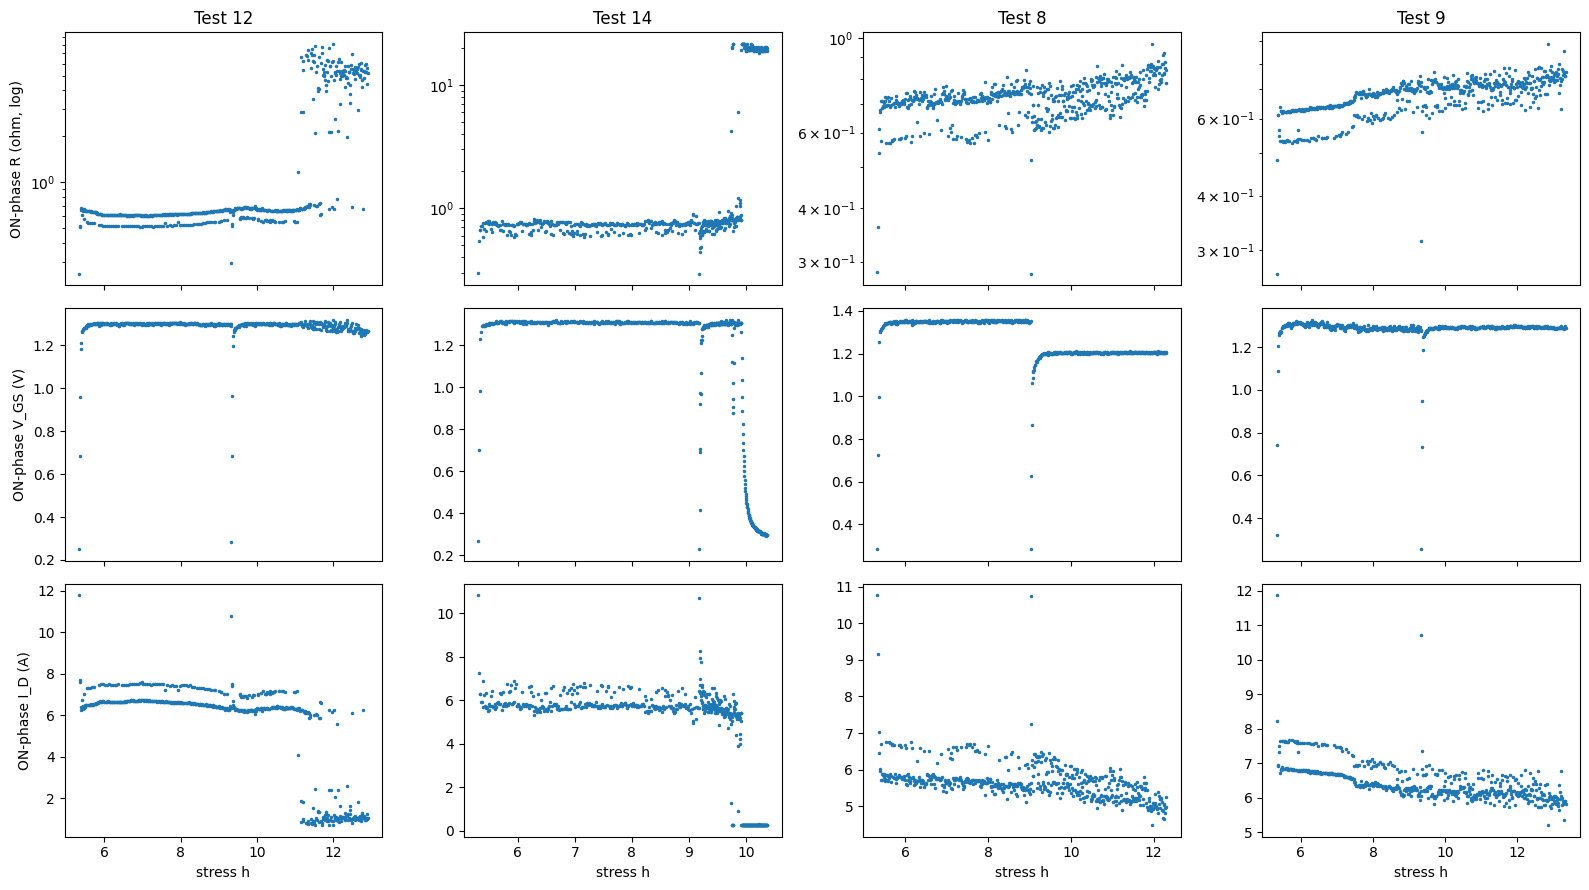

Vgs_on   I_on   V_on   R_on  gate_signal_max
test_id run_id                                              
8       6        1.351  5.710  4.087  0.715           18.838
        7        1.204  5.480  4.087  0.745           18.843
9       6        1.294  6.710  4.282  0.638           14.922
        7        1.292  6.153  4.404  0.715           18.799
12      6        1.300  6.645  4.072  0.611           18.965
        7        1.297  6.202  4.214  0.677           18.975
14      6        1.311  5.759  4.277  0.740           18.936
        7        1.292  5.349  4.358  0.813           18.916

In [83]:
# CELL 80: Transient ON-phase R_on and V_GS across runs 6-7 for failed / accelerating / stable devices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import display

TESTS = [12, 14, 8, 9]
RUNS = [6, 7]
N_PER_RUN = 300

def unwrap_rec(x):
    rec = np.asarray(x).squeeze()
    while isinstance(rec, np.ndarray) and rec.dtype.names is None and rec.size == 1:
        rec = rec.item()
    return rec

run_span = rec_df.groupby(["test_id", "run_id"])["stress_h"].agg(["min", "max"])
rows = []
for t in TESTS:
    for r in RUNS:
        m = valid_inventory[(valid_inventory["test_id"] == t) & (valid_inventory["run_id"] == r)]
        if m.empty:
            continue
        td = loadmat(str(m.iloc[0]["path"]))["measurement"]["transient"][0, 0]["timeDomain"]
        n = td.size
        s0, s1 = run_span.loc[(t, r)]
        for i in np.unique(np.linspace(0, n - 1, N_PER_RUN).astype(int)):
            try:
                rec = unwrap_rec(td.flat[i])
                g = waveform_array(rec["gateSignalVoltage"]); vgs = waveform_array(rec["gateSourceVoltage"])
                v = waveform_array(rec["drainSourceVoltage"]); c = waveform_array(rec["drainCurrent"])
                k = min(len(g), len(vgs), len(v), len(c))
                g, vgs, v, c = g[:k], vgs[:k], v[:k], c[:k]
                on = g > 0.5 * g.max()
                oi = np.where(on)[0]
                if len(oi) < 20:
                    continue
                cut = oi[0] + int(0.15 * len(oi))
                sel = on & (np.arange(k) >= cut)
                sel_c = sel & (c > 0.3 * np.nanmax(c))
                rows.append({"test_id": t, "run_id": r, "stress_h": s0 + (s1 - s0) * i / max(n - 1, 1),
                             "Vgs_on": float(np.median(vgs[sel])), "I_on": float(np.median(c[sel])),
                             "V_on": float(np.median(v[sel])),
                             "R_on": float(np.median(v[sel_c] / c[sel_c])) if sel_c.sum() >= 5 else np.nan,
                             "gate_signal_max": float(g.max())})
            except Exception:
                continue
        print(f"Done test {t} run {r}")

tw = pd.DataFrame(rows)
tw.to_pickle("/kaggle/working/transient_late_runs.pkl")
fig, axes = plt.subplots(3, len(TESTS), figsize=(16, 9), sharex="col")
for j, t in enumerate(TESTS):
    g = tw[tw["test_id"] == t]
    axes[0, j].semilogy(g["stress_h"], g["R_on"], ".", ms=3); axes[0, j].set_title(f"Test {t}")
    axes[1, j].plot(g["stress_h"], g["Vgs_on"], ".", ms=3)
    axes[2, j].plot(g["stress_h"], g["I_on"], ".", ms=3); axes[2, j].set_xlabel("stress h")
axes[0, 0].set_ylabel("ON-phase R (ohm, log)"); axes[1, 0].set_ylabel("ON-phase V_GS (V)"); axes[2, 0].set_ylabel("ON-phase I_D (A)")
plt.tight_layout(); plt.show()
display(tw.groupby(["test_id", "run_id"])[["Vgs_on", "I_on", "V_on", "R_on", "gate_signal_max"]].median().round(3))

In [84]:
# CELL 81: For each failure-like last run, was the gate drive still present when conduction was lost?
import numpy as np
import pandas as pd
from scipy.io import loadmat
from IPython.display import display

flagged = sorted(last.loc[last["failure_like"], "test_id"].tolist())
N = 40

def unwrap_rec(x):
    rec = np.asarray(x).squeeze()
    while isinstance(rec, np.ndarray) and rec.dtype.names is None and rec.size == 1:
        rec = rec.item()
    return rec

def wf_features(rec):
    g = waveform_array(rec["gateSignalVoltage"]); vgs = waveform_array(rec["gateSourceVoltage"])
    v = waveform_array(rec["drainSourceVoltage"]); c = waveform_array(rec["drainCurrent"])
    k = min(len(g), len(vgs), len(v), len(c))
    g, vgs, v, c = g[:k], vgs[:k], v[:k], c[:k]
    out = {"gate_max": float(np.nanmax(g)), "Vgs_on": np.nan, "I_on": np.nan, "R_on": np.nan}
    if out["gate_max"] < 3.0:        # gate drive effectively absent
        return out
    on = g > 0.5 * g.max()
    oi = np.where(on)[0]
    if len(oi) < 20:
        return out
    cut = oi[0] + int(0.15 * len(oi))
    sel = on & (np.arange(k) >= cut)
    out["Vgs_on"] = float(np.median(vgs[sel])); out["I_on"] = float(np.median(c[sel]))
    sc = sel & (c > 0.3 * np.nanmax(c))
    if sc.sum() >= 5:
        out["R_on"] = float(np.median(v[sc] / c[sc]))
    return out

wf_rows = []
for t in flagged:
    rid = int(last.loc[last["test_id"] == t, "run_id"].iloc[0])
    m = valid_inventory[(valid_inventory["test_id"] == t) & (valid_inventory["run_id"] == rid)]
    if m.empty:
        continue
    try:
        td = loadmat(str(m.iloc[0]["path"]))["measurement"]["transient"][0, 0]["timeDomain"]
    except Exception as e:
        print("Skipped test", t, type(e).__name__, e); continue
    n = td.size
    for seg, (a, b) in {"mid": (0.4, 0.6), "end": (0.9, 1.0)}.items():
        idx = np.unique(np.linspace(int(a * (n - 1)), int(b * (n - 1)), N).astype(int))
        for i in idx:
            try:
                f = wf_features(unwrap_rec(td.flat[i])); f.update({"test_id": t, "run_id": rid, "seg": seg, "n_wf": n})
                wf_rows.append(f)
            except Exception:
                continue
    print(f"Done test {t} run {rid} ({n} waveforms)")

wf = pd.DataFrame(wf_rows)
wf.to_pickle("/kaggle/working/failure_like_gate_check.pkl")
s = wf.groupby(["test_id", "run_id", "seg"])[["gate_max", "Vgs_on", "I_on", "R_on"]].median().unstack("seg")
s.columns = [f"{a}_{b}" for a, b in s.columns]
s = s.reset_index().merge(last[["test_id", "pkgT_end"]], on="test_id", how="left")
drive = s["gate_max_end"] > 0.5 * s["gate_max_mid"]
lost = (s["I_on_end"] < 0.3 * s["I_on_mid"]) | (s["R_on_end"] > 3 * s["R_on_mid"])
s["verdict"] = np.where(~drive, "drive removed / controlled stop",
                np.where(lost, "FAILURE TO CONDUCT (drive present)", "drive present, conduction OK"))
pd.set_option("display.width", 200)
display(s.round(3))
print(s["verdict"].value_counts())

Done test 3 run 1 (4419 waveforms)
Done test 6 run 2 (20085 waveforms)
Done test 7 run 1 (19844 waveforms)
Done test 12 run 7 (19078 waveforms)
Done test 14 run 7 (7071 waveforms)
Done test 20 run 2 (20092 waveforms)
Done test 21 run 1 (4108 waveforms)
Done test 24 run 2 (19085 waveforms)
Done test 26 run 1 (39223 waveforms)
Done test 28 run 2 (4565 waveforms)
Done test 29 run 1 (39106 waveforms)
Done test 32 run 1 (39316 waveforms)
Done test 35 run 1 (39129 waveforms)
Done test 36 run 1 (38529 waveforms)
Done test 37 run 1 (37674 waveforms)
Done test 38 run 1 (39358 waveforms)
Done test 39 run 1 (4857 waveforms)
Done test 40 run 2 (4260 waveforms)
Done test 42 run 1 (9702 waveforms)


,test_id,run_id,gate_max_end,gate_max_mid,Vgs_on_end,Vgs_on_mid,I_on_end,I_on_mid,R_on_end,R_on_mid,pkgT_end,verdict
0,3,1,16.528,16.299,1.867,1.580,3.291,3.717,1.519,1.289,191.518,"drive present, conduction OK"
1,6,2,18.784,18.779,0.274,0.276,0.199,0.199,28.587,28.575,30.179,"drive present, conduction OK"
2,7,1,18.770,17.104,0.275,1.738,0.182,4.480,31.292,0.990,30.084,FAILURE TO CONDUCT (drive present)
3,12,7,19.653,18.955,1.268,1.299,1.052,6.317,5.175,0.658,129.745,FAILURE TO CONDUCT (drive present)
4,14,7,18.770,18.936,0.301,1.305,0.297,5.316,19.114,0.819,33.154,FAILURE TO CONDUCT (drive present)
5,20,2,19.126,19.131,0.203,0.203,5.431,6.087,0.838,0.722,123.414,"drive present, conduction OK"
6,21,1,18.950,19.009,0.037,0.236,0.330,5.054,17.014,0.913,39.608,FAILURE TO CONDUCT (drive present)
7,24,2,19.043,19.102,0.199,0.201,5.866,6.563,0.755,0.652,116.600,"drive present, conduction OK"
8,26,1,18.975,18.945,0.024,0.027,0.215,0.232,26.074,24.249,31.565,"drive present, conduction OK"
9,28,2,9.375,19.121,0.028,0.207,5.710,7.260,0.184,0.570,34.565,drive removed / controlled stop


verdict
drive present, conduction OK          13
FAILURE TO CONDUCT (drive present)     5
drive removed / controlled stop        1
Name: count, dtype: int64


,k,R2,T_min
test_id,,,
8,2.951,0.992,34.656
9,2.894,0.984,36.053
10,-0.111,0.004,60.016
11,2.575,0.982,41.938
12,2.844,0.988,34.290
14,2.725,0.984,37.771


Exponent for R_on(T) from good fits: 2.844 using tests [8, 9, 11, 12, 14]
R0 (ohm, at 130 C, run 1):


,R0
test_id,
8,0.501
9,0.521
10,0.553
11,0.535
12,0.530
14,0.527


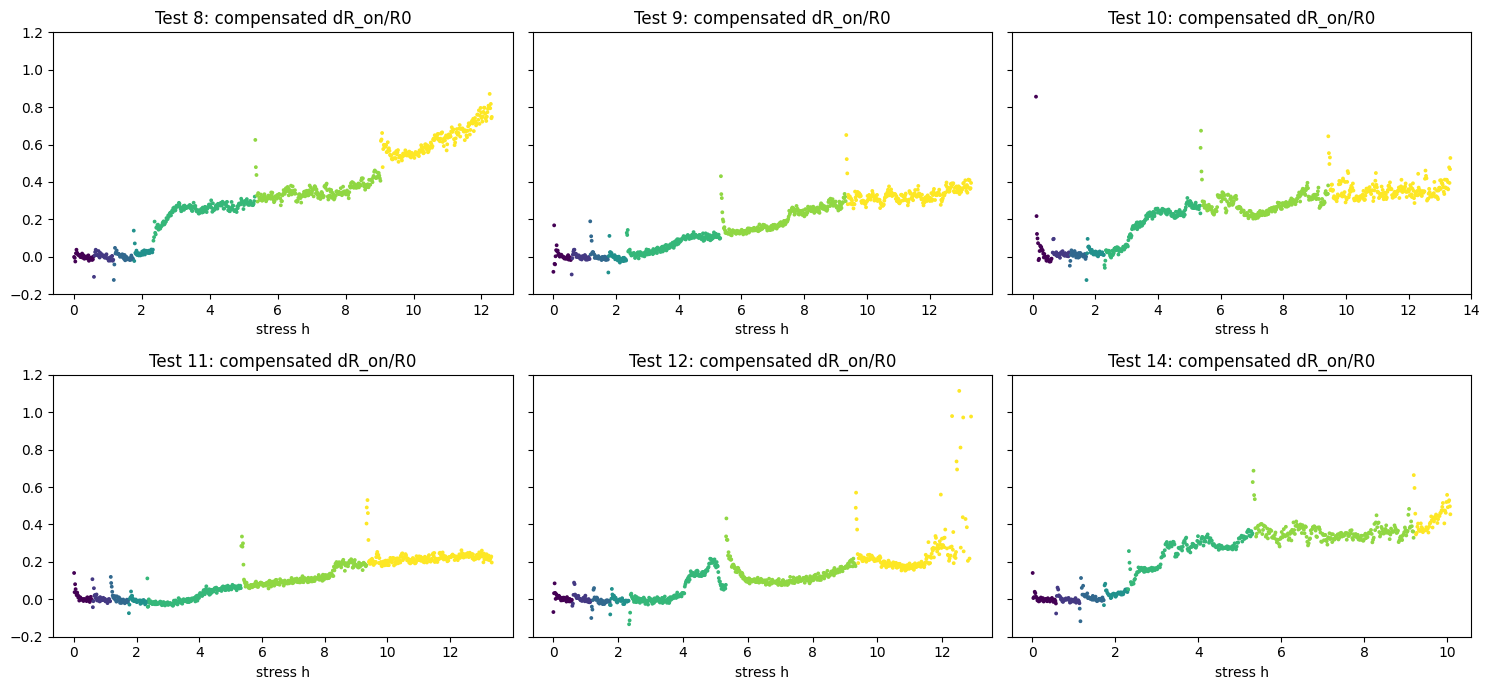

,dRon_0.0h_before,dRon_0.5h_before,dRon_1.0h_before,dRon_2.0h_before,old_proxy_final
test_id,,,,,
8,0.783,0.705,0.657,0.560,0.548
9,0.379,0.368,0.337,0.317,0.283
10,0.390,0.328,0.343,0.334,0.276
11,0.222,0.230,0.228,0.216,0.188
12,0.291,0.197,0.169,0.211,0.220
14,0.493,0.377,0.358,0.331,0.320


In [85]:
# CELL 82: Dense paper-like ON-phase resistance R_on(t) reconstructed from steady-state averages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DUTY = 0.40
voff = (rec_df[~rec_df["on"]].groupby(["test_id", "run_id"])["drainSourceVoltage"].median().rename("V_off").reset_index())
on = rec_df[rec_df["on"] & (rec_df["drainSourceVoltage"] > 0)].merge(voff, on=["test_id", "run_id"], how="left")
on["win"] = np.floor(on["stress_h"] * 60).astype(int)
w2 = (on.groupby(["test_id", "run_id", "win"])
      .agg(stress_h=("stress_h", "mean"), v_avg=("drainSourceVoltage", "median"), i_avg=("drainCurrent", "median"),
           V_off=("V_off", "first"), pkgT=("packageTemperature", "median"), n=("drainCurrent", "size")).reset_index())
w2["R_on"] = (w2["v_avg"] - (1 - DUTY) * w2["V_off"]) / w2["i_avg"]   # = V_on / I_on
w2 = w2[(w2["n"] >= 5) & (w2["R_on"] > 0) & (w2["pkgT"] > 20)].copy()
w2["Tk"] = w2["pkgT"] + 273.15

fit = []
for t, g in w2[w2["run_id"] <= 2].groupby("test_id"):
    k, a = np.polyfit(np.log(g["Tk"]), np.log(g["R_on"]), 1)
    pred = a + k * np.log(g["Tk"])
    r2 = 1 - ((np.log(g["R_on"]) - pred) ** 2).sum() / ((np.log(g["R_on"]) - np.log(g["R_on"]).mean()) ** 2).sum()
    fit.append({"test_id": t, "k": k, "R2": r2, "T_min": g["pkgT"].min()})
fit = pd.DataFrame(fit).set_index("test_id").round(3)
display(fit)
good = fit[fit["R2"] > 0.9]
k_pool = float(good["k"].median())
print("Exponent for R_on(T) from good fits:", round(k_pool, 3), "using tests", good.index.tolist())

w2["R_comp"] = w2["R_on"] * (403.15 / w2["Tk"]) ** k_pool
base = w2[(w2["run_id"] == 1) & (w2["pkgT"] > 120)].groupby("test_id")["R_comp"].median().rename("R0")
w2 = w2.merge(base.reset_index(), on="test_id", how="left")
w2["dRon_rel"] = w2["R_comp"] / w2["R0"] - 1
w2.to_pickle("/kaggle/working/window_Ron_df.pkl")
print("R0 (ohm, at 130 C, run 1):"); display(base.round(3).to_frame())

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, t in zip(axes.ravel(), sorted(w2["test_id"].unique())):
    g = w2[w2["test_id"] == t].sort_values("stress_h")
    ax.scatter(g["stress_h"], g["dRon_rel"], s=3, c=g["run_id"], cmap="viridis")
    ax.set_title(f"Test {t}: compensated dR_on/R0"); ax.set_xlabel("stress h"); ax.set_ylim(-0.2, 1.2)
plt.tight_layout(); plt.show()

ev_times = {12: 12.108, 14: 10.108}
rows = []
for t, g in w2.groupby("test_id"):
    g = g.sort_values("stress_h")
    ref = ev_times.get(t, g["stress_h"].max())
    r = {"test_id": t}
    for lag in (0.0, 0.5, 1.0, 2.0):
        s = g[(g["stress_h"] > ref - lag - 0.25) & (g["stress_h"] <= ref - lag)]["dRon_rel"]
        r[f"dRon_{lag}h_before"] = s.median() if len(s) >= 5 else np.nan
    try:
        old = w[w["test_id"] == t].sort_values("stress_h")["dR_rel"].iloc[-60:].median()
        r["old_proxy_final"] = old
    except Exception:
        pass
    rows.append(r)
display(pd.DataFrame(rows).set_index("test_id").round(3))

In [86]:
# CELL 83: Why are there two interleaved bands in the transient ON-phase R_on and I_on?
import numpy as np
import pandas as pd
from IPython.display import display

tw = pd.read_pickle("/kaggle/working/transient_late_runs.pkl")

def two_means(x, iters=30):
    x = np.asarray(x, dtype=float)
    c0, c1 = np.nanmin(x), np.nanmax(x)
    for _ in range(iters):
        lab = np.abs(x - c1) < np.abs(x - c0)
        if lab.all() or (~lab).all():
            break
        c0, c1 = x[~lab].mean(), x[lab].mean()
    return lab

rows = []
for (t, r), g in tw.dropna(subset=["R_on"]).groupby(["test_id", "run_id"]):
    g = g.sort_values("stress_h")
    g = g[(g["R_on"] < 3) & (g["I_on"] > 1)]
    if len(g) < 30:
        continue
    lab = two_means(g["R_on"].values)
    switches = np.mean(lab[1:] != lab[:-1])
    p = lab.mean()
    rows.append({"test_id": t, "run_id": r, "n": len(g), "share_high_band": p,
                 "R_low": g.loc[~lab, "R_on"].median(), "R_high": g.loc[lab, "R_on"].median(),
                 "I_low_band": g.loc[~lab, "I_on"].median(), "I_high_band": g.loc[lab, "I_on"].median(),
                 "Vgs_low_band": g.loc[~lab, "Vgs_on"].median(), "Vgs_high_band": g.loc[lab, "Vgs_on"].median(),
                 "label_switch_rate": switches, "switch_rate_if_random": 2 * p * (1 - p)})
display(pd.DataFrame(rows).round(3))
print("If label_switch_rate is close to switch_rate_if_random, the bands are interleaved record-by-record "
      "(e.g. alternating trigger conditions); if much lower, they come in long blocks.")

,test_id,run_id,n,share_high_band,R_low,R_high,I_low_band,I_high_band,Vgs_low_band,Vgs_high_band,label_switch_rate,switch_rate_if_random
0,8,6,300,0.990,0.362,0.715,9.154,5.710,0.724,1.352,0.010,0.020
1,8,7,300,0.533,0.688,0.792,5.792,5.201,1.204,1.204,0.391,0.498
2,9,6,300,0.993,0.373,0.638,10.040,6.702,0.532,1.294,0.003,0.013
3,9,7,300,0.993,0.436,0.715,9.040,6.145,0.493,1.292,0.003,0.013
4,12,6,300,0.997,0.251,0.611,11.779,6.645,0.249,1.300,0.003,0.007
5,12,7,187,0.048,0.656,2.177,6.333,2.380,1.299,1.301,0.086,0.092
6,14,6,300,0.753,0.632,0.747,6.464,5.726,1.312,1.310,0.388,0.372
7,14,7,179,0.754,0.660,0.785,6.235,5.497,1.297,1.304,0.264,0.371


If label_switch_rate is close to switch_rate_if_random, the bands are interleaved record-by-record (e.g. alternating trigger conditions); if much lower, they come in long blocks.


Loaded test 6 run 1: 8713 records
Loaded test 6 run 2: 20510 records
Loaded test 7 run 1: 22302 records
Loaded test 12 run 1: 5198 records
Loaded test 12 run 2: 5196 records
Loaded test 12 run 3: 5197 records
Loaded test 12 run 4: 5196 records
Loaded test 12 run 5: 26659 records
Loaded test 12 run 6: 35487 records
Loaded test 12 run 7: 31957 records
Loaded test 14 run 1: 5091 records
Loaded test 14 run 2: 5044 records
Loaded test 14 run 3: 5184 records
Loaded test 14 run 4: 5183 records
Loaded test 14 run 5: 26584 records
Loaded test 14 run 6: 34306 records
Loaded test 14 run 7: 10591 records
Loaded test 21 run 1: 5010 records
Loaded test 26 run 1: 46574 records
Loaded test 29 run 1: 48269 records
Loaded test 32 run 1: 45236 records
Loaded test 35 run 1: 46933 records
Loaded test 36 run 1: 53560 records
Loaded test 38 run 1: 43915 records
Saved cache: /kaggle/working/fail_rec.pkl


,n_runs,total_h,t_fail_h,post_fail_h,pkgT_plateau,shutdownTemp,supplyV,gateV,duty
test_id,,,,,,,,,
6,2,3.254,1.192,2.083,153.133,300.0,5.0,10.0,40.0
7,1,2.487,1.675,0.833,174.446,300.0,5.0,10.0,40.0
12,7,12.908,NaN,0.000,133.568,280.0,5.0,10.0,40.0
14,7,10.369,10.092,0.300,134.766,280.0,5.0,10.0,40.0
21,1,0.554,0.392,0.183,135.749,260.0,5.0,10.0,40.0
26,1,5.188,2.625,2.583,127.265,240.0,5.0,10.0,40.0
29,1,5.384,2.592,2.817,126.529,230.0,5.0,10.0,40.0
32,1,5.037,1.925,3.133,123.648,240.0,5.0,10.0,40.0
35,1,5.237,3.925,1.333,92.075,260.0,5.0,10.0,40.0


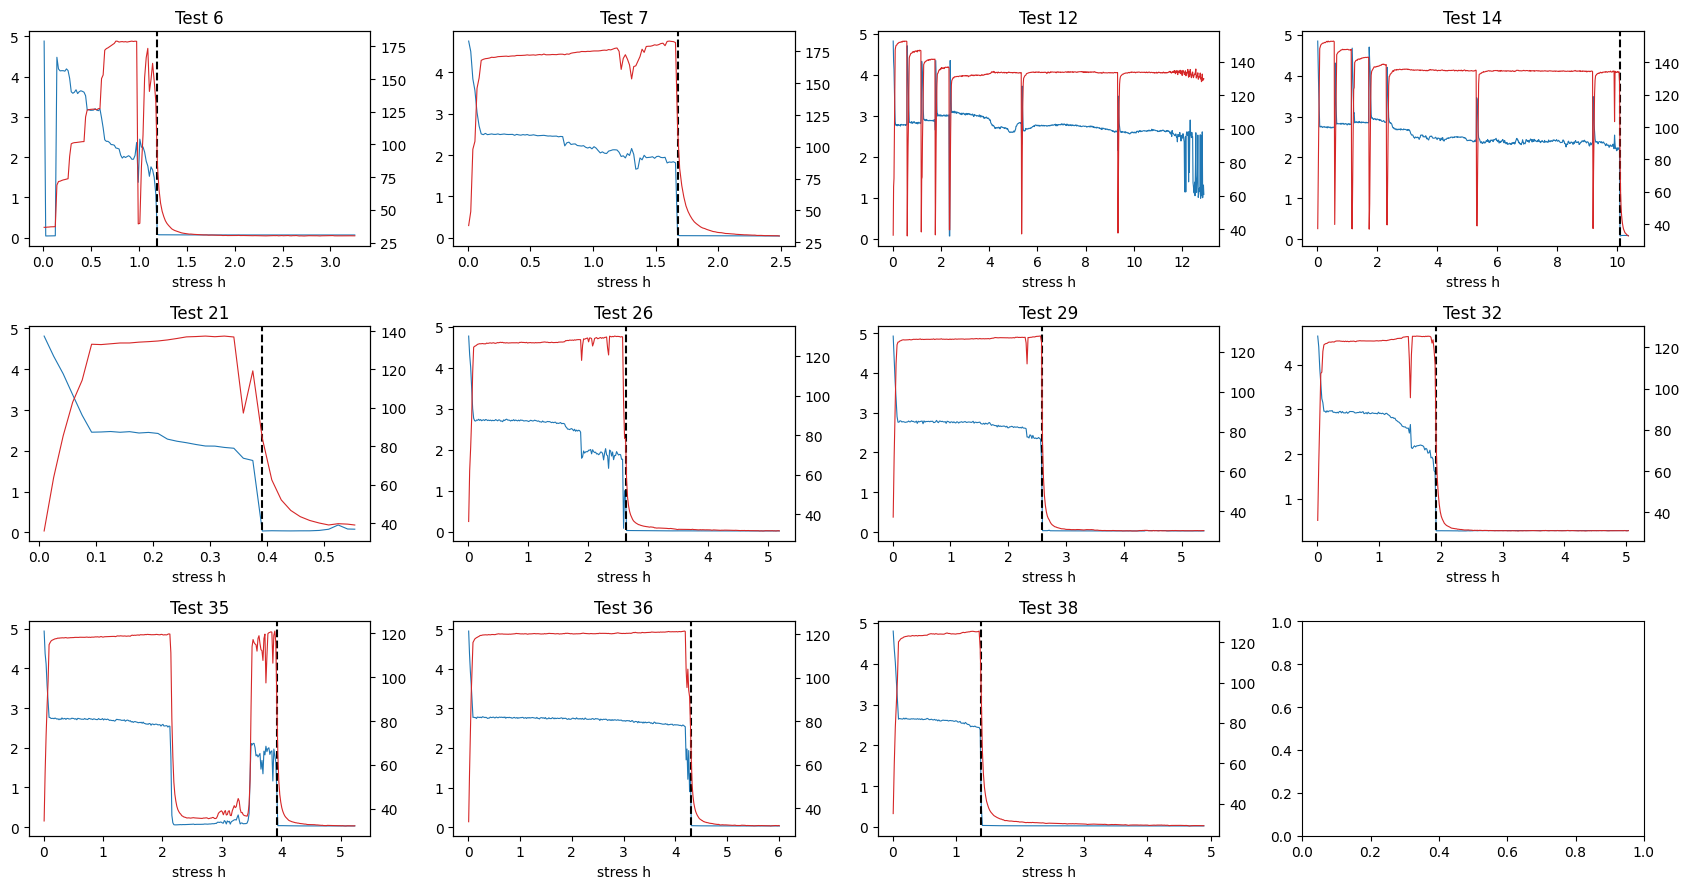

In [87]:
# CELL 84: Failure times for the candidate run-to-failure devices
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FAIL_TESTS = [6, 7, 12, 14, 21, 26, 29, 32, 35, 36, 38]
CACHE = "/kaggle/working/fail_rec.pkl"

if os.path.exists(CACHE):
    fr = pd.read_pickle(CACHE)
    print("Loaded cache:", CACHE)
else:
    parts = []
    sel = valid_inventory[valid_inventory["test_id"].isin(FAIL_TESTS)].sort_values(["test_id", "run_id"])
    for _, r in sel.iterrows():
        try:
            d = load_run_records(r["path"])
            d["test_id"] = int(r["test_id"]); d["run_id"] = int(r["run_id"])
            parts.append(d)
            print(f"Loaded test {int(r['test_id'])} run {int(r['run_id'])}: {len(d)} records")
        except Exception as e:
            print("Skipped", r["filename"], "->", type(e).__name__, e)
    fr = pd.concat(parts, ignore_index=True).sort_values(["test_id", "run_id", "epoch"]).reset_index(drop=True)
    g = fr.groupby(["test_id", "run_id"])["epoch"]
    fr["run_start"] = g.transform("min")
    dur = (g.max() - g.min()) * 24                       # ASSUMPTION: epoch in days
    offs = (dur.groupby(level=0).cumsum() - dur).rename("run_offset_h")
    fr = fr.merge(offs.reset_index(), on=["test_id", "run_id"], how="left")
    fr["stress_h"] = fr["run_offset_h"] + (fr["epoch"] - fr["run_start"]) * 24
    thr = (fr.groupby(["test_id", "run_id"])["drainCurrent"]
           .apply(lambda s: float(np.clip(otsu_threshold(s.values), 0.5, 1.5))).rename("on_thr").reset_index())
    fr = fr.merge(thr, on=["test_id", "run_id"], how="left")
    fr["on"] = fr["drainCurrent"] > fr["on_thr"]
    fr.to_pickle(CACHE)
    print("Saved cache:", CACHE)

fr["min"] = np.floor(fr["stress_h"] * 60).astype(int)
pm = (fr.groupby(["test_id", "min"])
      .agg(stress_h=("stress_h", "mean"), I_p95=("drainCurrent", lambda s: np.nanpercentile(s, 95)),
           pkgT=("packageTemperature", "median")).reset_index())

def find_tfail(g, thr=1.0, min_len=10):
    off = (g["I_p95"] < thr).values
    n = len(off); i = n
    while i > 0 and off[i - 1]:
        i -= 1
    streak = n - i
    if streak >= min_len and i > 0:
        return float(g["stress_h"].iloc[i]), streak / 60.0
    return np.nan, 0.0

rows = []
for t, g in pm.groupby("test_id"):
    g = g.sort_values("stress_h")
    tfail, post = find_tfail(g)
    total = float(g["stress_h"].max())
    lo = 0.3 * tfail if np.isfinite(tfail) else 0.3 * total
    hi = (tfail - 0.05) if np.isfinite(tfail) else total
    plateau_T = g[(g["stress_h"] >= lo) & (g["stress_h"] <= hi)]["pkgT"].median()
    c = ctrl_df[ctrl_df["test_id"] == t]
    rows.append({"test_id": t, "n_runs": int(fr[fr["test_id"] == t]["run_id"].nunique()), "total_h": total,
                 "t_fail_h": tfail, "post_fail_h": post, "pkgT_plateau": plateau_T,
                 "shutdownTemp": c["shutdownTemp"].median(), "supplyV": c["supplyVoltage"].median(),
                 "gateV": c["gateVoltage"].median(), "duty": c["dutyCycle"].median()})
fail_tbl = pd.DataFrame(rows).set_index("test_id")
display(fail_tbl.round(3))

fig, axes = plt.subplots(3, 4, figsize=(17, 9))
for ax, (t, g) in zip(axes.ravel(), pm.groupby("test_id")):
    g = g.sort_values("stress_h")
    ax.plot(g["stress_h"], g["I_p95"], lw=0.8)
    ax2 = ax.twinx(); ax2.plot(g["stress_h"], g["pkgT"], color="tab:red", lw=0.8)
    tf_ = fail_tbl.loc[t, "t_fail_h"]
    if np.isfinite(tf_):
        ax.axvline(tf_, color="k", ls="--")
    ax.set_title(f"Test {t}"); ax.set_xlabel("stress h")
plt.tight_layout(); plt.show()

,R0_ohm_130C,pre_fail_h,dRon_1.0h_before,dRon_0.5h_before,dRon_0.17h_before
test_id,,,,,
6,0.648,1.192,-0.272,-0.190,0.041
7,0.495,1.675,0.018,0.294,0.364
12,0.530,NaN,NaN,NaN,NaN
14,0.527,10.092,0.370,0.376,0.474
21,0.803,0.392,NaN,NaN,-0.098
26,0.664,2.625,0.034,0.590,0.630
29,0.652,2.592,0.015,0.063,0.215
32,0.619,1.925,0.013,0.140,0.435
35,0.701,3.925,NaN,NaN,1.166


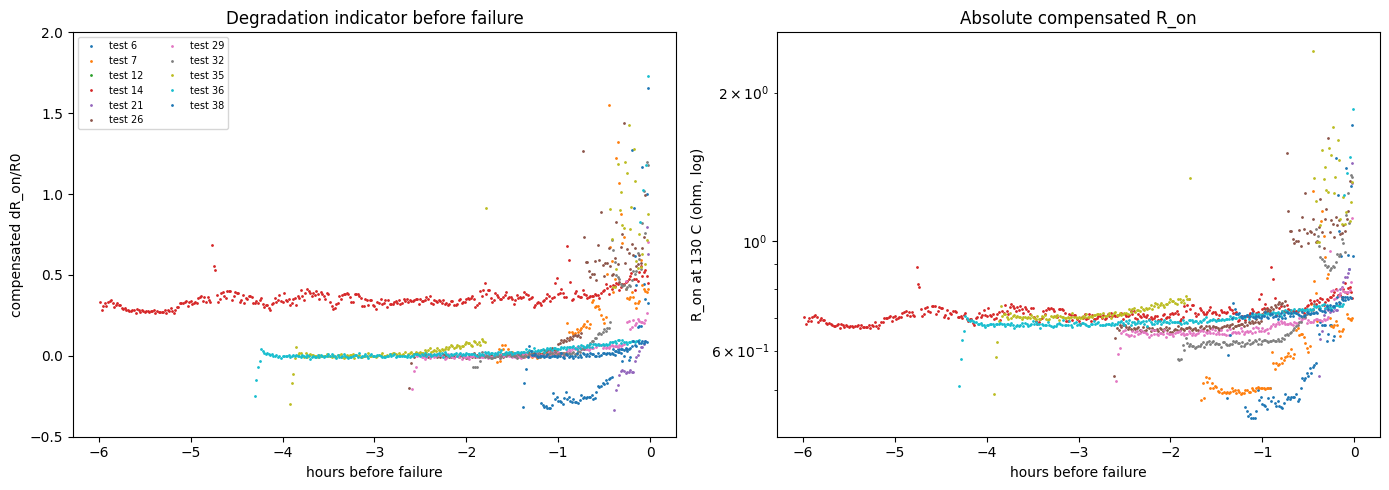

In [88]:
# CELL 85: Compensated ON-phase R_on trajectories, aligned to time-to-failure
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DUTY = 0.40
K_RON = 2.84    # pooled R_on(T) exponent from Cell 82 (tests 8, 9, 11, 12, 14)
voff = fr[~fr["on"]].groupby(["test_id", "run_id"])["drainSourceVoltage"].median().rename("V_off").reset_index()
onr = fr[fr["on"] & (fr["drainSourceVoltage"] > 0)].merge(voff, on=["test_id", "run_id"], how="left")
wf5 = (onr.groupby(["test_id", "min"])
       .agg(stress_h=("stress_h", "mean"), v_avg=("drainSourceVoltage", "median"), i_avg=("drainCurrent", "median"),
            V_off=("V_off", "first"), pkgT=("packageTemperature", "median"), n=("drainCurrent", "size")).reset_index())
wf5["R_on"] = (wf5["v_avg"] - (1 - DUTY) * wf5["V_off"]) / wf5["i_avg"]
wf5 = wf5[(wf5["n"] >= 5) & (wf5["R_on"] > 0.05) & (wf5["pkgT"] > 20)].copy()
wf5["R_comp"] = wf5["R_on"] * (403.15 / (wf5["pkgT"] + 273.15)) ** K_RON

out = []
for t, g in wf5.groupby("test_id"):
    g = g.sort_values("stress_h").copy()
    tfail = fail_tbl.loc[t, "t_fail_h"]
    pre = g[g["stress_h"] <= (tfail if np.isfinite(tfail) else g["stress_h"].max())]
    if len(pre) < 6:
        continue
    lo = 0.3 * tfail if np.isfinite(tfail) else 0
    Tmed = pre[pre["stress_h"] >= lo]["pkgT"].median()
    plateau = pre[pre["pkgT"] >= 0.9 * Tmed]
    k0 = min(5, len(plateau) // 4)
    R0 = plateau.iloc[k0:k0 + 20]["R_comp"].median()
    g["dRon"] = g["R_comp"] / R0 - 1
    g["ttf_h"] = g["stress_h"] - tfail if np.isfinite(tfail) else np.nan
    g["test_id"] = t; g["R0"] = R0
    out.append(g)
W5 = pd.concat(out, ignore_index=True)
W5.to_pickle("/kaggle/working/window_Ron_fail.pkl")

rows = []
for t, g in W5.groupby("test_id"):
    r = {"test_id": t, "R0_ohm_130C": g["R0"].iloc[0], "pre_fail_h": fail_tbl.loc[t, "t_fail_h"]}
    for lag in (1.0, 0.5, 0.17):
        s = g[(g["ttf_h"] > -lag - 0.1) & (g["ttf_h"] <= -lag)]["dRon"]
        r[f"dRon_{lag}h_before"] = s.median() if len(s) >= 3 else np.nan
    rows.append(r)
display(pd.DataFrame(rows).set_index("test_id").round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for t, g in W5.groupby("test_id"):
    gg = g[(g["ttf_h"] > -6) & (g["ttf_h"] < 0.05)]
    axes[0].plot(gg["ttf_h"], gg["dRon"], ".", ms=2, label=f"test {t}")
    axes[1].semilogy(gg["ttf_h"], gg["R_comp"], ".", ms=2)
axes[0].set(xlabel="hours before failure", ylabel="compensated dR_on/R0", ylim=(-0.5, 2.0), title="Degradation indicator before failure")
axes[0].legend(fontsize=7, ncol=2)
axes[1].set(xlabel="hours before failure", ylabel="R_on at 130 C (ohm, log)", title="Absolute compensated R_on")
plt.tight_layout(); plt.show()

,test_id,life_h,pkgT_plateau,status,shutdownTemp
0,6,1.19,153.13,failed,300.0
1,7,1.67,174.45,failed,300.0
2,12,12.91,133.57,censored,280.0
3,14,10.09,134.77,failed,280.0
4,21,0.39,135.75,failed,260.0
5,26,2.63,127.26,failed,240.0
6,29,2.59,126.53,failed,230.0
7,32,1.93,123.65,failed,240.0
8,35,3.92,92.07,failed,260.0
9,36,4.31,120.38,failed,260.0


Arrhenius-style fit on 10 failed devices: Ea = 0.19 eV, R^2 = 0.11 (case temperature, mixed stress settings: treat as a rough indication only)


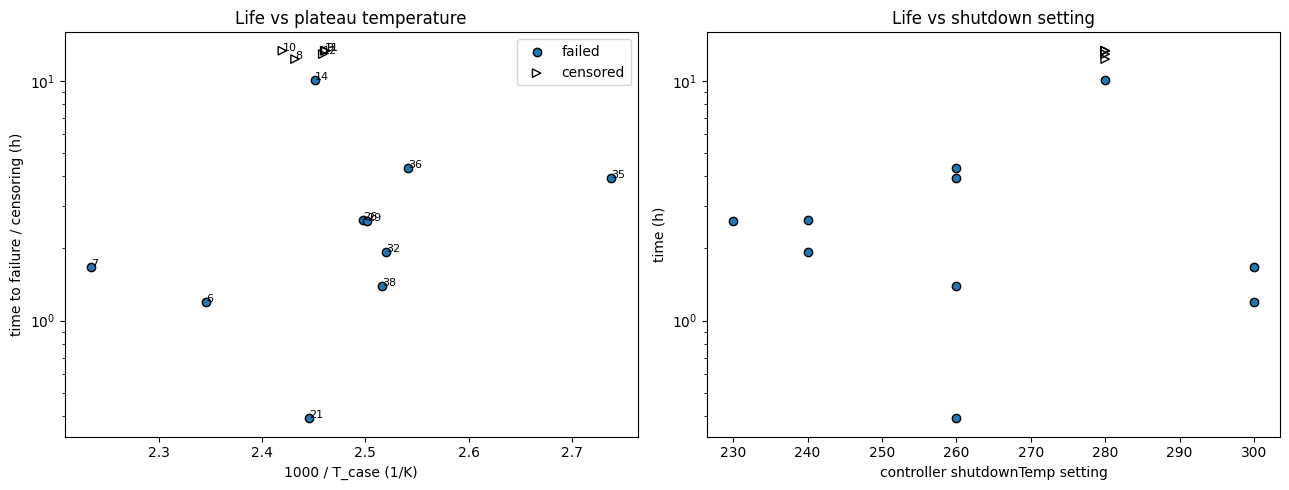

In [89]:
# CELL 86: Failure time vs operating temperature (Arrhenius-style life check) and vs controller setting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

KB = 8.617e-5   # eV/K
ft = fail_tbl.copy()
ft["status"] = np.where(np.isfinite(ft["t_fail_h"]), "failed", "censored")
ft["life_h"] = ft["t_fail_h"].fillna(ft["total_h"])

# add the censored 8-14 group devices from the earlier analysis (no failure observed)
cens = []
for t in (8, 9, 10, 11):
    g = rec_df[(rec_df["test_id"] == t) & (rec_df["stress_h"] > 3)]
    cens.append({"test_id": t, "life_h": float(rec_df[rec_df["test_id"] == t]["stress_h"].max()),
                 "pkgT_plateau": float(g["packageTemperature"].median()), "status": "censored",
                 "shutdownTemp": 280.0})
allt = pd.concat([ft.reset_index()[["test_id", "life_h", "pkgT_plateau", "status", "shutdownTemp"]],
                  pd.DataFrame(cens)], ignore_index=True)
display(allt.round(2))

f = allt[allt["status"] == "failed"].dropna(subset=["pkgT_plateau", "life_h"])
if len(f) >= 4:
    x = 1.0 / (KB * (f["pkgT_plateau"] + 273.15)); y = np.log(f["life_h"])
    slope, icpt = np.polyfit(x, y, 1)
    r2 = np.corrcoef(x, y)[0, 1] ** 2
    print(f"Arrhenius-style fit on {len(f)} failed devices: Ea = {slope:.2f} eV, R^2 = {r2:.2f} "
          "(case temperature, mixed stress settings: treat as a rough indication only)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for status, mk, fc in (("failed", "o", None), ("censored", ">", "none")):
    d = allt[allt["status"] == status]
    axes[0].scatter(1000.0 / (d["pkgT_plateau"] + 273.15), d["life_h"], marker=mk, facecolors=fc, edgecolors="k", label=status)
    axes[1].scatter(d["shutdownTemp"], d["life_h"], marker=mk, facecolors=fc, edgecolors="k", label=status)
    for _, r in d.iterrows():
        axes[0].annotate(int(r["test_id"]), (1000.0 / (r["pkgT_plateau"] + 273.15), r["life_h"]), fontsize=8)
axes[0].set(yscale="log", xlabel="1000 / T_case (1/K)", ylabel="time to failure / censoring (h)", title="Life vs plateau temperature")
axes[1].set(yscale="log", xlabel="controller shutdownTemp setting", ylabel="time (h)", title="Life vs shutdown setting")
axes[0].legend(); plt.tight_layout(); plt.show()

In [91]:
# CELL 87: Threshold-based EOL vs functional failure: lead times and false alarms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

fail_tbl2 = fail_tbl.copy()
fail_tbl2.loc[12, "t_fail_h"] = 12.108     # from Cell 77 (sustained loss of switching-current swing)
fail_tbl2.loc[12, "post_fail_h"] = fail_tbl2.loc[12, "total_h"] - 12.108

def build_indicator(tbl, K=2.84, DUTY=0.40):
    voff = fr[~fr["on"]].groupby(["test_id", "run_id"])["drainSourceVoltage"].median().rename("V_off").reset_index()
    onr = fr[fr["on"] & (fr["drainSourceVoltage"] > 0)].merge(voff, on=["test_id", "run_id"], how="left")
    w_ = (onr.groupby(["test_id", "min"])
          .agg(stress_h=("stress_h", "mean"), v_avg=("drainSourceVoltage", "median"), i_avg=("drainCurrent", "median"),
               V_off=("V_off", "first"), pkgT=("packageTemperature", "median"), n=("drainCurrent", "size")).reset_index())
    w_["R_on"] = (w_["v_avg"] - (1 - DUTY) * w_["V_off"]) / w_["i_avg"]
    w_ = w_[(w_["n"] >= 5) & (w_["R_on"] > 0.05) & (w_["pkgT"] > 20)].copy()
    w_["R_comp"] = w_["R_on"] * (403.15 / (w_["pkgT"] + 273.15)) ** K
    out = []
    for t, g in w_.groupby("test_id"):
        g = g.sort_values("stress_h").copy()
        tfail = tbl.loc[t, "t_fail_h"]
        pre = g[g["stress_h"] <= tfail]
        if len(pre) < 6:
            continue
        Tmed = pre[pre["stress_h"] >= 0.3 * tfail]["pkgT"].median()
        plateau = pre[pre["pkgT"] >= 0.9 * Tmed]
        k0 = min(5, len(plateau) // 4)
        R0 = plateau.iloc[k0:k0 + 20]["R_comp"].median()
        g["dRon"] = g["R_comp"] / R0 - 1
        g["ttf_h"] = g["stress_h"] - tfail
        g["test_id"] = t; g["R0"] = R0
        out.append(g)
    return pd.concat(out, ignore_index=True)

W5 = build_indicator(fail_tbl2)
W5.to_pickle("/kaggle/working/window_Ron_fail.pkl")
print("Devices with indicator:", sorted(W5["test_id"].unique()))

THRS = [0.05, 0.10, 0.20, 0.30, 0.50]
rows = []
for t, g in W5.groupby("test_id"):
    g = g.sort_values("stress_h")
    sm = g.set_index("stress_h")["dRon"].rolling(10, min_periods=6).median()
    tfail = fail_tbl2.loc[t, "t_fail_h"]
    pre = sm[(sm.index <= tfail) & (sm.index > g["stress_h"].min() + 0.1)]
    r = {"test_id": t, "t_fail_h": tfail, "dRon_at_failure": g[(g["ttf_h"] > -0.25) & (g["ttf_h"] <= 0)]["dRon"].median()}
    for th in THRS:
        hit = pre[pre >= th]
        r[f"lead_{int(th*100)}pct_h"] = tfail - hit.index[0] if len(hit) else np.nan
    rows.append(r)
lead = pd.DataFrame(rows).set_index("test_id")
print("Lead time (h) between first threshold crossing and true failure; NaN = threshold never crossed before failure")
display(lead.round(3))
print("\nSpread of dR_on at failure: min %.2f, median %.2f, max %.2f" % (
    lead["dRon_at_failure"].min(), lead["dRon_at_failure"].median(), lead["dRon_at_failure"].max()))

# false alarms on censored devices (tests 8-11) using the Cell 82 indicator w2
fa = []
for t in (8, 9, 10, 11):
    g = w2[w2["test_id"] == t].sort_values("stress_h")
    sm = g.set_index("stress_h")["dRon_rel"].rolling(10, min_periods=6).median()
    sm = sm[sm.index > g["stress_h"].min() + 0.1]
    r = {"test_id": t, "observed_h": g["stress_h"].max(), "dRon_final": sm.iloc[-30:].median()}
    for th in THRS:
        hit = sm[sm >= th]
        r[f"first_cross_{int(th*100)}pct_h"] = hit.index[0] if len(hit) else np.nan
    fa.append(r)
print("\nCensored devices (no failure observed): when thresholds were crossed anyway (false alarms)")
display(pd.DataFrame(fa).set_index("test_id").round(3))

Devices with indicator: [np.int64(6), np.int64(7), np.int64(12), np.int64(14), np.int64(21), np.int64(26), np.int64(29), np.int64(32), np.int64(35), np.int64(36), np.int64(38)]
Lead time (h) between first threshold crossing and true failure; NaN = threshold never crossed before failure


,t_fail_h,dRon_at_failure,lead_5pct_h,lead_10pct_h,lead_20pct_h,lead_30pct_h,lead_50pct_h
test_id,,,,,,,
6,1.192,0.442,0.133,0.133,0.084,0.084,NaN
7,1.675,0.378,0.833,0.817,0.583,0.400,0.350
12,12.108,0.291,7.983,7.883,7.133,0.035,NaN
14,10.092,0.492,7.717,7.550,6.917,6.017,0.050
21,0.392,0.006,0.018,NaN,NaN,NaN,NaN
26,2.625,0.635,0.934,0.817,0.667,0.667,0.650
29,2.592,0.212,0.534,0.200,0.133,NaN,NaN
32,1.925,0.569,0.633,0.533,0.350,0.350,0.099
35,3.925,0.754,2.117,0.400,0.400,0.384,0.349



Spread of dR_on at failure: min 0.01, median 0.38, max 0.75

Censored devices (no failure observed): when thresholds were crossed anyway (false alarms)


,observed_h,dRon_final,first_cross_5pct_h,first_cross_10pct_h,first_cross_20pct_h,first_cross_30pct_h,first_cross_50pct_h
test_id,,,,,,,
8,12.304,0.757,2.408,2.442,2.808,5.391,9.125
9,13.325,0.368,3.742,4.258,7.575,9.345,NaN
10,13.336,0.371,0.158,0.158,0.158,0.158,0.158
11,13.324,0.225,4.492,5.408,9.393,NaN,NaN


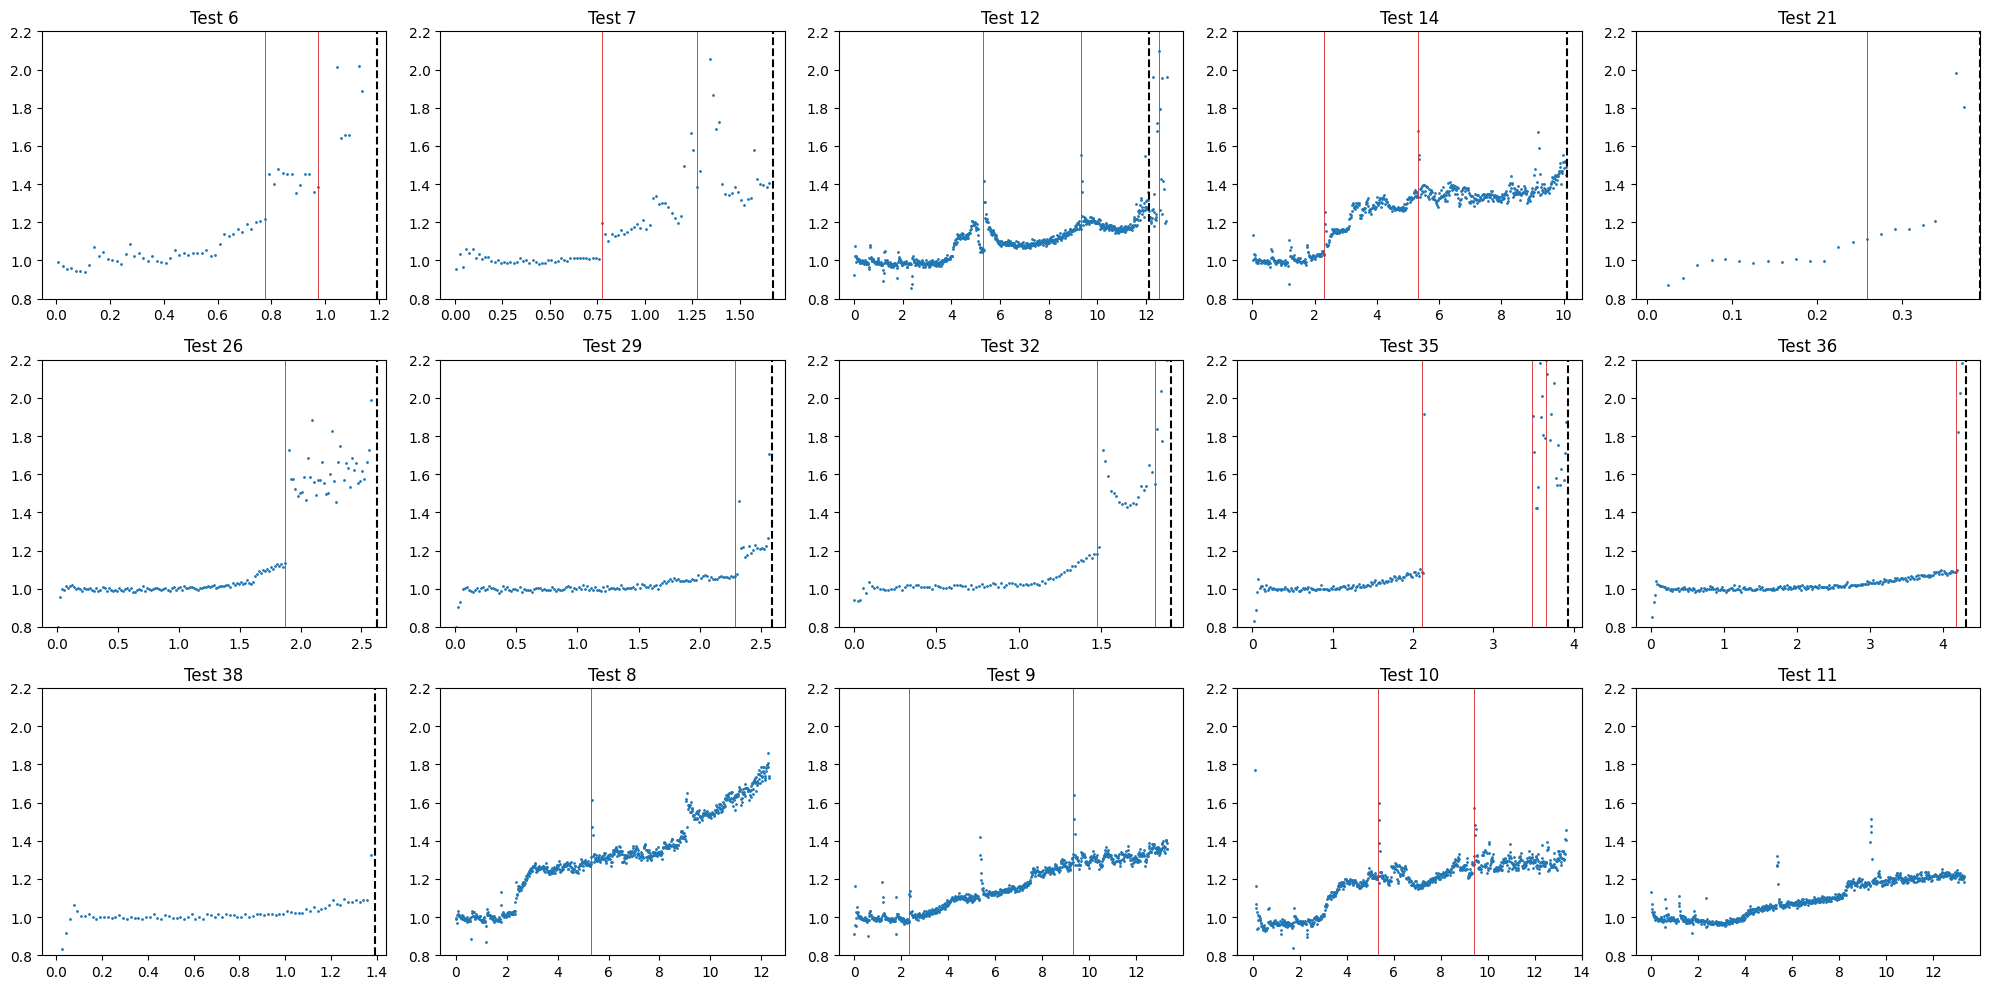

,n_steps,status,steps(time_h:jump),hours_before_fail_of_last_step
test_id,,,,
6,2,failed,0.78:0.22; 0.97:0.62,0.217873
7,2,failed,0.78:0.13; 1.28:0.30,0.399878
12,3,failed,5.31:0.24; 9.32:0.15; 12.52:0.45,-0.416744
14,2,failed,2.29:0.11; 5.31:0.14,4.786612
21,1,failed,0.26:0.16,0.133181
26,1,failed,1.88:0.40,0.749865
29,1,failed,2.29:0.14,0.300207
32,2,failed,1.48:0.37; 1.83:0.20,0.099460
35,3,failed,2.11:0.76; 3.48:0.58; 3.66:0.12,0.268860


Steps are relative increases > 0.08 in the 5-min median of compensated R_on. Red lines = detected steps, dashed = failure.


In [92]:
# CELL 88: Are there discrete step increases in R_on before failure (vs smooth growth)?
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

STEP = 0.08      # relative jump in compensated R_on
WIN = 5          # windows (minutes) either side

run_starts = {}
for df_ in (fr, rec_df):
    for (t, r), g in df_.groupby(["test_id", "run_id"]):
        run_starts.setdefault(t, set()).add(round(float(g["stress_h"].min()), 3))

def detect_steps(g):
    g = g.sort_values("stress_h").reset_index(drop=True)
    x = g["R_comp"].values; t = g["stress_h"].values
    steps = []
    for i in range(WIN, len(x) - WIN):
        before = np.median(x[i - WIN:i]); after = np.median(x[i:i + WIN])
        d = after / before - 1
        if d > STEP:
            steps.append((t[i], d))
    merged = []
    for ts, d in steps:           # merge detections within 10 minutes, keep the largest
        if merged and ts - merged[-1][0] < 10 / 60:
            if d > merged[-1][1]:
                merged[-1] = (ts, d)
        else:
            merged.append((ts, d))
    return merged

sources = [(t, g, fail_tbl2.loc[t, "t_fail_h"]) for t, g in W5.groupby("test_id")]
sources += [(t, w2[w2["test_id"] == t], np.nan) for t in (8, 9, 10, 11)]

rows = []
fig, axes = plt.subplots(3, 5, figsize=(20, 10))
for ax, (t, g, tfail) in zip(axes.ravel(), sources):
    g = g.sort_values("stress_h")
    st = detect_steps(g)
    starts = run_starts.get(t, set())
    st = [(ts, d) for ts, d in st if all(not (0 <= ts - s0 < 0.2) for s0 in starts)]
    rows.append({"test_id": t, "n_steps": len(st), "status": "failed" if np.isfinite(tfail) else "censored",
                 "steps(time_h:jump)": "; ".join(f"{ts:.2f}:{d:.2f}" for ts, d in st[:8]),
                 "hours_before_fail_of_last_step": (tfail - st[-1][0]) if (st and np.isfinite(tfail)) else np.nan})
    ref = g["R_comp"].iloc[:20].median()
    ax.plot(g["stress_h"], g["R_comp"] / ref, ".", ms=2)
    for ts, d in st:
        ax.axvline(ts, color="tab:red", lw=0.6)
    if np.isfinite(tfail):
        ax.axvline(tfail, color="k", ls="--")
    ax.set_title(f"Test {t}"); ax.set_ylim(0.8, 2.2)
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("test_id"))
print("Steps are relative increases >", STEP, "in the 5-min median of compensated R_on. Red lines = detected steps, dashed = failure.")

In [93]:
# CELL 89: Master device table for the study design
import numpy as np
import pandas as pd
from IPython.display import display

cohort = {21: "A", 26: "A", 29: "A", 32: "A", 35: "A", 36: "A", 38: "A",
          8: "B", 9: "B", 10: "B", 11: "B", 12: "B", 14: "B", 6: "C", 7: "C"}
notes = {35: "current dropped ~2.1h, cooled, resumed ~3.5h, final collapse ~3.9h (intermittent?)",
         6: "temperature-ramped test; baseline unreliable", 7: "temperature-ramped test",
         10: "transient current channel unusable", 21: "very short life (~23 min of plateau)"}

rows = []
for t, c in cohort.items():
    failed = t in fail_tbl2.index and np.isfinite(fail_tbl2.loc[t, "t_fail_h"])
    if failed:
        life = fail_tbl2.loc[t, "t_fail_h"]
        g5 = W5[W5["test_id"] == t]
        d_end = g5[(g5["ttf_h"] > -0.25) & (g5["ttf_h"] <= 0)]["dRon"].median() if len(g5) else np.nan
        r0 = g5["R0"].iloc[0] if len(g5) else np.nan
        T = fail_tbl2.loc[t, "pkgT_plateau"]; n_runs = int(fail_tbl2.loc[t, "n_runs"])
        sd = fail_tbl2.loc[t, "shutdownTemp"]
    else:
        g = w2[w2["test_id"] == t].sort_values("stress_h")
        life = g["stress_h"].max()
        d_end = g["dRon_rel"].iloc[-30:].median(); r0 = np.nan
        T = g[g["stress_h"] > 3]["pkgT"].median(); n_runs = int(rec_df[rec_df["test_id"] == t]["run_id"].nunique())
        sd = float(ctrl_df[ctrl_df["test_id"] == t]["shutdownTemp"].median())
    rows.append({"test_id": t, "cohort": c, "status": "failed" if failed else "censored", "life_or_censor_h": life,
                 "n_runs": n_runs, "shutdownTemp": sd, "pkgT_plateau": T, "R0_ohm_130C": r0,
                 "dRon_at_end": d_end, "note": notes.get(t, "")})
master = pd.DataFrame(rows).set_index("test_id").sort_values(["cohort", "life_or_censor_h"])
master.to_csv("/kaggle/working/device_table.csv")
display(master.round(3))
print(master.groupby(["cohort", "status"]).size().unstack(fill_value=0))
print("\nSaved: /kaggle/working/device_table.csv")

,cohort,status,life_or_censor_h,n_runs,shutdownTemp,pkgT_plateau,R0_ohm_130C,dRon_at_end,note
test_id,,,,,,,,,
21,A,failed,0.392,1,260.0,135.749,0.803,0.006,very short life (~23 min of plateau)
38,A,failed,1.392,1,260.0,124.297,0.705,0.079,
32,A,failed,1.925,1,240.0,123.648,0.619,0.569,
29,A,failed,2.592,1,230.0,126.529,0.652,0.212,
26,A,failed,2.625,1,240.0,127.265,0.664,0.635,
35,A,failed,3.925,1,260.0,92.075,0.701,0.754,"current dropped ~2.1h, cooled, resumed ~3.5h, ..."
36,A,failed,4.308,1,260.0,120.384,0.679,0.092,
14,B,failed,10.092,7,280.0,134.766,0.527,0.492,
12,B,failed,12.108,7,280.0,133.568,0.530,0.291,


status  censored  failed
cohort                  
A              0       7
B              4       2
C              0       2

Saved: /kaggle/working/device_table.csv


In [94]:
# CELL 90: Build the clean modelling dataset (one row per minute-window per device)
import numpy as np
import pandas as pd
from IPython.display import display

meta = master.copy()
primary_ids = [26, 29, 32, 36, 38]

starts = {}
for df_ in (fr, rec_df):
    for (t, r), g in df_.groupby(["test_id", "run_id"]):
        starts.setdefault(t, set()).add(round(float(g["stress_h"].min()), 3))

frames = []
for t in meta.index:
    if meta.loc[t, "status"] == "failed":
        g = W5[W5["test_id"] == t][["test_id", "stress_h", "dRon", "R_comp", "pkgT", "i_avg", "ttf_h"]].copy()
        life = float(fail_tbl2.loc[t, "t_fail_h"])
        g = g[g["stress_h"] <= life]
    else:
        g = (w2[w2["test_id"] == t][["test_id", "stress_h", "dRon_rel", "R_comp", "pkgT", "i_avg"]]
             .rename(columns={"dRon_rel": "dRon"}).copy())
        g["ttf_h"] = np.nan
        life = float(g["stress_h"].max())
    g = g.sort_values("stress_h")
    t0 = g["stress_h"].min()
    ok = g["stress_h"] > t0 + 0.20                      # start-up transient
    for s0 in starts.get(t, []):
        if s0 > 0.01:                                   # run boundaries of multi-run tests
            ok &= ~((g["stress_h"] - s0 >= -0.05) & (g["stress_h"] - s0 <= 0.25))
    g = g[ok].copy()
    g["cohort"] = meta.loc[t, "cohort"]; g["status"] = meta.loc[t, "status"]
    g["life_h"] = life; g["primary"] = t in primary_ids
    frames.append(g)

ds = pd.concat(frames, ignore_index=True)
ds.to_csv("/kaggle/working/model_dataset.csv", index=False)
summ = (ds.groupby("test_id").agg(cohort=("cohort", "first"), status=("status", "first"), primary=("primary", "first"),
                                   life_h=("life_h", "first"), n_windows=("dRon", "size"),
                                   dRon_last=("dRon", lambda s: s.iloc[-10:].median())).round(3))
display(summ)
print("Saved: /kaggle/working/model_dataset.csv  rows:", len(ds))

,cohort,status,primary,life_h,n_windows,dRon_last
test_id,,,,,,
6,C,failed,False,1.192,44,0.041
7,C,failed,False,1.675,88,0.399
8,B,censored,False,12.304,619,0.793
9,B,censored,False,13.325,680,0.378
10,B,censored,False,13.336,681,0.405
11,B,censored,False,13.324,679,0.219
12,B,failed,False,12.108,606,0.308
14,B,failed,False,10.092,484,0.493
21,A,failed,False,0.392,11,0.054


Saved: /kaggle/working/model_dataset.csv  rows: 4739


In [95]:
# CELL 91: Baseline RUL methods, leave-one-device-out, evaluated 1h / 0.5h / 0.25h before failure
import numpy as np
import pandas as pd
from IPython.display import display

LAGS = [1.0, 0.5, 0.25]
FIT_H = 0.5
CAP_H = 12.0

failed = ds[ds["status"] == "failed"]
life = failed.groupby("test_id")["life_h"].first()
level = (failed[(failed["ttf_h"] > -0.25) & (failed["ttf_h"] <= 0)].groupby("test_id")["dRon"].median().dropna())

def baselines(t, lag):
    tp = life[t] - lag
    h = ds[(ds["test_id"] == t) & (ds["stress_h"] <= tp)].sort_values("stress_h")
    if len(h) < 15 or (tp - h["stress_h"].min()) < 0.3:
        return None
    train = [x for x in life.index if x != t and x in level.index]
    theta = float(level.loc[train].median()); life_med = float(life.loc[train].median())
    cur = float(h["dRon"].iloc[-5:].median())
    rec = h[h["stress_h"] > tp - FIT_H]
    out = {"test_id": t, "lag_h": lag, "true_RUL_h": lag, "theta": theta, "current_dRon": cur}
    out["pop_life"] = max(life_med - tp, 0.0)
    slope = np.polyfit(rec["stress_h"], rec["dRon"], 1)[0] if len(rec) >= 5 else np.nan
    out["linear"] = 0.0 if cur >= theta else (CAP_H if not np.isfinite(slope) or slope <= 1e-4 else min((theta - cur) / slope, CAP_H))
    b = np.polyfit(rec["stress_h"], np.log1p(rec["dRon"].clip(lower=-0.5)), 1)[0] if len(rec) >= 5 else np.nan
    out["exponential"] = 0.0 if cur >= theta else (CAP_H if not np.isfinite(b) or b <= 1e-4 else min(np.log((1 + theta) / (1 + cur)) / b, CAP_H))
    return out

rows = [r for t in life.index for lag in LAGS if (r := baselines(t, lag))]
bl = pd.DataFrame(rows)
bl["cohort"] = bl["test_id"].map(meta["cohort"]); bl["primary"] = bl["test_id"].isin(primary_ids)
for m in ("pop_life", "linear", "exponential"):
    bl[f"err_{m}"] = (bl[m] - bl["true_RUL_h"]).abs()
display(bl.round(3))

print("\nMean absolute error (h) by lag, all evaluated devices vs primary cohort A (n=5):")
for name, sub in (("ALL", bl), ("PRIMARY", bl[bl["primary"]])):
    print(name)
    display(sub.groupby("lag_h")[["err_pop_life", "err_linear", "err_exponential"]].mean().round(3))
bl.to_pickle("/kaggle/working/baseline_results.pkl")

,test_id,lag_h,true_RUL_h,theta,current_dRon,pop_life,linear,exponential,cohort,primary,err_pop_life,err_linear,err_exponential
0,6,0.50,0.50,0.335,-0.186,1.917,3.100,2.244,C,False,1.417,2.600,1.744
1,6,0.25,0.25,0.335,0.040,1.667,0.396,0.293,C,False,1.417,0.146,0.043
2,7,1.00,1.00,0.291,0.019,1.950,7.173,6.285,C,False,0.950,6.173,5.285
3,7,0.50,0.50,0.291,0.288,1.450,0.005,0.005,C,False,0.950,0.495,0.495
4,7,0.25,0.25,0.291,0.698,1.200,0.000,0.000,C,False,0.950,0.250,0.250
5,12,1.00,1.00,0.378,0.178,0.000,12.000,12.000,B,False,1.000,11.000,11.000
6,12,0.50,0.50,0.378,0.228,0.000,1.276,1.188,B,False,0.500,0.776,0.688
7,12,0.25,0.25,0.378,0.302,0.000,0.309,0.286,B,False,0.250,0.059,0.036
8,14,1.00,1.00,0.291,0.381,0.000,0.000,0.000,B,False,1.000,1.000,1.000
9,14,0.50,0.50,0.291,0.376,0.000,0.000,0.000,B,False,0.500,0.500,0.500



Mean absolute error (h) by lag, all evaluated devices vs primary cohort A (n=5):
ALL


,err_pop_life,err_linear,err_exponential
lag_h,,,
0.25,0.537,1.226,1.069
0.50,0.637,3.589,3.379
1.00,0.715,6.760,6.154


PRIMARY


,err_pop_life,err_linear,err_exponential
lag_h,,,
0.25,0.450,2.260,1.972
0.50,0.500,4.005,3.772
1.00,0.442,6.226,5.236


In [96]:
# CELL 92: Paper-style GPR extrapolation with 90% bounds (same LODO protocol)
import warnings
import numpy as np
import pandas as pd
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C
from IPython.display import display
warnings.filterwarnings("ignore")

HIST_H = 2.0
GRID = np.arange(0.0, CAP_H, 0.02)
Z = 1.645

def first_cross(grid, y, theta):
    idx = np.where(y >= theta)[0]
    return float(grid[idx[0]]) if len(idx) else CAP_H

rows = []
for t in life.index:
    for lag in LAGS:
        tp = life[t] - lag
        h = ds[(ds["test_id"] == t) & (ds["stress_h"] <= tp) & (ds["stress_h"] > tp - HIST_H)].sort_values("stress_h").iloc[::2]
        if len(h) < 15 or (tp - ds[(ds["test_id"] == t)]["stress_h"].min()) < 0.3:
            continue
        train = [x for x in life.index if x != t and x in level.index]
        theta = float(level.loc[train].median())
        x = (h["stress_h"].values - tp).reshape(-1, 1); y = h["dRon"].values
        gp = GaussianProcessRegressor(kernel=C(0.1, (1e-4, 10)) * RBF(0.5, (0.1, 5.0)) + WhiteKernel(1e-3, (1e-6, 1e-1)),
                                      normalize_y=True, n_restarts_optimizer=2, random_state=0)
        gp.fit(x, y)
        mu, sd = gp.predict(GRID.reshape(-1, 1), return_std=True)
        r_mean = first_cross(GRID, mu, theta)
        r_early = first_cross(GRID, mu + Z * sd, theta)      # optimistic-for-failure bound
        r_late = first_cross(GRID, mu - Z * sd, theta)       # pessimistic bound
        rows.append({"test_id": t, "lag_h": lag, "true_RUL_h": lag, "gpr_mean": r_mean, "gpr_lo": r_early, "gpr_hi": r_late,
                     "covered": r_early <= lag <= r_late, "width_h": r_late - r_early, "err_gpr": abs(r_mean - lag)})
gp_df = pd.DataFrame(rows)
gp_df["primary"] = gp_df["test_id"].isin(primary_ids)
display(gp_df.round(3))
for name, sub in (("ALL", gp_df), ("PRIMARY", gp_df[gp_df["primary"]])):
    print(name)
    display(sub.groupby("lag_h").agg(MAE_h=("err_gpr", "mean"), coverage=("covered", "mean"), median_width_h=("width_h", "median"),
                                      n=("covered", "size")).round(3))
gp_df.to_pickle("/kaggle/working/gpr_results.pkl")

,test_id,lag_h,true_RUL_h,gpr_mean,gpr_lo,gpr_hi,covered,width_h,err_gpr,primary
0,6,0.50,0.50,12.0,12.00,12.0,False,0.00,11.50,False
1,6,0.25,0.25,12.0,12.00,12.0,False,0.00,11.75,False
2,7,1.00,1.00,12.0,12.00,12.0,False,0.00,11.00,False
3,7,0.50,0.50,0.0,0.00,12.0,True,12.00,0.50,False
4,7,0.25,0.25,0.0,0.00,12.0,True,12.00,0.25,False
5,12,1.00,1.00,12.0,12.00,12.0,False,0.00,11.00,False
6,12,0.50,0.50,12.0,12.00,12.0,False,0.00,11.50,False
7,12,0.25,0.25,12.0,12.00,12.0,False,0.00,11.75,False
8,14,1.00,1.00,0.0,0.00,0.0,False,0.00,1.00,False
9,14,0.50,0.50,0.0,0.00,0.0,False,0.00,0.50,False


ALL


,MAE_h,coverage,median_width_h,n
lag_h,,,,
0.25,6.00,0.300,0.0,10
0.50,8.20,0.200,0.0,10
1.00,9.75,0.125,0.0,8


PRIMARY


,MAE_h,coverage,median_width_h,n
lag_h,,,,
0.25,7.15,0.4,0.0,5
0.50,9.30,0.0,0.0,5
1.00,11.00,0.0,0.0,4
